# Datasets accelerometer analysis

This notebooks objective is to analyze the accelerometer timeseries of three datasets. WISDM, PAMAP2 and Opportunity.

### Imports and declarations

In [16]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from scipy import stats
from scipy.stats import entropy
import datetime
from scipy.ndimage import label
from skimage.feature import graycomatrix, graycoprops


In [17]:
x_axis = 'accX'
y_axis = 'accY'
z_axis = 'accZ'

# x_axis = 'x_maf'
# y_axis = 'y_maf'
# z_axis = 'z_maf'

# x_axis = 'x_ema'
# y_axis = 'y_ema'
# z_axis = 'z_ema'

## Functions

In [18]:
def plot_laminarities(results):    
    # Prepare data for plotting
    thresholds = list(results.keys())
    mean_laminarities = {activity: [] for activity in results[thresholds[0]].keys()}

    for threshold in thresholds:
        for activity in mean_laminarities.keys():
            mean_laminarities[activity].append(results[threshold][activity])

    # Plotting
    plt.figure(figsize=(12, 6))

    for activity, values in mean_laminarities.items():
        plt.plot(thresholds, values, marker='o', label=activity)

    plt.title('Mean Laminarity vs. Thresholds')
    plt.xlabel('Threshold Value (Log Scale)')
    plt.ylabel('Mean Laminarity')
    plt.grid()
    plt.xticks(thresholds, rotation=45) 
    plt.xscale('log')
    plt.legend()
    plt.grid()
    plt.show()

In [19]:
def remove_outliers(data, threshold=3):
    """
    Remove outliers from a list of data using specified method.
    
    Parameters:
        data (list): List of numerical values from which to remove outliers.
        method (str): Method to use for outlier detection ('IQR' or 'Z-score').
        threshold (float): Threshold for Z-score method (default is 3).
    
    Returns:
        list: Data without outliers.
    """
    # Calculate the Z-scores of the data points
    z_scores = np.abs(stats.zscore(data))

    # Remove outliers
    return [x for i, x in enumerate(data) if z_scores[i] < threshold]

In [20]:
def plot_histogram(data, title, xlabel, ylabel, bins=30, color='blue', alpha=0.7, x_min=None, x_max=None):
    """
    Plot a histogram using Matplotlib.
    
    Parameters:
    - data: array-like, the input data for the histogram.
    - title: str, the title of the plot.
    - xlabel: str, the label for the x-axis.
    - ylabel: str, the label for the y-axis.
    - bins: int, the number of bins for the histogram (default is 30).
    - color: str, the color of the bars (default is blue).
    - alpha: float, the transparency level of the bars (default is 0.7).
    """
    plt.figure(figsize=(10, 6))
    plt.hist(data, bins=bins, color=color, alpha=alpha)
    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    if x_min is not None and x_max is not None:
        plt.xlim(x_min, x_max)
    plt.grid(True)
    plt.show()

In [21]:
def calculate_matrix_determinant(matrix):
    """
    Calculate the determinant of a given matrix.

    Parameters:
    matrix (list of lists or np.ndarray): The input matrix.

    Returns:
    float: The determinant of the matrix.
    """
    # Convert the input to a NumPy array if it's not already
    matrix_np = np.array(matrix)
    
    # Calculate the determinant
    determinant = np.linalg.det(matrix_np)
    
    return determinant


In [22]:
def calculate_matrix_laminarity(recurrence_matrix, min_line_length=2):
    """
    Calculate the laminarity (LAM) of a binary recurrence matrix, ensuring values are normalized between 0 and 1.
    
    Parameters:
    - recurrence_matrix: np.ndarray
        Binary matrix representing the recurrence plot (1s indicate recurrence).
    - min_line_length: int, default=2
        Minimum length of vertical lines to be considered in the laminarity calculation.
        
    Returns:
    - laminarity: float
        The laminarity value of the recurrence plot, normalized between 0 and 1.
    """
    # Transpose the matrix to count vertical lines as horizontal for easier processing
    transposed_matrix = recurrence_matrix.T

    # Label contiguous ones in each column (now rows) of the transposed matrix
    labeled_matrix, num_features = label(transposed_matrix)

    # Get the lengths of each vertical line segment
    line_lengths = []
    for feature_num in range(1, num_features + 1):
        line_length = np.sum(labeled_matrix == feature_num)
        if line_length >= min_line_length:
            line_lengths.append(line_length)

    # Calculate laminarity
    if not line_lengths:  # Avoid division by zero if there are no valid line segments
        return 0.0

    # Sum of points in all qualifying vertical lines
    total_vertical_points = sum(line_lengths)
    # Total number of recurrence points
    total_recurrence_points = np.sum(recurrence_matrix)

    # Normalize laminarity between 0 and 1
    laminarity = total_vertical_points / total_recurrence_points
    return laminarity

In [23]:
def find_laminarities(recurrence_function, threshold, vectors, window_size, step, start, min_line_length=2):
    laminarities = []
    
    for i in range(start, len(vectors) - window_size + 1, step):
        window_vectors = vectors[i:i + window_size]
        rec_matrix = recurrence_function(window_vectors, threshold)
        matrix_laminarity = calculate_matrix_laminarity(rec_matrix, min_line_length)
        laminarities.append(matrix_laminarity)
        
    avg_determinant = np.mean(laminarities)
    laminarities.append(avg_determinant)
    
    return laminarities

In [24]:

def find_determinants(recurrence_function, vectors, window_size, step, start):
    determinants = []
    
    for i in range(start, len(vectors) - window_size + 1, step):
        window_vectors = vectors[i:i + window_size]
        rec_matrix = recurrence_function(window_vectors)
        matrix_determinant = calculate_matrix_determinant(rec_matrix)
        determinants.append(matrix_determinant)
        
    avg_determinant = np.mean(determinants)
    determinants.append(avg_determinant)
    
    return determinants



In [25]:
def calculate_weighted_descriptors(matrix, weights=None):
    """
    Calculate a weighted score using Haralick descriptors.

    Parameters:
    - matrix: np.array, the input recurrence matrix.
    - weights: dict, weights for each descriptor (default values provided).

    Returns:
    - weighted_score: float, the overall score combining descriptors.
    """
    descriptors = ["energy", "entropy", "contrast", "homogeneity", "correlation"]
    glcm = graycomatrix(matrix, distances=[1], angles=[0], levels=2, symmetric=True, normed=True)
    
    # Default weights
    if weights is None:
        weights = {
            "energy": 0.4,
            "entropy": 0.5,
            "contrast": 0.1,
            "homogeneity": -0.2,
            "correlation": 0.5
        }
    
    weighted_score = 0
    for desc in descriptors:
        if desc == "entropy":
            value = -np.sum(glcm * np.log2(glcm + 1e-10))
        else:
            value = graycoprops(glcm, desc)[0, 0]
        weighted_score += weights[desc] * value
    
    return weighted_score


In [26]:
def find_best_threshold_weighted(recurrence_function, threshold_list, vectors, window_size, step, start, weights=None):
    """
    Find the best threshold using weighted Haralick descriptors.

    Parameters:
    - recurrence_function: function, to calculate the recurrence matrix.
    - threshold_list: list, thresholds to evaluate.
    - vectors: np.array, array of vectors for a specific activity.
    - window_size: int, size of the window.
    - step: int, step between windows.
    - start: int, starting index for analysis.
    - weights: dict, weights for the descriptors.

    Returns:
    - best_threshold: float, threshold with the highest score.
    - all_scores: dict, scores for all thresholds.
    """
    best_threshold = None
    best_score = -np.inf
    all_scores = {}
    
    for threshold in threshold_list:
        scores = []
        
        for i in range(start, len(vectors) - window_size + 1, step):
            window_vectors = vectors[i:i + window_size]
            rec_matrix = recurrence_function(window_vectors, threshold)
            score = calculate_weighted_descriptors(rec_matrix, weights)
            scores.append(score)
        
        avg_score = np.mean(scores)
        all_scores[threshold] = avg_score
        
        if avg_score > best_score:
            best_score = avg_score
            best_threshold = threshold
    
    return best_threshold, all_scores


In [27]:

def calculate_matrix_entropy(matrix):
    """
    Calculate the entropy of a given matrix.
    
    Parameters:
    - matrix: np.array, the input matrix.
    
    Returns:
    - entropy_value: float, the entropy of the matrix.
    """
    # Flatten the matrix to a 1D array
    flat_matrix = matrix.flatten()
    
    # Calculate the histogram of the matrix values
    value_counts = np.bincount(flat_matrix)
    
    # Calculate the entropy
    entropy_value = entropy(value_counts, base=2)
    
    return entropy_value


In [28]:
def compute_haralick_descriptors(matrix, distances=[1], angles=[0, np.pi/4, np.pi/2, 3*np.pi/4]):
    """
    Compute Haralick descriptors for a given recurrence matrix.
    
    Parameters:
    - matrix: np.array, the recurrence matrix.
    - distances: list, distances for grey-level co-occurrence matrix (GLCM).
    - angles: list, angles for GLCM.
    
    Returns:
    - descriptors: dict, a dictionary of Haralick descriptors.
    """
    glcm = graycomatrix(matrix, distances, angles, symmetric=True, normed=True)
    descriptors = {
        'contrast': graycoprops(glcm, 'contrast').mean(),
        'dissimilarity': graycoprops(glcm, 'dissimilarity').mean(),
        'homogeneity': graycoprops(glcm, 'homogeneity').mean(),
        'energy': graycoprops(glcm, 'energy').mean(),
        'correlation': graycoprops(glcm, 'correlation').mean(),
        'ASM': graycoprops(glcm, 'ASM').mean(),
    }
    return descriptors

In [29]:
def find_haralick_values(recurrence_function, vectors, window_size, step, start):
    """
    Compute the Haralick descriptors and entropy for recurrence matrices for each activity.
    
    Parameters:
    - recurrence_function: function, the function to calculate the recurrence matrix.
    - vectors: np.array, the array of vectors for a specific activity.
    - window_size: int, the size of the window.
    - step: int, the step between windows.
    - start: int, the start index for windowing.
    
    Returns:
    - metrics_values: dict, a dictionary with lists of entropy values and Haralick descriptors.
    """
    entropies = []
    haralick_values = {
        'contrast': [],
        'dissimilarity': [],
        'homogeneity': [],
        'energy': [],
        'correlation': [],
        'ASM': [],
    }
    
    for i in range(start, len(vectors) - window_size + 1, step):
        # Extract window of vectors
        window_vectors = vectors[i:i + window_size]
        
        # Compute recurrence matrix
        rec_matrix = recurrence_function(window_vectors)
        
        # Compute entropy
        entropy = calculate_matrix_entropy(rec_matrix)
        entropies.append(entropy)
        
        # Compute Haralick descriptors
        haralick_desc = compute_haralick_descriptors(rec_matrix)
        
        # Append Haralick descriptors to their respective lists
        for key in haralick_values:
            haralick_values[key].append(haralick_desc[key])
    
    # Combine lists
    metrics_values = {
        'entropy': entropies,
        'haralick': haralick_values
    }
    
    return metrics_values


In [30]:
def find_metrics_average(recurrence_function, vectors, window_size, step, start):
    """
    Compute the average Haralick descriptors and entropy for recurrence matrices for each activity.
    
    Parameters:
    - recurrence_function: function, the function to calculate the recurrence matrix.
    - vectors: np.array, the array of vectors for a specific activity.
    - window_size: int, the size of the window.
    - step: int, the step between windows.
    - start: int, the start index for windowing.
    
    Returns:
    - avg_metrics: dict, a dictionary with the average entropy and average Haralick descriptors.
    """
    entropies = []
    haralick_sums = {
        'contrast': 0,
        'dissimilarity': 0,
        'homogeneity': 0,
        'energy': 0,
        'correlation': 0,
        'ASM': 0,
    }
    count = 0  # Number of windows processed
    
    for i in range(start, len(vectors) - window_size + 1, step):
        # Extract window of vectors
        window_vectors = vectors[i:i + window_size]
        
        # Compute recurrence matrix
        rec_matrix = recurrence_function(window_vectors)
        
        # Compute entropy
        entropy = calculate_matrix_entropy(rec_matrix)
        entropies.append(entropy)
        
        # Compute Haralick descriptors
        haralick_desc = compute_haralick_descriptors(rec_matrix)
        
        # Sum Haralick descriptors
        for key in haralick_sums:
            haralick_sums[key] += haralick_desc[key]
        
        count += 1
    
    # Compute averages
    avg_entropy = np.mean(entropies)
    avg_haralick = {key: value / count for key, value in haralick_sums.items()}
    
    # Combine averages
    avg_metrics = {
        'average_entropy': avg_entropy,
        'average_haralick': avg_haralick
    }
    
    return avg_metrics

In [ ]:
def plot_metric_matrix(metrics_dicts, activity_labels, metric_names=[
        'entropy', 
        'contrast', 
        'dissimilarity', 
        'homogeneity', 
        'energy', 
        'correlation', 
        'ASM'
    ]):
    """
    Plot a matrix of scatter plots for every pair of metrics across activities.
    
    Parameters:
    - metrics_dicts: list of dict, each containing metrics for an activity.
    - activity_labels: list of str, names of activities corresponding to metrics_dicts.
    - metric_names: list of str, names of the metrics to plot.
    """
    num_metrics = len(metric_names)
    
    # Define symbols and colors for activities
    symbols = ['o', 's', '^', 'D', 'v', 'P']  # Shapes for markers
    colors = plt.cm.tab10.colors  # Default colormap
    
    # Create the figure and axes for the matrix of plots
    fig, axes = plt.subplots(num_metrics, num_metrics, figsize=(15, 15))
    fig.subplots_adjust(hspace=0.5, wspace=0.5)  # Adjust spacing between plots
    
    # Iterate through the matrix
    for i, metric_x in enumerate(metric_names):
        for j, metric_y in enumerate(metric_names):
            ax = axes[i, j]
            
            if i == j:
                # Diagonal: show the metric name
                ax.text(0.5, 0.5, "")
                ax.set_xticks([])
                ax.set_yticks([])
                ax.set_facecolor('black')
            else:
                # Off-diagonal: scatter plot
                for idx, (metrics, activity) in enumerate(zip(metrics_dicts, activity_labels)):
                    if metric_x == "entropy":
                        x_values = metrics["entropy"]
                    else:
                        x_values = metrics["haralick"][metric_x]
                    
                    if metric_y == "entropy":
                        y_values = metrics["entropy"]
                    else:
                        y_values = metrics["haralick"][metric_y]
                    
                    ax.scatter(
                        x_values,
                        y_values,
                        label=activity,
                        color=colors[idx % len(colors)],
                        marker=symbols[idx % len(symbols)],
                        alpha=0.7,
                        edgecolor="k"
                    )
                
                # Add grid
                ax.grid(True, linestyle='--', alpha=0.6)
            
            # Remove tick labels to avoid clutter
            ax.set_xticks([])
            ax.set_yticks([])
    
    # Add row and column labels
    for i, metric in enumerate(metric_names):
        axes[0, i].set_title(metric.capitalize(), fontsize=12, pad=15)
        axes[i, 0].set_ylabel(metric.capitalize(), fontsize=12, rotation=0, labelpad=40, ha='right', va='center')
    
    # Add a single legend for activities
    handles = [plt.Line2D([], [], color=colors[idx % len(colors)], marker=symbols[idx % len(symbols)], 
                          linestyle='', label=activity) 
               for idx, activity in enumerate(activity_labels)]
    fig.legend(
        handles=handles,
        title="Activities",
        loc="upper center",
        ncol=len(activity_labels),
        bbox_to_anchor=(0.5, 1.05)
    )
    
    # Show the plot
    plt.tight_layout()
    plt.show()


In [32]:
def plot_metric_comparisons(metrics_dicts, activity_labels):
    """
    Plot separate charts comparing one metric across all activities.
    
    Parameters:
    - metrics_dicts: list of dict, each containing metrics for an activity.
    - activity_labels: list of str, names of activities corresponding to metrics_dicts.
    """
    # Extract entropy and Haralick metrics
    entropies = [metrics['average_entropy'] for metrics in metrics_dicts]
    haralick_metrics = {key: [] for key in metrics_dicts[0]['average_haralick']}
    
    # Collect Haralick metrics for each activity
    for metrics in metrics_dicts:
        for key, value in metrics['average_haralick'].items():
            haralick_metrics[key].append(value)
    
    # Create a plot for entropy
    plt.figure(figsize=(10, 6))
    plt.bar(activity_labels, entropies, color='skyblue', alpha=1)
    plt.title('Entropy Comparison Across Activities')
    plt.ylabel('Entropy')
    plt.xlabel('Activity')
    plt.grid(axis='y', linestyle='--', alpha=0.8)
    plt.tight_layout()
    plt.show()
    
    # Create a plot for each Haralick descriptor
    for descriptor, values in haralick_metrics.items():
        plt.figure(figsize=(10, 6))
        plt.bar(activity_labels, values, color='skyblue', alpha=1)
        plt.title(f'{descriptor.capitalize()} Comparison Across Activities')
        plt.ylabel(descriptor.capitalize())
        plt.xlabel('Activity')
        plt.grid(axis='y', linestyle='--', alpha=0.8)
        plt.tight_layout()
        plt.show()


In [33]:

def find_best_threshold(recurrence_function, threshold_list, vectors, window_size, step, start):
    """
    Find the best threshold based on the entropy of the generated recurrence matrices.
    
    Parameters:
    - recurrence_function: function, the function to calculate the recurrence matrix.
    - threshold_list: list, the list of thresholds to evaluate.
    - vectors: np.array, the array of vectors for a specific activity.
    - window_size: int, the size of the window.
    - step: int, the step between windows.
    
    Returns:
    - best_threshold: float, the threshold with the highest entropy.
    """
    best_threshold = None
    highest_entropy = -np.inf
    avg_entropies = []
    
    for threshold in threshold_list:
        entropies = []
        
        for i in range(start, len(vectors) - window_size + 1, step):
            window_vectors = vectors[i:i + window_size]
            rec_matrix = recurrence_function(window_vectors, threshold)
            matrix_entropy = calculate_matrix_entropy(rec_matrix)
            entropies.append(matrix_entropy)
        
        avg_entropy = np.mean(entropies)
        avg_entropies.append(avg_entropy)
        
        if avg_entropy > highest_entropy:
            highest_entropy = avg_entropy
            best_threshold = threshold
    
    return best_threshold, dict(zip(threshold_list, avg_entropies))



In [34]:
def distance_matrix(data):
    N = len(data)
    D = np.zeros((N, N))

    for i in range(N):
        for j in range(N):
            D[i, j] = np.linalg.norm(data[i] - data[j])

    return D


In [35]:

def calculate_distances_in_batches(vectors, batch_size=60):
    distances = []
    for start in range(0, len(vectors), batch_size):
        end = min(start + batch_size, len(vectors))
        batch_vectors = vectors[start:end]
        batch_distances = np.matrix.flatten(distance_matrix(batch_vectors))
        distances.append(batch_distances)
    return np.concatenate(distances)

In [36]:
def plot_time_series(data, title, min_y_limit=None, max_y_limit=None):
    plt.figure(figsize=(10, 6))
    sns.set_theme(style="darkgrid")  # Set seaborn style
    plt.plot(data)
    plt.title(title)
    plt.xlabel('Time')
    plt.ylabel('Value')
    if(min_y_limit is not None and max_y_limit is not None):
        plt.ylim(min_y_limit, max_y_limit)  # Set y-axis limits
    plt.grid(True)
    plt.show()

In [37]:
def plot_two_time_series(data1, label1, data2, label2, title, min_y_limit=None, max_y_limit=None):
    plt.figure(figsize=(10, 6))
    sns.set_theme(style="darkgrid")  # Set seaborn style
    plt.plot(data1, label=label1)
    plt.plot(data2, label=label2)
    plt.title(title)
    plt.xlabel('Time')
    plt.ylabel('Value')
    plt.legend()
    if(min_y_limit is not None and max_y_limit is not None):
        plt.ylim(min_y_limit, max_y_limit)  # Set y-axis limits
    plt.grid(True)
    plt.show()

In [38]:
def calculate_recurrence_plot_grayscale(time_series, bins=256):
    """
    Calculate the recurrence matrix for a given time series and convert it to a grayscale matrix.
    
    Parameters:
    - time_series: np.array or list, the input time series data.
    - bins: int, the number of bins to quantize the distance values (default is 256 for grayscale).
    
    Returns:
    - rec_matrix: np.array, the recurrence matrix in grayscale.
    """
    time_series = np.asarray(time_series)
    n = len(time_series)
    rec_matrix = np.zeros((n, n))
    
    # Compute distances between time series points
    for i in range(n):
        for j in range(n):
            distance = np.abs(time_series[i] - time_series[j])
            rec_matrix[i, j] = distance
    
    # Normalize the distance matrix to the range 0-255 and quantize to the given number of bins
    rec_matrix_normalized = (rec_matrix - rec_matrix.min()) / (rec_matrix.max() - rec_matrix.min())
    rec_matrix_grayscale = np.floor(rec_matrix_normalized * (bins - 1)) * (255 // (bins - 1))
    
    return rec_matrix_grayscale.astype(np.uint8)

In [39]:
def calculate_distance_matrix(time_series):
    """
    Calculate the recurrence matrix for a given time series.
    
    Parameters:
    - time_series: np.array or list, the input time series data.
    - threshold: float, the distance threshold for determining recurrence.
    
    Returns:
    - rec_matrix: np.array, the recurrence matrix.
    """
    time_series = np.asarray(time_series)
    n = len(time_series)
    rec_matrix = np.zeros((n, n))
    
    for i in range(n):
        for j in range(n):
            distance = np.abs(time_series[i] - time_series[j])
            rec_matrix[i, j] = distance
    
    return rec_matrix

In [40]:
def calculate_recurrence_plot(time_series, threshold=0.1):
    """
    Calculate the recurrence matrix for a given time series.
    
    Parameters:
    - time_series: np.array or list, the input time series data.
    - threshold: float, the distance threshold for determining recurrence.
    
    Returns:
    - rec_matrix: np.array, the recurrence matrix.
    """
    time_series = np.asarray(time_series)
    n = len(time_series)
    rec_matrix = np.zeros((n, n))
    
    for i in range(n):
        for j in range(n):
            distance = np.abs(time_series[i] - time_series[j])
            rec_matrix[i, j] = 1 if distance <= threshold else 0
    
    return rec_matrix

In [41]:
def plot_recurrence_matrix(rec_matrix, title, ax):
    """
    Plot the recurrence matrix using Seaborn and Matplotlib.
    
    Parameters:
    - rec_matrix: np.array, the recurrence matrix to be plotted.
    - title: str, title for the plot.
    - ax: matplotlib.axes.Axes, the axes to plot on.
    """
    sns.heatmap(rec_matrix, cmap="binary", square=True, ax=ax, cbar=False)
    
    # Set ticks to show numbers by 20s
    matrix_len = rec_matrix.shape[0]
    tick_labels = np.arange(0, matrix_len, 20)
    
    ax.set_xticks(tick_labels + 0.5)  # Adjust ticks to be centered
    ax.set_yticks(tick_labels + 0.5)
    ax.set_xticklabels(tick_labels, rotation=0)
    ax.set_yticklabels(tick_labels, rotation=0)

    ax.set_title(title)
    ax.set_xlabel("Time Index")
    ax.set_ylabel("Time Index")

In [42]:
def plot_two_recurrence_matrices(time_series1, time_series2, title1, title2, threshold=0.1):
    """
    Plot two recurrence matrices side-by-side for two time series.
    
    Parameters:
    - time_series1: np.array or list, the first time series data.
    - time_series2: np.array or list, the second time series data.
    - threshold: float, the distance threshold for determining recurrence.
    """
    # Calculate recurrence matrices
    rec_matrix1 = calculate_recurrence_plot(time_series1, threshold)
    rec_matrix2 = calculate_recurrence_plot(time_series2, threshold)
    
    # Create subplots
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 8))
    
    # Plot recurrence matrices
    plot_recurrence_matrix(rec_matrix1, title1, ax1)
    plot_recurrence_matrix(rec_matrix2, title2, ax2)
    
    plt.tight_layout()
    plt.show()

In [43]:
def recurrence_plot_vector_grayscale(data, bins=256):
    """
    Calculate the recurrence matrix for vector data and convert it to a grayscale matrix.
    
    Parameters:
    - data: np.array, the input data where each element is a vector.
    - bins: int, the number of bins to quantize the distance values (default is 256 for grayscale).
    
    Returns:
    - recurrence_matrix: np.array, the recurrence matrix in grayscale.
    """
    N = len(data)
    recurrence_matrix = np.zeros((N, N))

    # Calculate the Euclidean distance between vectors
    for i in range(N):
        for j in range(N):
            distance = np.linalg.norm(data[i] - data[j])
            recurrence_matrix[i, j] = distance

    # Normalize the distance matrix to the range 0-255 and quantize to the given number of bins
    recurrence_matrix_normalized = (recurrence_matrix - recurrence_matrix.min()) / (recurrence_matrix.max() - recurrence_matrix.min())
    recurrence_matrix_grayscale = np.floor(recurrence_matrix_normalized * (bins - 1)) * (255 // (bins - 1))
    
    return recurrence_matrix_grayscale.astype(np.uint8)

In [44]:
def recurrence_matrix_vector(data):
    N = len(data)
    recurrence_matrix = np.zeros((N, N))

    # Calculate the Euclidean distance between vectors
    for i in range(N):
        for j in range(i, N):
            distance = np.linalg.norm(data[i] - data[j])
            recurrence_matrix[i, j] = recurrence_matrix[j, i] = distance
                
    return recurrence_matrix

In [45]:
def recurrence_plot_vector(data, eps):
    N = len(data)
    recurrence_matrix = np.zeros((N, N))

    # Calculate the Euclidean distance between vectors
    for i in range(N):
        for j in range(i, N):
            distance = np.linalg.norm(data[i] - data[j])
            recurrence_matrix[i, j] = recurrence_matrix[j, i] = distance

    # Apply the threshold
    recurrence_matrix = (recurrence_matrix <= eps).astype(int)
    
    return recurrence_matrix

In [46]:
def plot_recurrence_matrix_vector(R, title, tick_jump = 20, filename=None):
    plt.figure(figsize=(8, 8))
    
    sns.heatmap(R, cmap="binary", square=True, cbar=False)

    # Set ticks to show numbers by 5s
    tick_labels = np.arange(0, R.shape[0], tick_jump)
    plt.xticks(ticks=tick_labels + 0.5, labels=tick_labels, rotation=0)
    plt.yticks(ticks=tick_labels + 0.5, labels=tick_labels, rotation=0)

    plt.title(title)
    plt.xlabel("Sample")
    plt.ylabel("Sample")

    if filename:
        plt.savefig(filename + ".png")  # Save the figure
        plt.close()  # Close the figure to prevent it from displaying
    else:
        plt.show()  # Show the figure

In [47]:
def plot_recurrence_by_activity_grayscale(data, bins, step, first=100, padding=2.0):
    num_keys = len(data)
    num_plots_per_key = 4
    fig, axes = plt.subplots(num_keys, num_plots_per_key, figsize=(20, 20))

    for i, (key, value) in enumerate(data.items()):
        start = first
        for j in range(num_plots_per_key):
            activity_data = value[start:start+step]
            R = recurrence_plot_vector_grayscale(activity_data, bins)
            ax = axes[i, j]
            cax = ax.matshow(R, cmap='binary')
            ax.set_title(f'{key} - Plot {j+1}')
            ax.set_xticks([])
            ax.set_yticks([])
            start = start + int(step/2)

    plt.tight_layout(pad=padding)  # Adjust padding
    plt.show()

In [48]:
def plot_recurrence_by_activity(data, dataset_name, axis_name, threshold, step, first=100, padding=2.0, filename=None):
    num_keys = len(data)
    num_plots_per_key = 4
    fig, axes = plt.subplots(num_keys, num_plots_per_key, figsize=(20, 20))
    
    # Extracting information from filename for the figure title
    figure_title = f'{dataset_name} - {axis_name} - {str(threshold)}'
    fig.suptitle(figure_title, fontsize=20, fontweight="bold")  # Set the figure title

    for i, (key, value) in enumerate(data.items()):
        start = first
        for j in range(num_plots_per_key):
            activity_data = value[start:start + step]
            R = recurrence_plot_vector(activity_data, threshold)
            ax = axes[i, j]
            cax = ax.matshow(R, cmap='binary')
            ax.set_title(f'{key} - Plot {j + 1}')
            ax.set_xticks([])
            ax.set_yticks([])
            start = start + int(step / 2)

    plt.tight_layout(pad=padding, rect=[0, 0, 1, 0.96])  # Adjust padding and fit the title

    if filename:
        plt.savefig(filename + ".png")  # Save the figure
        plt.close(fig)  # Close the figure to prevent it from displaying
    else:
        plt.show()  # Show the figure

## WISDM Dataset

### Dataset Preparation

In [49]:
# Function to normalize columns
def normalize_group(group):
    group[['x', 'y', 'z']] = (group[['x', 'y', 'z']] - group[['x', 'y', 'z']].mean()) / group[['x', 'y', 'z']].std()
    return group

wisdm = pd.read_csv('../../datasets/WISDM_ar_v1.1_balanced.csv', header=None, sep=',', names=['user', 'activity', 'timestamp', 'x', 'y', 'z'])
wisdm = wisdm.groupby('user').apply(normalize_group)
wisdm = wisdm.rename(columns={
    'x': 'accX',
    'y': 'accY',
    'z': 'accZ'
})
wisdm = wisdm.reset_index(drop=True)
wisdm

C:\Users\tulio\AppData\Local\Temp\ipykernel_22244\2392233564.py:7: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  wisdm = wisdm.groupby('user').apply(normalize_group)


,user,activity,timestamp,accX,accY,accZ
0,1,Walking,4992322339000,-0.091720,1.294345,-0.181997
1,1,Walking,4992422345000,0.390024,0.596599,-0.299797
2,1,Walking,4992722333000,1.040662,0.803481,0.175850
3,1,Walking,4993792341000,0.976051,0.650568,-0.224227
4,1,Walking,4993842298000,1.449861,0.680123,0.549256
...,...,...,...,...,...,...
290359,36,Standing,15049012250000,0.430103,0.422333,-0.155289
290360,36,Standing,15049062268000,0.330533,0.436234,-0.166769
290361,36,Standing,15049112287000,0.212525,0.439709,-0.155289
290362,36,Standing,15049162275000,0.002322,0.307651,-0.254785


In [50]:
wisdm[['x_maf', 'y_maf', 'z_maf']] = wisdm.groupby('user')[['accX', 'accY', 'accZ']].rolling(window=20).mean().reset_index(drop=True)
wisdm[['x_ema', 'y_ema', 'z_ema']] = wisdm.groupby('user')[['accX', 'accY', 'accZ']].ewm(span=30, adjust=False).mean().reset_index(drop=True)

In [51]:
wisdm

,user,activity,timestamp,accX,accY,accZ,x_maf,y_maf,z_maf,x_ema,y_ema,z_ema
0,1,Walking,4992322339000,-0.091720,1.294345,-0.181997,NaN,NaN,NaN,-0.091720,1.294345,-0.181997
1,1,Walking,4992422345000,0.390024,0.596599,-0.299797,NaN,NaN,NaN,-0.060640,1.249329,-0.189597
2,1,Walking,4992722333000,1.040662,0.803481,0.175850,NaN,NaN,NaN,0.010412,1.220565,-0.166020
3,1,Walking,4993792341000,0.976051,0.650568,-0.224227,NaN,NaN,NaN,0.072711,1.183791,-0.169775
4,1,Walking,4993842298000,1.449861,0.680123,0.549256,NaN,NaN,NaN,0.161560,1.151296,-0.123386
...,...,...,...,...,...,...,...,...,...,...,...,...
290359,36,Standing,15049012250000,0.430103,0.422333,-0.155289,0.292365,0.422941,-0.155480,0.291351,0.421061,-0.159292
290360,36,Standing,15049062268000,0.330533,0.436234,-0.166769,0.294762,0.423288,-0.156437,0.293879,0.422040,-0.159774
290361,36,Standing,15049112287000,0.212525,0.439709,-0.155289,0.291627,0.423810,-0.156437,0.288630,0.423180,-0.159485
290362,36,Standing,15049162275000,0.002322,0.307651,-0.254785,0.277614,0.417728,-0.161411,0.270159,0.415727,-0.165633


In [52]:
wisdm['user'].unique()

array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17,
       18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34,
       35, 36], dtype=int64)

In [53]:
wisdm[wisdm['user'] == 3]['activity'].unique()

array(['Walking', 'Jogging', 'Sitting', 'Standing', 'Upstairs',
       'Downstairs'], dtype=object)

In [54]:
walking_data = wisdm[(wisdm['activity'] == 'Walking') & (wisdm['user'] == 3)]
walking_vectors = walking_data[[x_axis, y_axis, z_axis]].to_numpy()

standing_data = wisdm[(wisdm['activity'] == 'Standing') & (wisdm['user'] == 3)]
standing_vectors = standing_data[[x_axis, y_axis, z_axis]].to_numpy()

sitting_data = wisdm[(wisdm['activity'] == 'Sitting') & (wisdm['user'] == 3)]
sitting_vectors = sitting_data[[x_axis, y_axis, z_axis]].to_numpy()

jogging_data = wisdm[(wisdm['activity'] == 'Jogging') & (wisdm['user'] == 3)]
jogging_vectors = jogging_data[[x_axis, y_axis, z_axis]].to_numpy()

upstairs_data = wisdm[(wisdm['activity'] == 'Upstairs') & (wisdm['user'] == 3)]
upstairs_vectors = upstairs_data[[x_axis, y_axis, z_axis]].to_numpy()

downstairs_data = wisdm[(wisdm['activity'] == 'Downstairs') & (wisdm['user'] == 3)]
downstairs_vectors = downstairs_data[[x_axis, y_axis, z_axis]].to_numpy()


start = 100
end = start + 40
threshold_axis = 0.003
threshold_vector = 0.002

print(len(walking_vectors)), print(len(standing_vectors)), print(len(sitting_vectors)), print(len(jogging_vectors)), print(len(upstairs_vectors)), print(len(downstairs_vectors))

1488
2824
1312
1607
1334
1534


(None, None, None, None, None, None)

In [55]:
print(walking_vectors[0])
print(standing_vectors[0])

[ 0.72253462  2.13897649 -0.58562868]
[-0.0020667   0.36303044 -0.38971351]


### Time-series plot

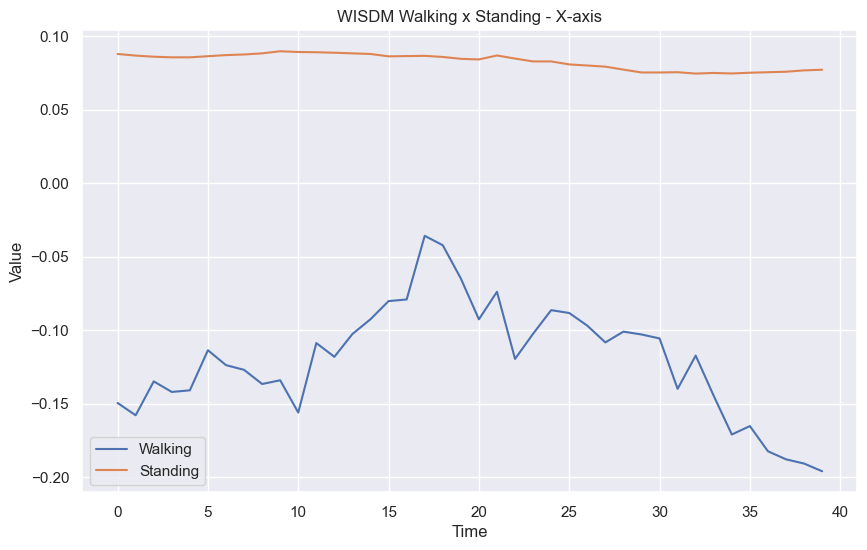

In [33]:
plot_two_time_series(walking_data[x_axis].iloc[start:end].reset_index(drop=True), "Walking", standing_data[x_axis].iloc[start:end].reset_index(drop=True), "Standing", 'WISDM Walking x Standing - X-axis')

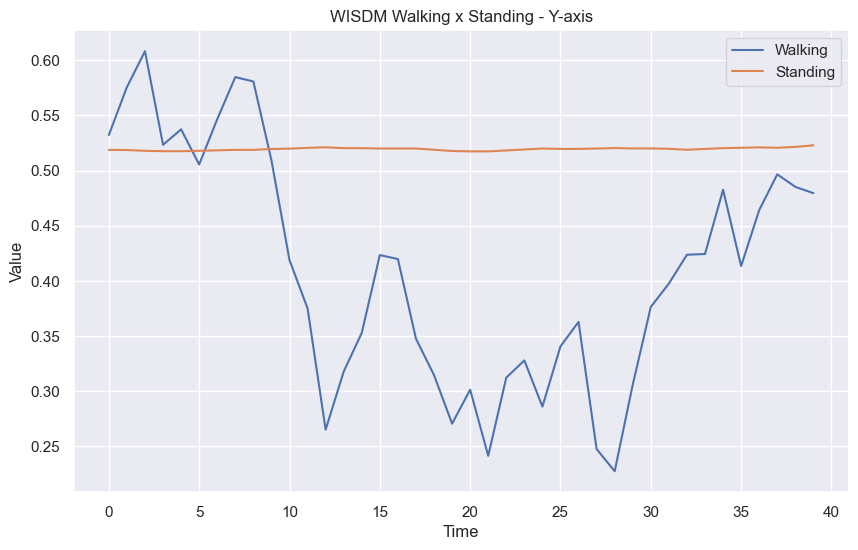

In [34]:
plot_two_time_series(walking_data[y_axis].iloc[start:end].reset_index(drop=True), "Walking", standing_data[y_axis].iloc[start:end].reset_index(drop=True), "Standing", 'WISDM Walking x Standing - Y-axis')

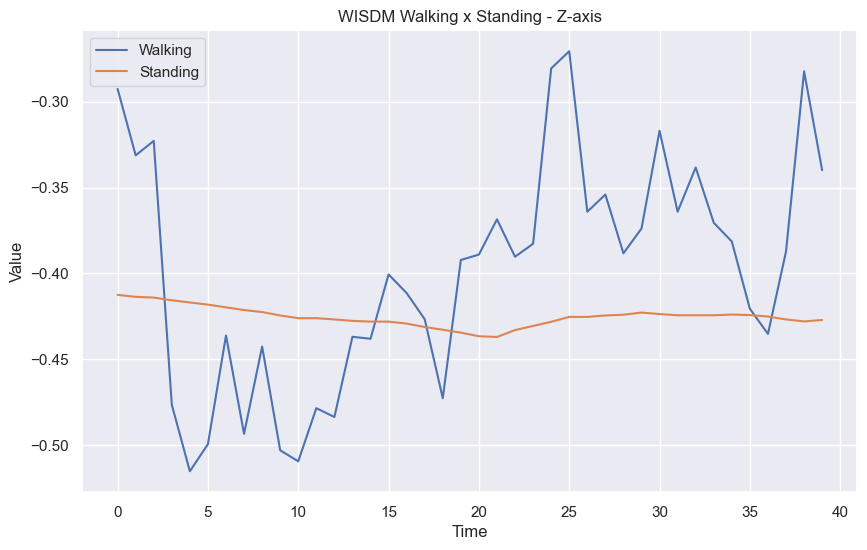

In [35]:
plot_two_time_series(walking_data[z_axis].iloc[start:end].reset_index(drop=True), "Walking", standing_data[z_axis].iloc[start:end].reset_index(drop=True), "Standing", 'WISDM Walking x Standing - Z-axis')

### Recurrence plot - Axis

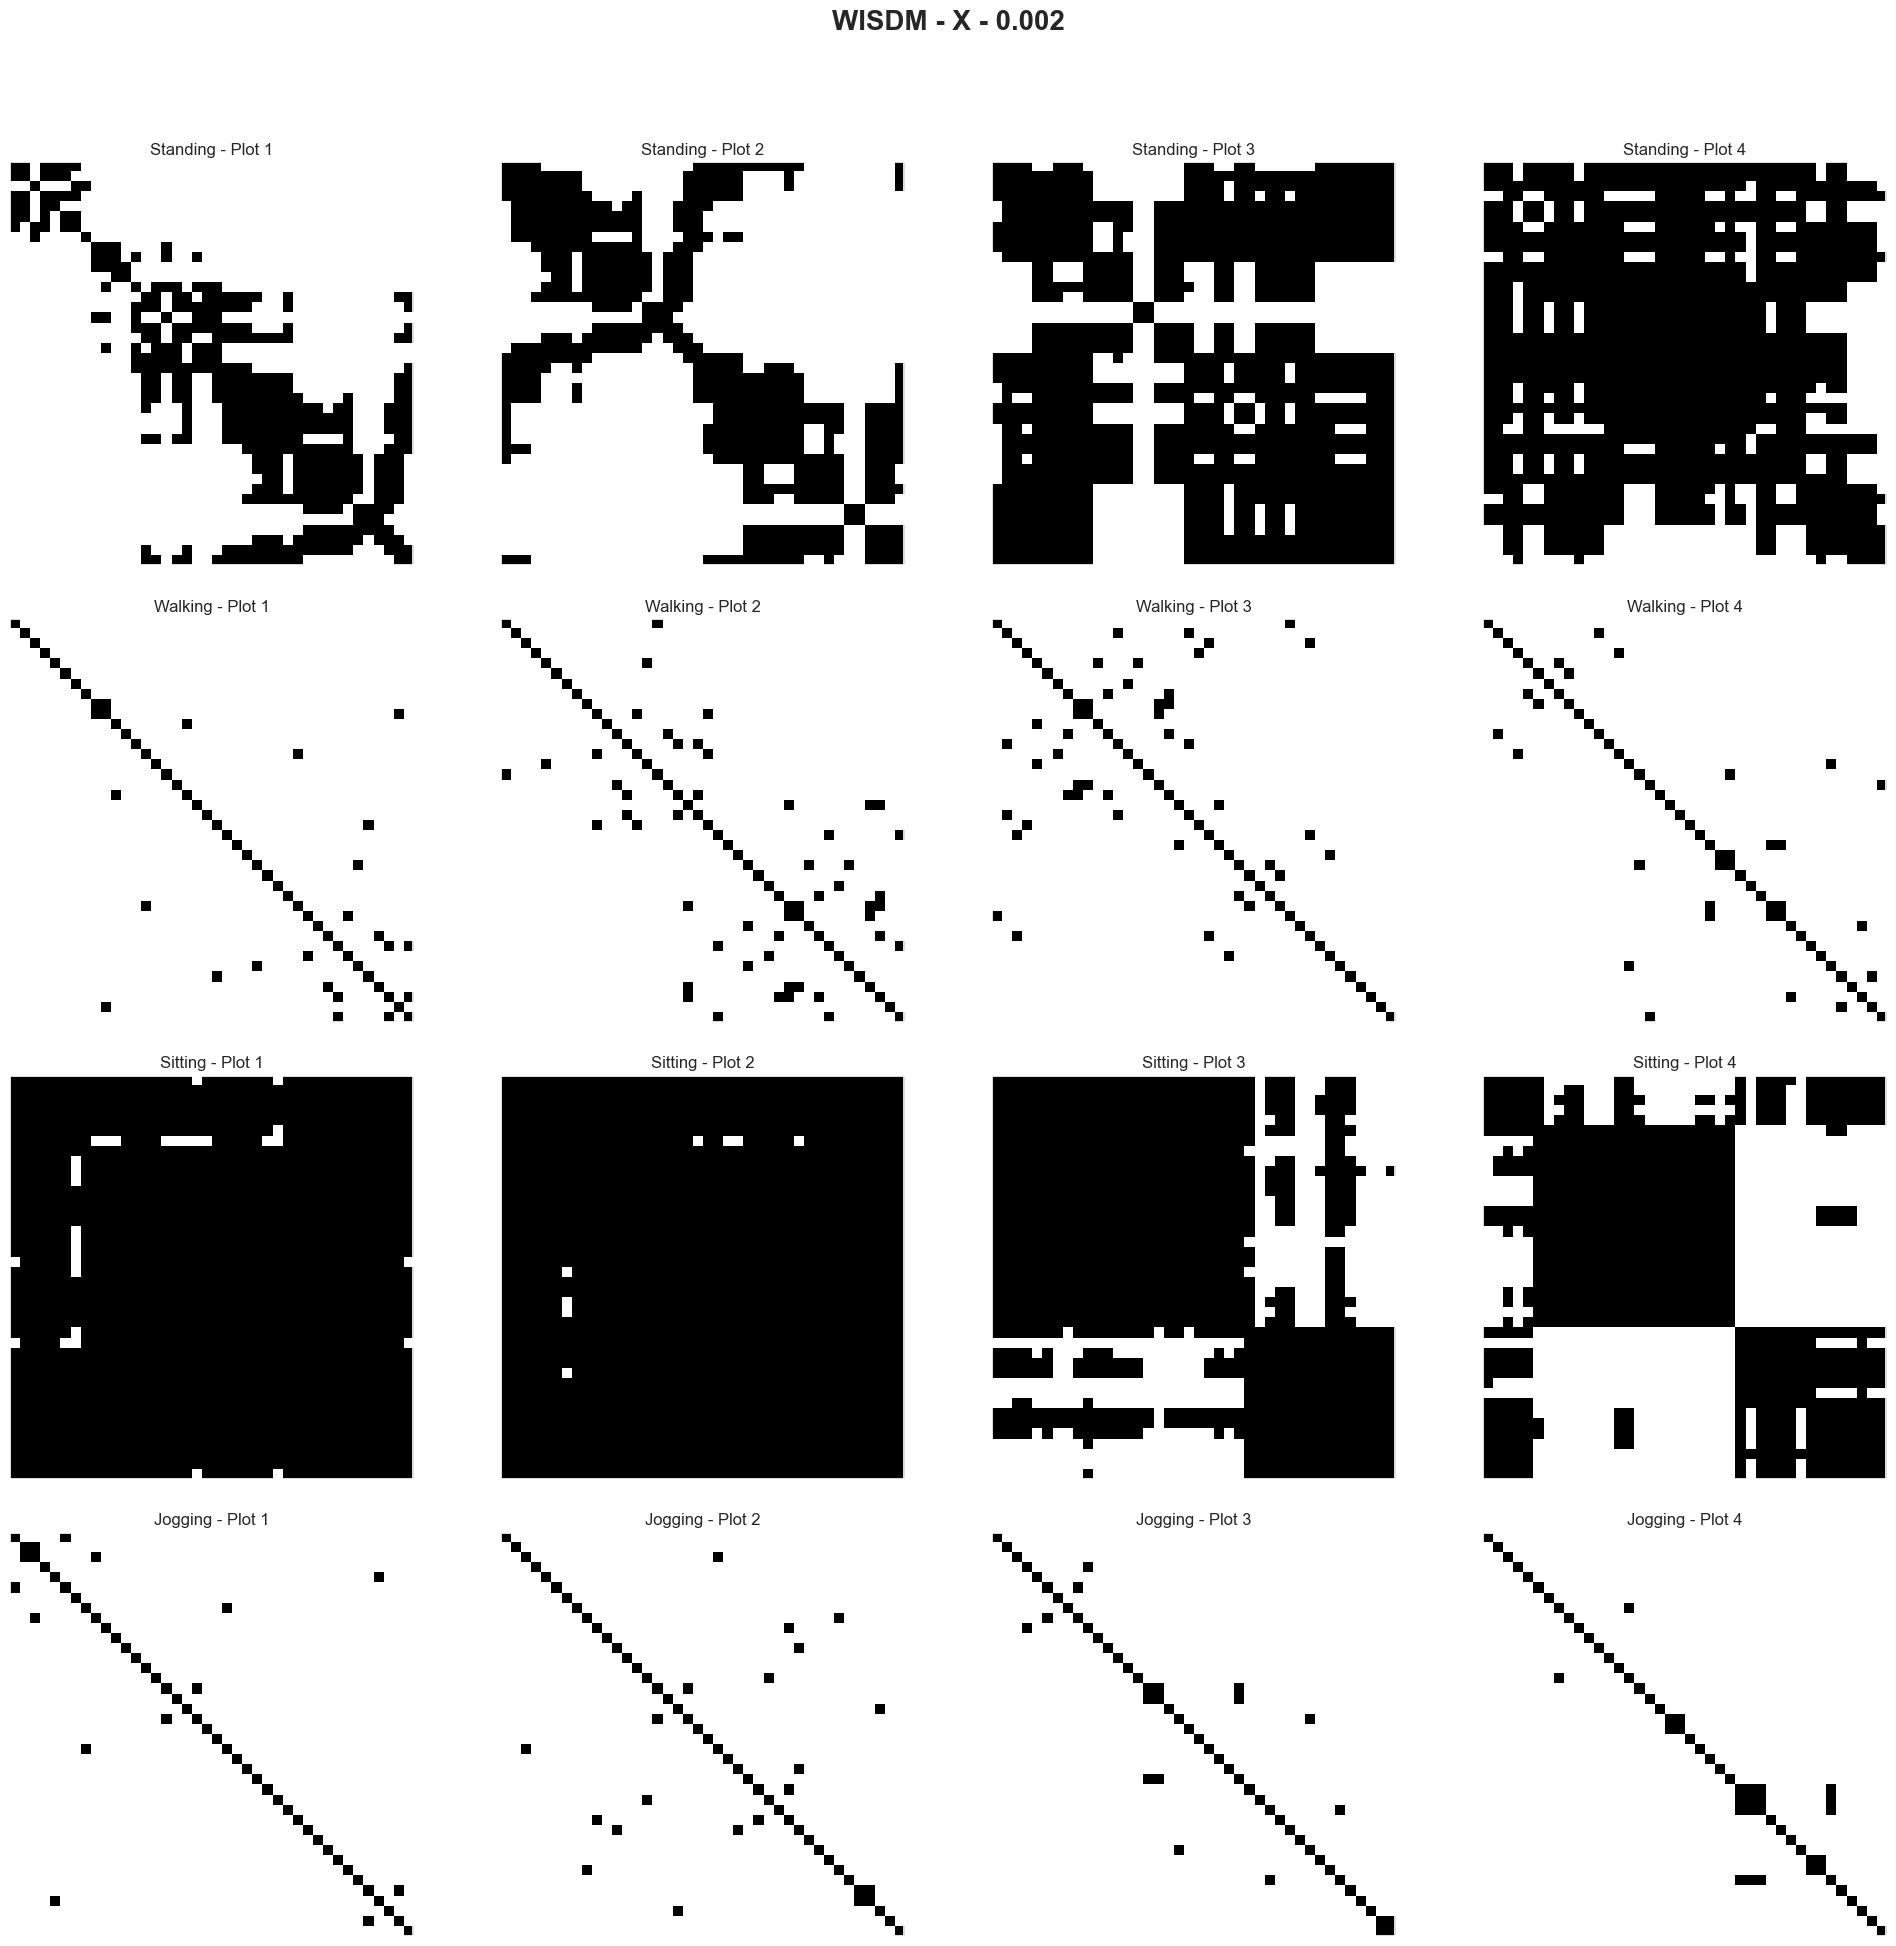

In [36]:
data = {"Standing": standing_data[x_axis].to_numpy(), "Walking": walking_data[x_axis].to_numpy(), "Sitting": sitting_data[x_axis].to_numpy(), "Jogging": jogging_data[x_axis].to_numpy()}

plot_recurrence_by_activity(data, "WISDM", "X",threshold_vector, step=40, first=200)

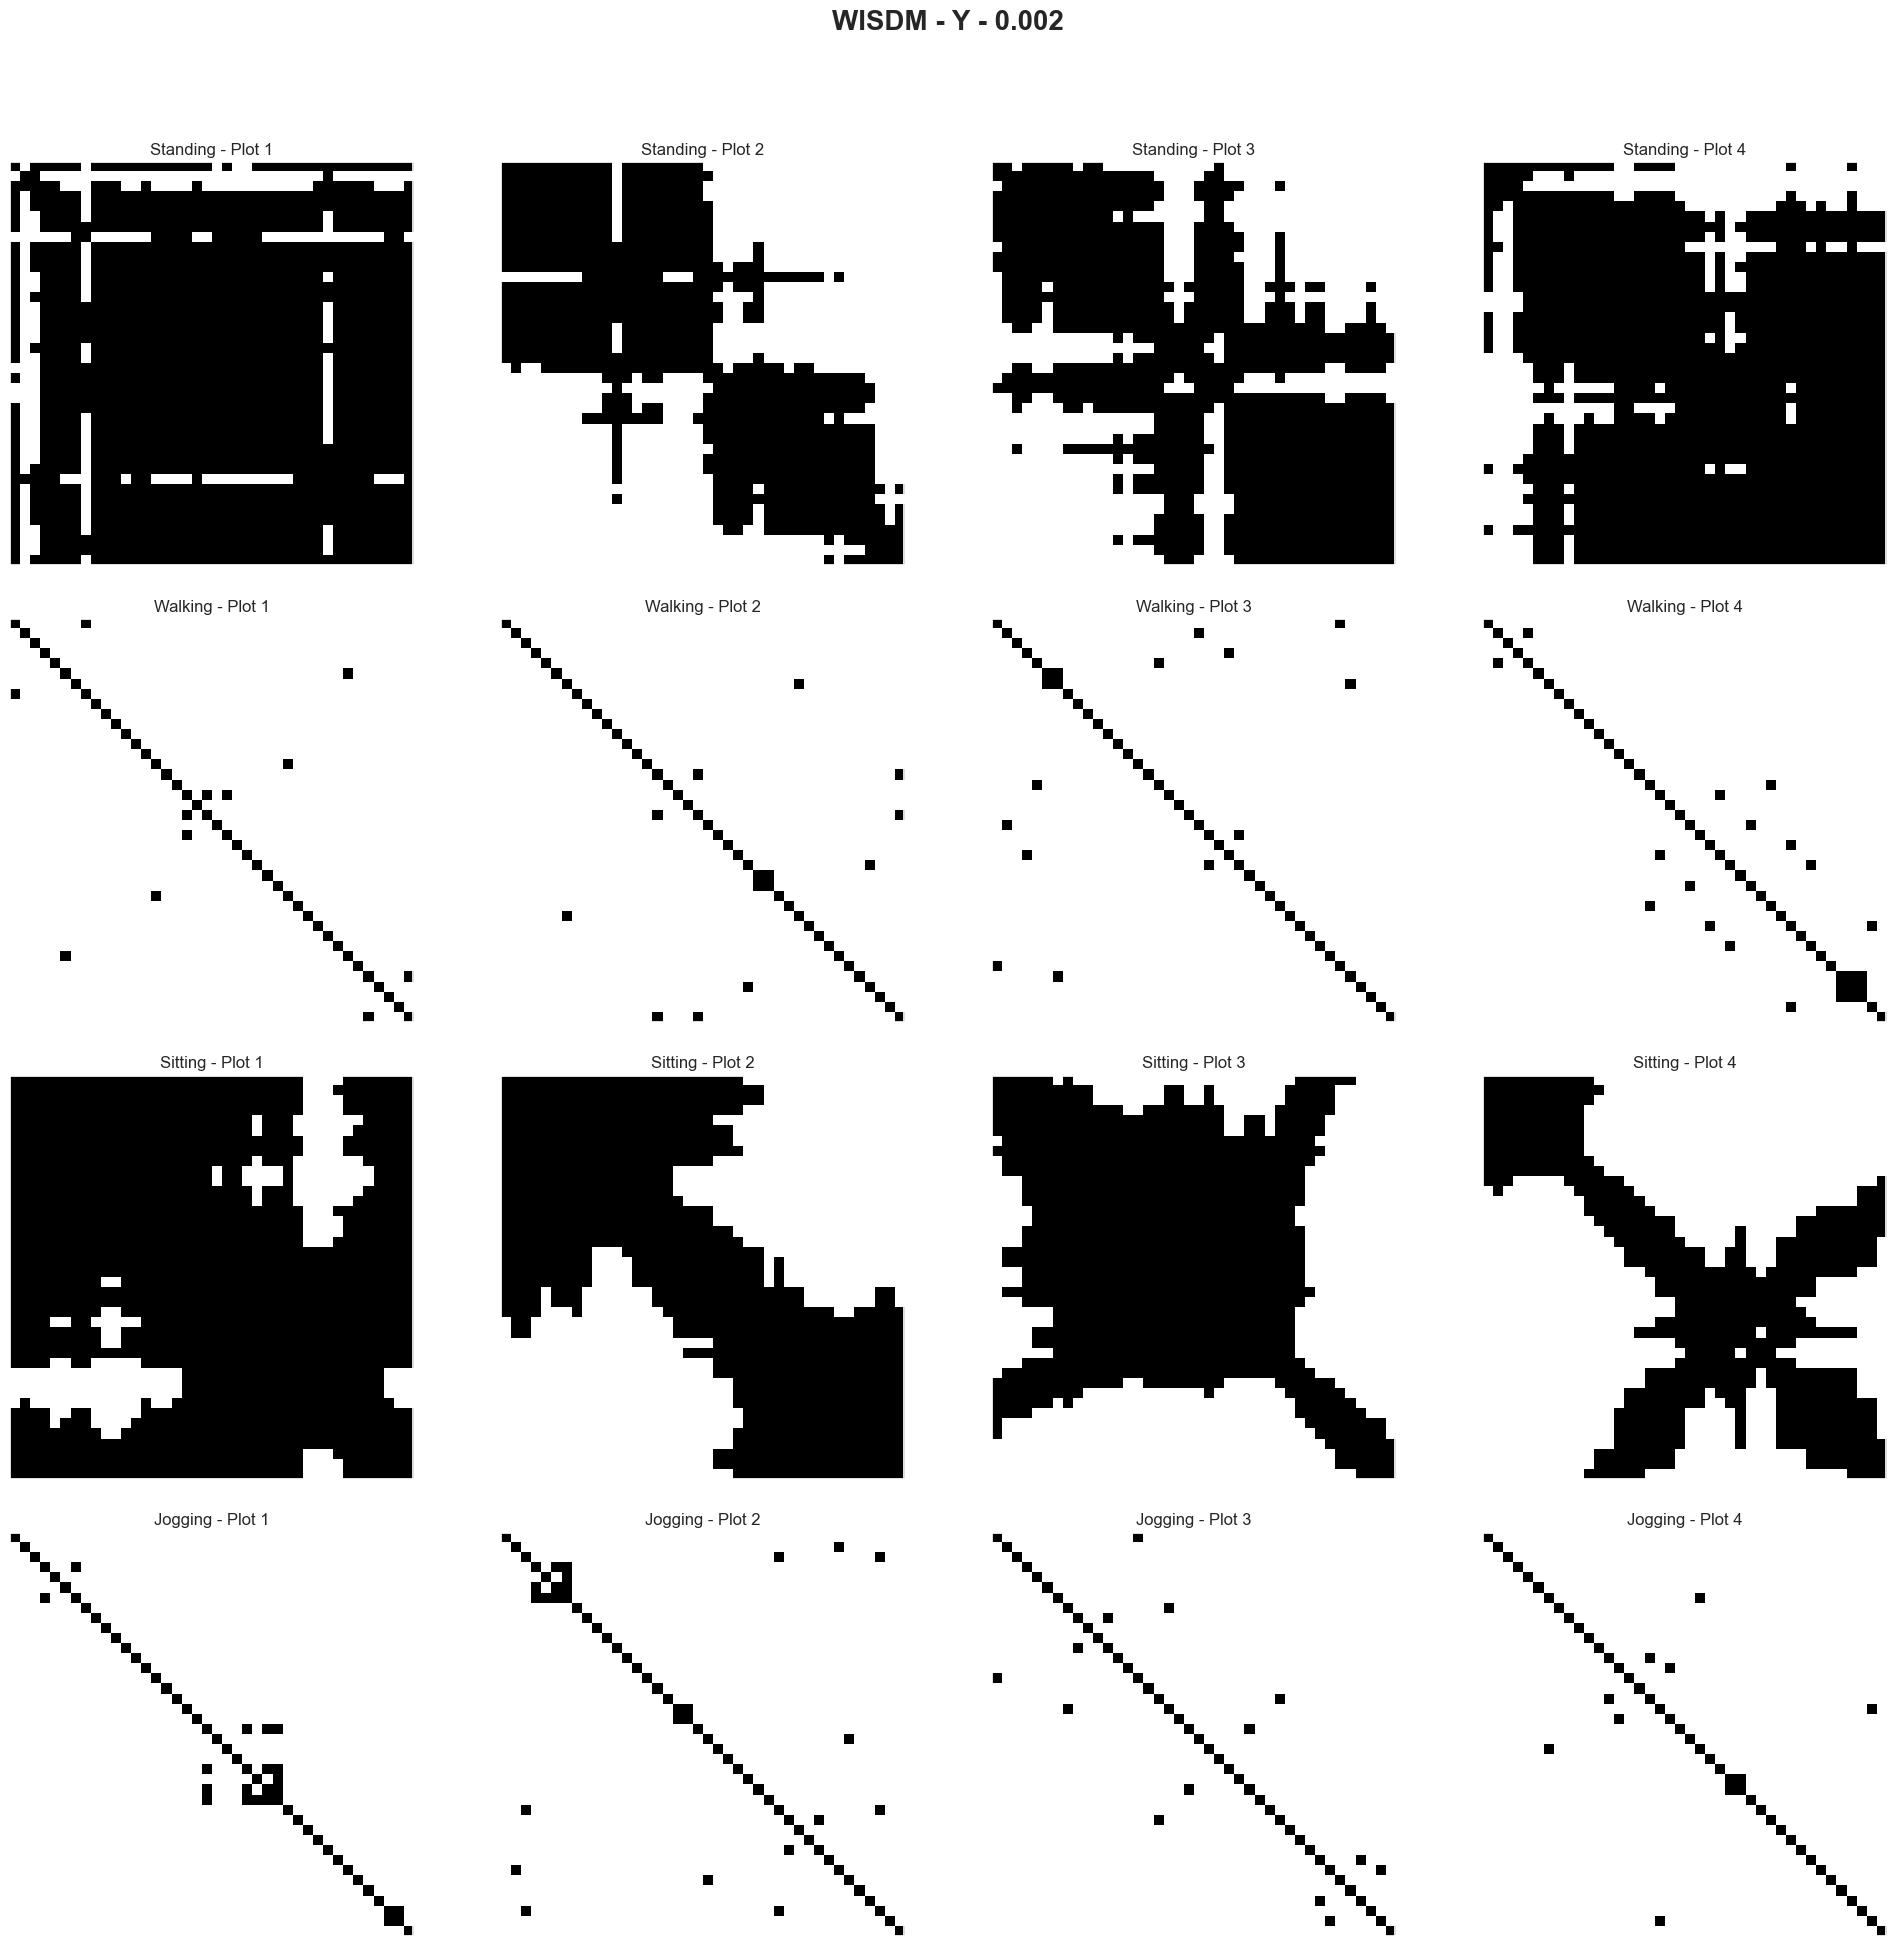

In [37]:
data = {"Standing": standing_data[y_axis].to_numpy(), "Walking": walking_data[y_axis].to_numpy(), "Sitting": sitting_data[y_axis].to_numpy(), "Jogging": jogging_data[y_axis].to_numpy()}

plot_recurrence_by_activity(data, "WISDM", "Y",threshold_vector, step=40, first=200)

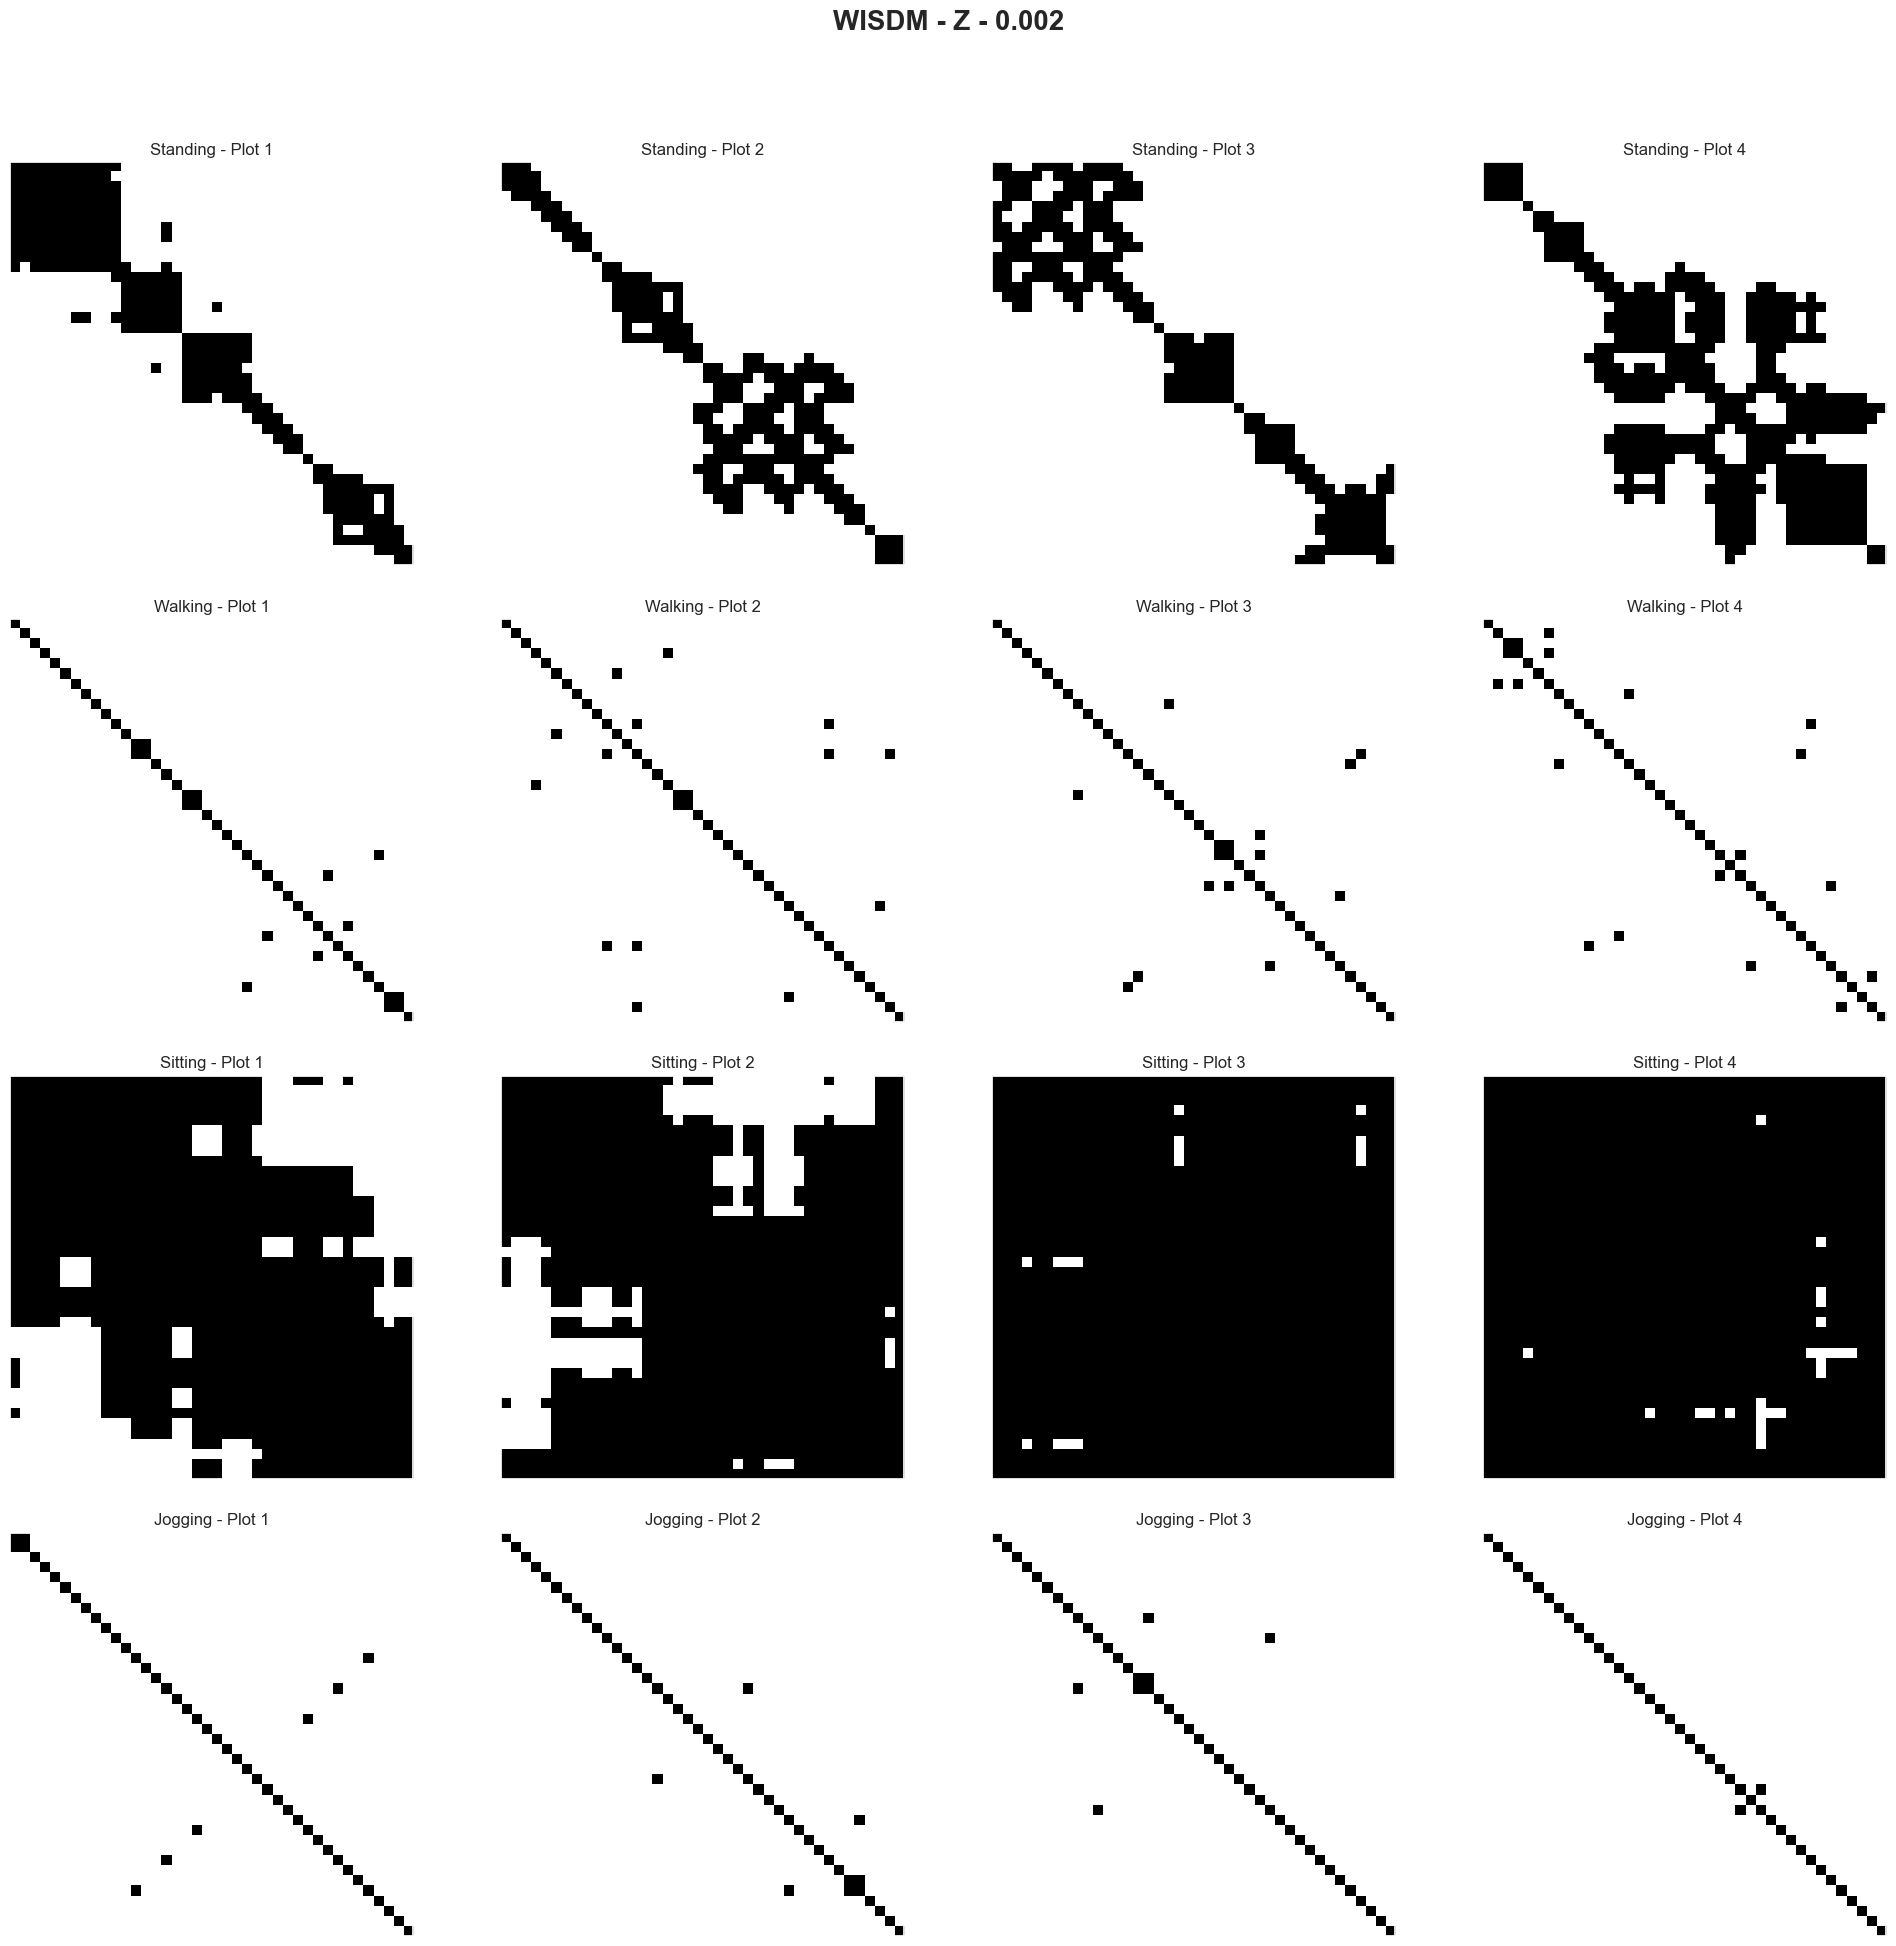

In [38]:
data = {"Standing": standing_data[z_axis].to_numpy(), "Walking": walking_data[z_axis].to_numpy(), "Sitting": sitting_data[z_axis].to_numpy(), "Jogging": jogging_data[z_axis].to_numpy()}

plot_recurrence_by_activity(data, "WISDM", "Z",threshold_vector, step=40, first=200)

### Recurrence Plots - Vector

In [39]:
sitting_vectors

array([[-0.90697381,  0.86719506,  0.01033263],
       [-0.91052081,  0.79439338,  0.06447263],
       [-0.79980376,  0.62553152,  0.14441866],
       ...,
       [ 0.44249057, -1.13000932,  1.64654032],
       [ 0.44679764, -1.12871238,  1.64538168],
       [ 0.4507669 , -1.12706958,  1.64422304]])

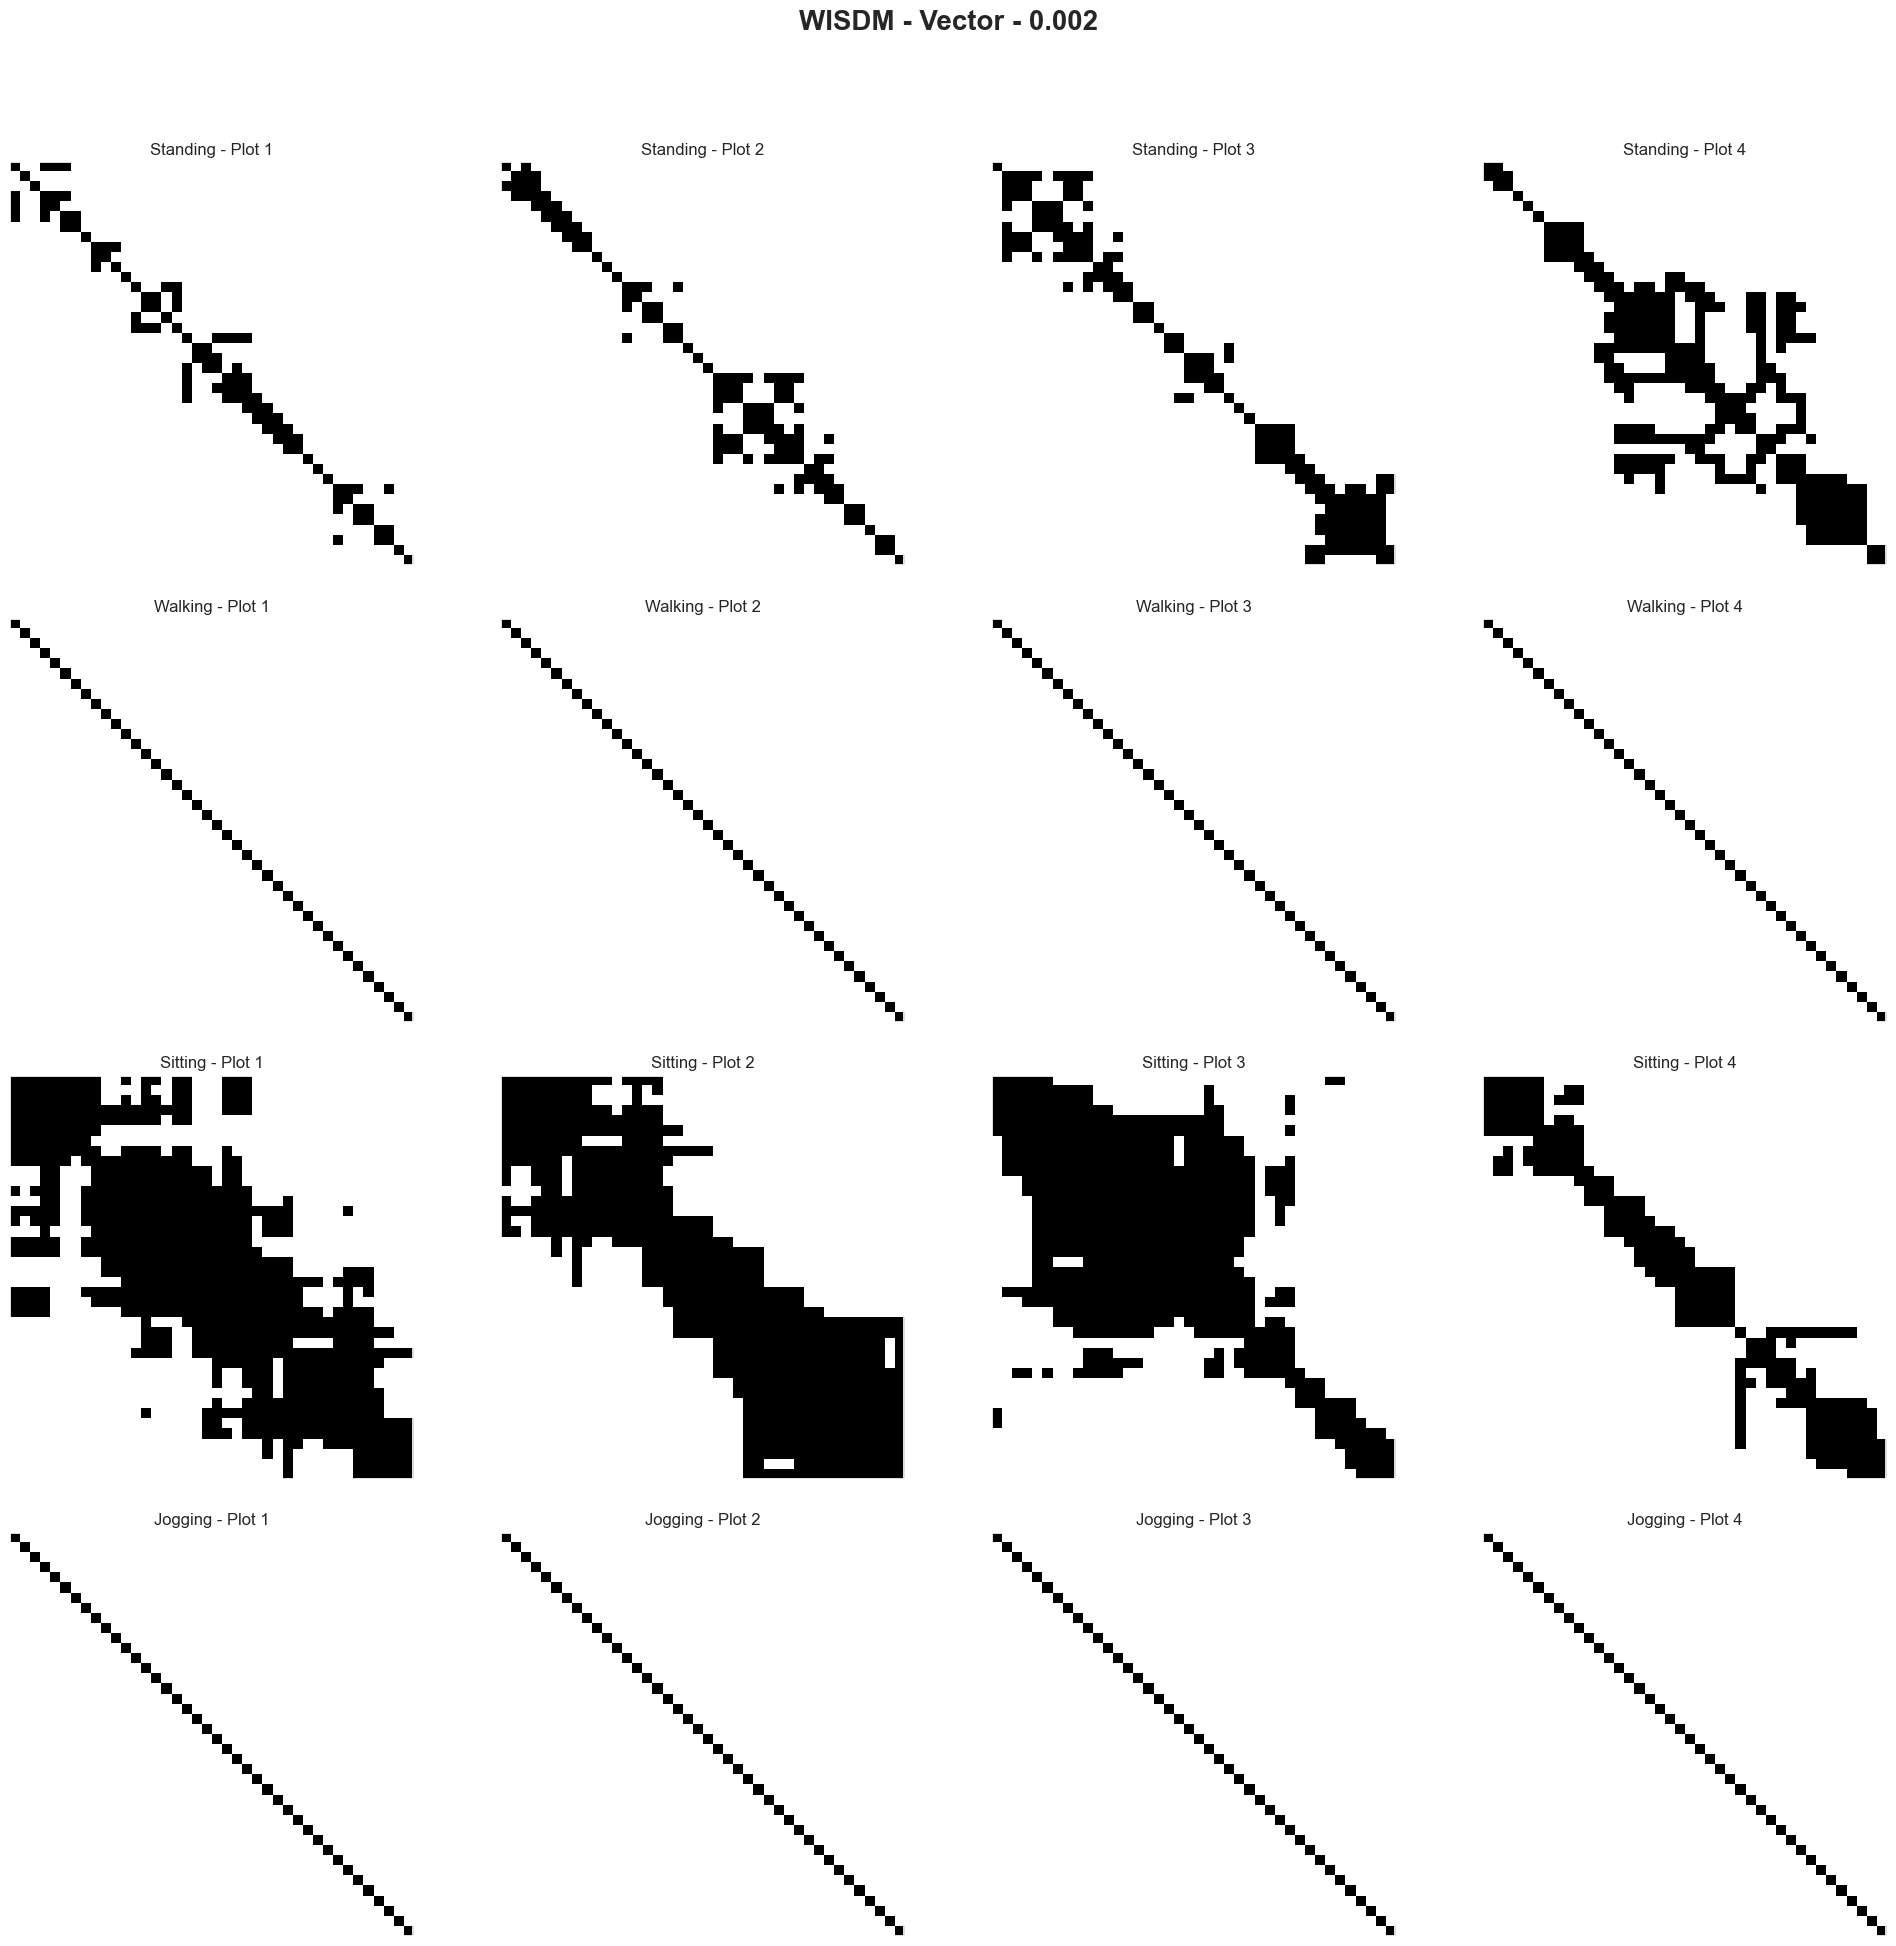

In [40]:
data = {"Standing": standing_vectors, "Walking": walking_vectors, "Sitting": sitting_vectors, "Jogging": jogging_vectors}

plot_recurrence_by_activity(data, "WISDM", "Vector", threshold_vector, step=40, first=200)

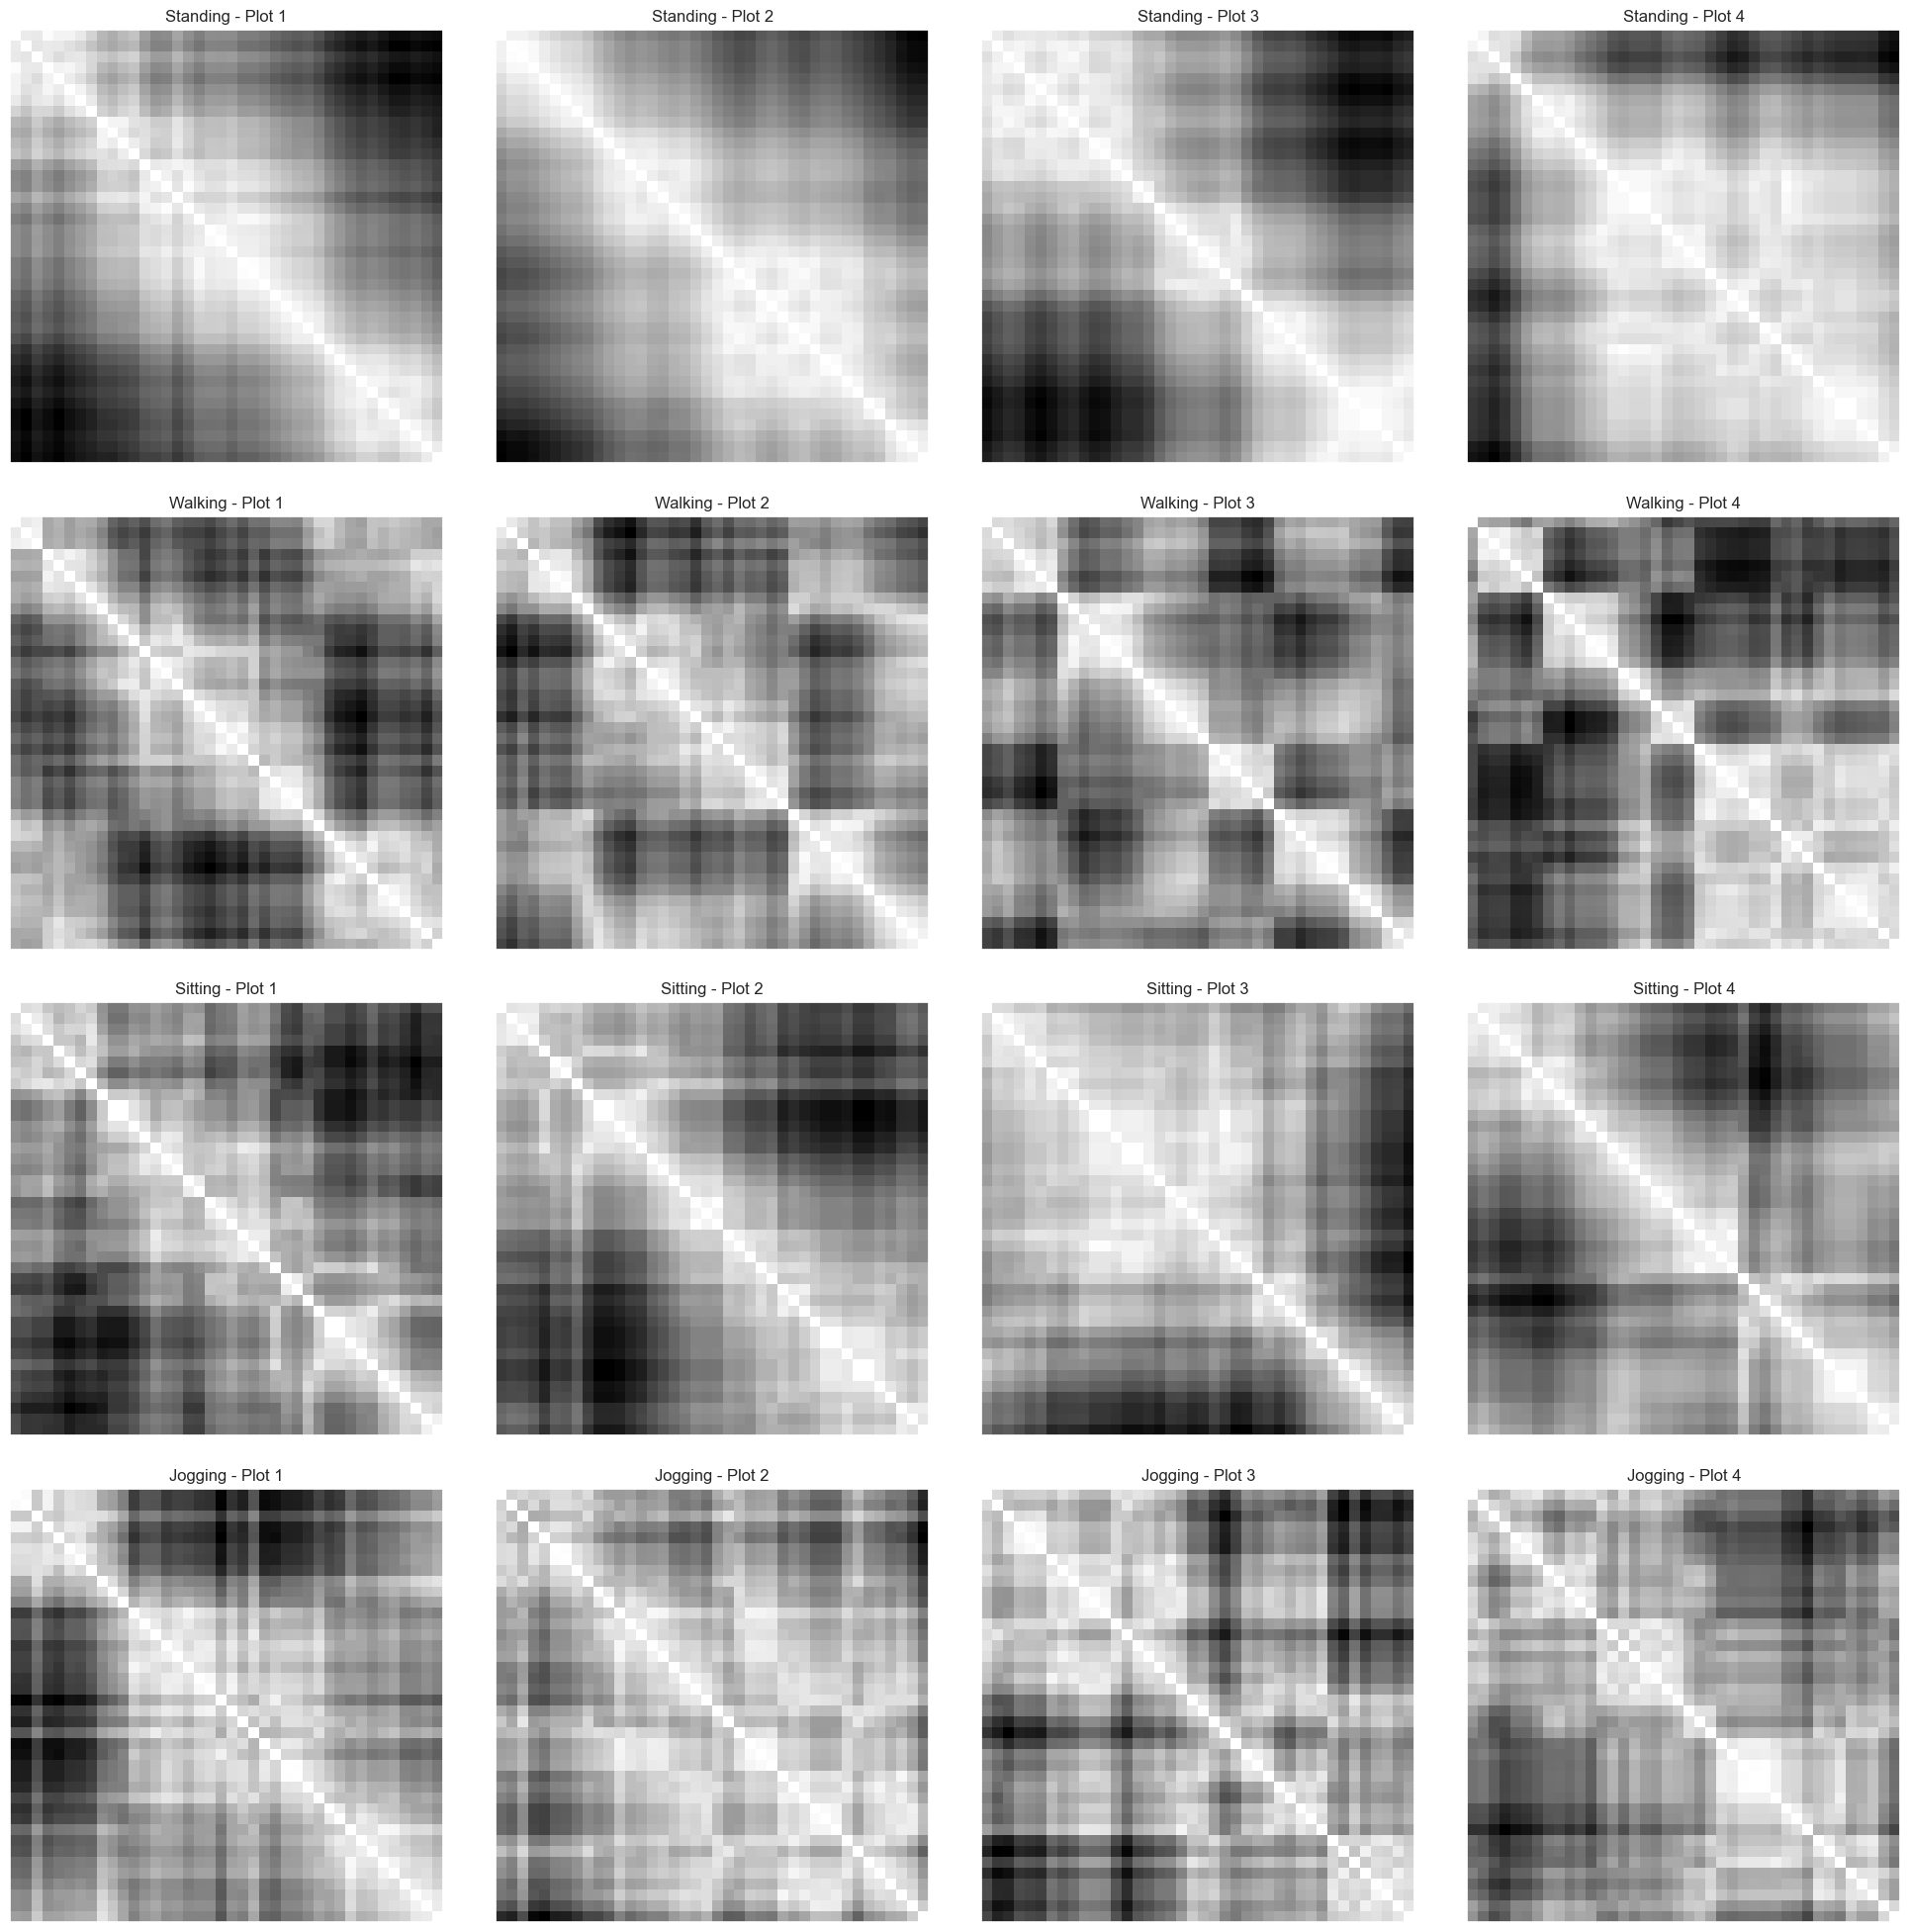

In [41]:
data = {"Standing": standing_vectors, "Walking": walking_vectors, "Sitting": sitting_vectors, "Jogging": jogging_vectors}

plot_recurrence_by_activity_grayscale(data, bins=256, step=40, first=200)

### Distance Analysis

In [56]:
walking_distances = calculate_distances_in_batches(walking_vectors)
jogging_distances = calculate_distances_in_batches(jogging_vectors)
sitting_distances = calculate_distances_in_batches(sitting_vectors)
standing_distances = calculate_distances_in_batches(standing_vectors)

distances = np.concatenate((walking_distances, jogging_distances, sitting_distances, standing_distances))
len(distances)

432033

In [57]:
distances = distances[~np.isnan(distances)]
len(distances)

432033

In [58]:
# Calculate Z-scores
z_scores = np.abs(stats.zscore(distances))

# Define threshold for identifying outliers (commonly 3)
threshold = 3

# Filter out the outliers
filtered_distances = distances[z_scores < threshold]

len(filtered_distances), max(filtered_distances), min(filtered_distances)

(427225, 4.8670951928527755, 0.0)

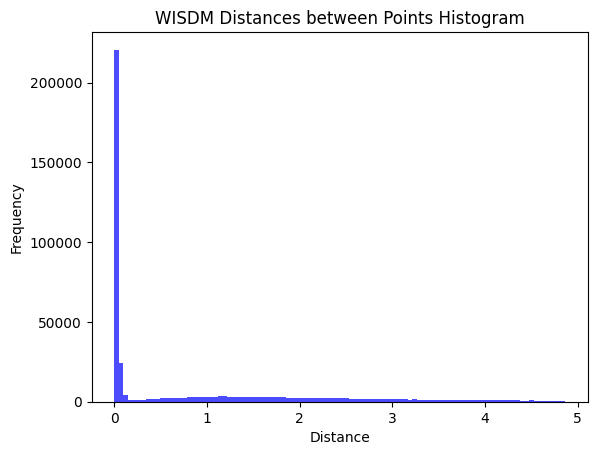

In [59]:
plt.hist(filtered_distances, bins=100, color='blue', alpha=0.7)

# Set y-axis to log scale

# Add title and labels
plt.title('WISDM Distances between Points Histogram')
plt.xlabel('Distance')
plt.ylabel('Frequency')

# Show the plot
plt.show()

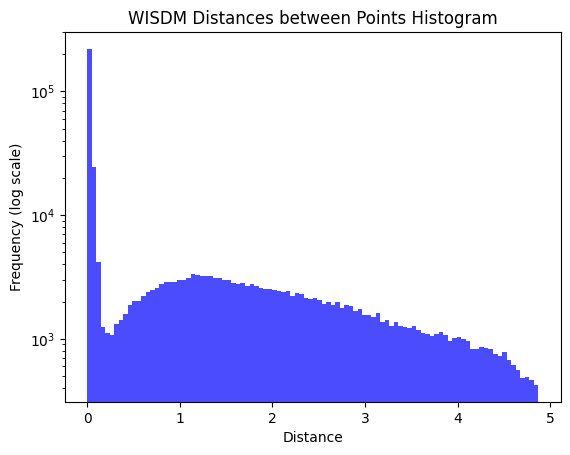

In [60]:
plt.hist(filtered_distances, bins=100, color='blue', alpha=0.7)

# Set y-axis to log scale
plt.yscale('log')

# Add title and labels
plt.title('WISDM Distances between Points Histogram')
plt.xlabel('Distance')
plt.ylabel('Frequency (log scale)')

# Show the plot
plt.show()

In [61]:
NUMBER_OF_THRESHOLDS = 50
MIN_THRESHOLD = 0.00001
MAX_THRESHOLD = 1
t = np.linspace(MIN_THRESHOLD, 1, NUMBER_OF_THRESHOLDS)

threshold_list_linear = t * MAX_THRESHOLD
threshold_list_linear = threshold_list_linear.round(4)
threshold_list_linear

threshold_list = (t ** 3) * MAX_THRESHOLD
threshold_list = threshold_list.round(4)
threshold_list

array([0.000e+00, 0.000e+00, 1.000e-04, 2.000e-04, 5.000e-04, 1.100e-03,
       1.800e-03, 2.900e-03, 4.400e-03, 6.200e-03, 8.500e-03, 1.130e-02,
       1.470e-02, 1.870e-02, 2.330e-02, 2.870e-02, 3.480e-02, 4.180e-02,
       4.960e-02, 5.830e-02, 6.800e-02, 7.870e-02, 9.050e-02, 1.034e-01,
       1.175e-01, 1.328e-01, 1.494e-01, 1.673e-01, 1.866e-01, 2.073e-01,
       2.295e-01, 2.532e-01, 2.785e-01, 3.055e-01, 3.341e-01, 3.644e-01,
       3.966e-01, 4.305e-01, 4.664e-01, 5.042e-01, 5.440e-01, 5.858e-01,
       6.297e-01, 6.758e-01, 7.241e-01, 7.746e-01, 8.273e-01, 8.825e-01,
       9.400e-01, 1.000e+00])

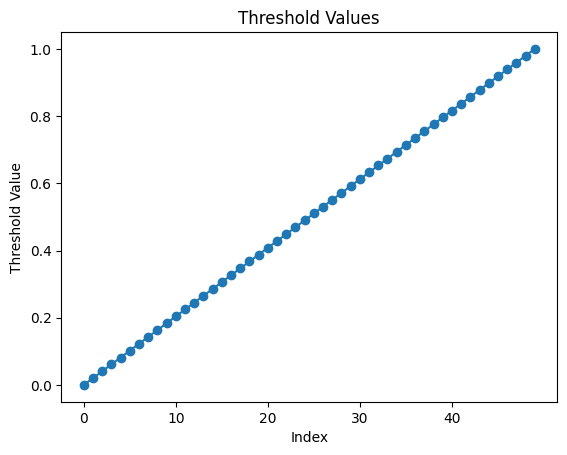

In [62]:
plt.plot(threshold_list_linear, marker='o')
plt.title("Threshold Values")
plt.ylabel("Threshold Value")
plt.xticks(np.arange(0, NUMBER_OF_THRESHOLDS, 10), [str(i) for i in np.arange(0, NUMBER_OF_THRESHOLDS, 10)])
plt.xlabel("Index")
plt.show()

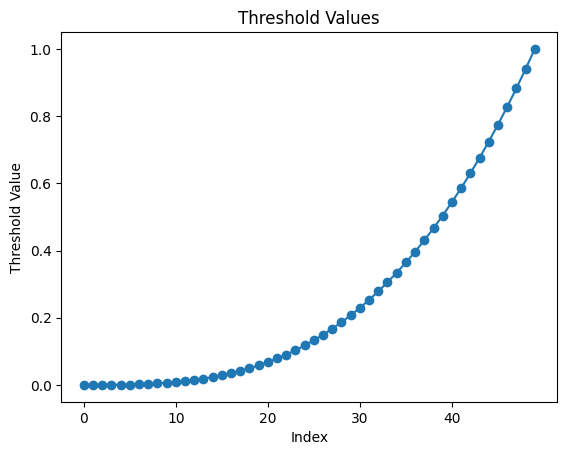

In [63]:
plt.plot(threshold_list, marker='o')
plt.title("Threshold Values")
plt.ylabel("Threshold Value")
plt.xticks(np.arange(0, NUMBER_OF_THRESHOLDS, 10), [str(i) for i in np.arange(0, NUMBER_OF_THRESHOLDS, 10)])
plt.xlabel("Index")
plt.show()

### Haralick

In [64]:
dict_list_haralick_walking = find_haralick_values(recurrence_plot_vector_grayscale, walking_vectors, window_size=128, step=128, start=100)
dict_list_haralick_standing = find_haralick_values(recurrence_plot_vector_grayscale, standing_vectors, window_size=128, step=128, start=100)
dict_list_haralick_sitting = find_haralick_values(recurrence_plot_vector_grayscale, sitting_vectors, window_size=128, step=128, start=100)
dict_list_haralick_jogging = find_haralick_values(recurrence_plot_vector_grayscale, jogging_vectors, window_size=128, step=128, start=100)
dict_list_haralick_upstairs = find_haralick_values(recurrence_plot_vector_grayscale, upstairs_vectors, window_size=128, step=128, start=100)
dict_list_haralick_downstairs = find_haralick_values(recurrence_plot_vector_grayscale, downstairs_vectors, window_size=128, step=128, start=100)

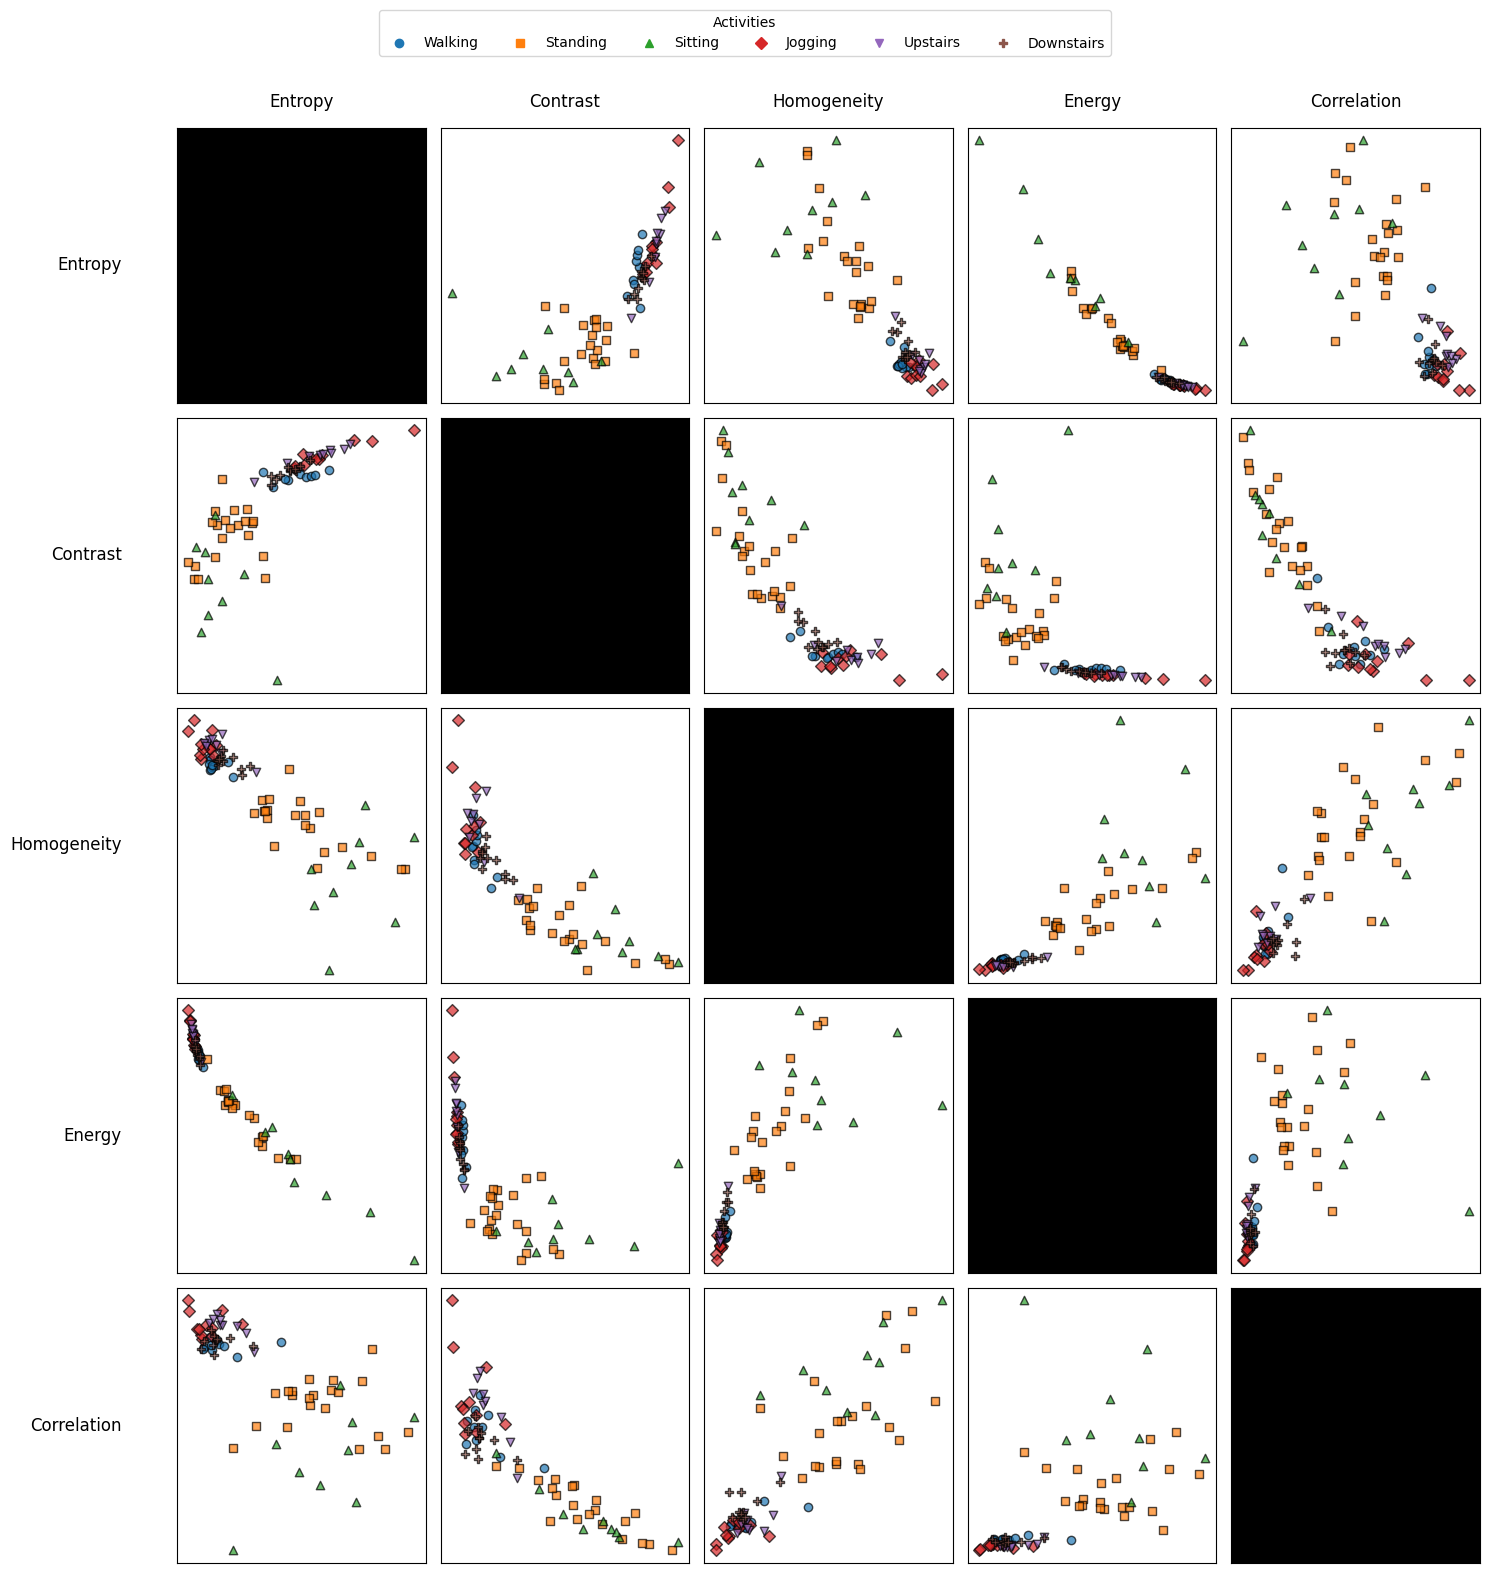

In [91]:
# Combine metrics and activity labels
metrics_dicts = [
    dict_list_haralick_walking,
    dict_list_haralick_standing,
    dict_list_haralick_sitting,
    dict_list_haralick_jogging,
    dict_list_haralick_upstairs,
    dict_list_haralick_downstairs
]
metric_names = [
    'entropy', 
    'contrast', 
    # 'dissimilarity', 
    'homogeneity', 
    'energy', 
    'correlation', 
    # 'ASM'
    ]
activity_labels = ["Walking", "Standing", "Sitting", "Jogging", "Upstairs", "Downstairs"]

# Plot the metric matrix
plot_metric_matrix(metrics_dicts, activity_labels, metric_names)

In [ ]:
dict_avg_haralick_walking = find_metrics_average(recurrence_plot_vector_grayscale, walking_vectors, window_size=96, step=96, start=100)
dict_avg_haralick_standing = find_metrics_average(recurrence_plot_vector_grayscale, standing_vectors, window_size=96, step=96, start=100)
dict_avg_haralick_sitting = find_metrics_average(recurrence_plot_vector_grayscale, sitting_vectors, window_size=96, step=96, start=100)
dict_avg_haralick_jogging = find_metrics_average(recurrence_plot_vector_grayscale, jogging_vectors, window_size=96, step=96, start=100)
dict_avg_haralick_upstairs = find_metrics_average(recurrence_plot_vector_grayscale, upstairs_vectors, window_size=96, step=96, start=100)
dict_avg_haralick_downstairs = find_metrics_average(recurrence_plot_vector_grayscale, downstairs_vectors, window_size=96, step=96, start=100)

In [77]:
def print_metrics(metrics, activity):
    """
    Print the average entropy and Haralick descriptors in a formatted way.
    
    Parameters:
    - metrics: dict, contains 'average_entropy' and 'average_haralick' descriptors.
    """
    print(f"{activity} Metrics Summary:")
    print(f"Average Entropy: {metrics['average_entropy']:.4f}")
    print("\nAverage Haralick Descriptors:")
    
    for key, value in metrics['average_haralick'].items():
        print(f"  {key.capitalize()}: {value:.4f}")


In [ ]:
print_metrics(dict_avg_haralick_walking, "Walking")
print('\n\n___')
print_metrics(dict_avg_haralick_standing, "Standing")
print('\n\n___')
print_metrics(dict_avg_haralick_sitting, "Sitting")
print('\n\n___')
print_metrics(dict_avg_haralick_jogging, "Jogging")
print('\n\n___')
print_metrics(dict_avg_haralick_upstairs, "Upstairs")
print('\n\n___')
print_metrics(dict_avg_haralick_downstairs, "Downstairs")
print('\n\n___')

Walking Metrics Summary:
Average Entropy: 7.2304

Average Haralick Descriptors:
  Contrast: 3252.6061
  Dissimilarity: 42.4840
  Homogeneity: 0.0324
  Energy: 0.0132
  Correlation: 0.1440
  Asm: 0.0002


___
Standing Metrics Summary:
Average Entropy: 6.6368

Average Haralick Descriptors:
  Contrast: 1816.3560
  Dissimilarity: 31.1771
  Homogeneity: 0.0643
  Energy: 0.0209
  Correlation: 0.3985
  Asm: 0.0005


___
Sitting Metrics Summary:
Average Entropy: 5.8314

Average Haralick Descriptors:
  Contrast: 1740.9702
  Dissimilarity: 29.8590
  Homogeneity: 0.0875
  Energy: 0.0379
  Correlation: 0.3966
  Asm: 0.0016


___
Jogging Metrics Summary:
Average Entropy: 7.5147

Average Haralick Descriptors:
  Contrast: 4244.6731
  Dissimilarity: 51.8402
  Homogeneity: 0.0271
  Energy: 0.0120
  Correlation: 0.0901
  Asm: 0.0002


___
Upstairs Metrics Summary:
Average Entropy: 7.5151

Average Haralick Descriptors:
  Contrast: 4060.9800
  Dissimilarity: 49.0298
  Homogeneity: 0.0320
  Energy: 0.0121


In [ ]:
# List of metrics and corresponding activity labels
metrics_dicts = [
    dict_avg_haralick_walking,
    dict_avg_haralick_standing,
    dict_avg_haralick_sitting,
    dict_avg_haralick_jogging,
    dict_avg_haralick_upstairs,
    dict_avg_haralick_downstairs
]
activity_labels = ['Walking', 'Standing', 'Sitting', 'Jogging', 'Upstairs', 'Downstairs']

# Generate comparison plots
plot_metric_comparisons(metrics_dicts, activity_labels)


### Entropy and Threshold Calculation

In [ ]:
# best_walking, dict_entropies_walking = find_best_threshold(recurrence_plot_vector, threshold_list, walking_vectors, window_size=40, step=40, start=100)
# print(f"Walking: {best_walking} | Entropy: {dict_entropies_walking[best_walking]}")
# best_standing, dict_entropies_standing = find_best_threshold(recurrence_plot_vector, threshold_list, standing_vectors, window_size=40, step=40, start=100)
# print(f"Standing: {best_standing} | Entropy: {dict_entropies_standing[best_standing]}")
# best_sitting, dict_entropies_sitting = find_best_threshold(recurrence_plot_vector, threshold_list, sitting_vectors, window_size=40, step=40, start=100)
# print(f"Sitting: {best_sitting} | Entropy: {dict_entropies_sitting[best_sitting]}")
# best_jogging, dict_entropies_jogging = find_best_threshold(recurrence_plot_vector, threshold_list, jogging_vectors, window_size=40, step=40, start=100)
# print(f"Jogging: {best_jogging} | Entropy: {dict_entropies_jogging[best_jogging]}")
# best_upstairs, dict_entropies_upstairs = find_best_threshold(recurrence_plot_vector, threshold_list, upstairs_vectors, window_size=40, step=40, start=100)
# print(f"Upstairs: {best_upstairs} | Entropy: {dict_entropies_upstairs[best_upstairs]}")
# best_downstairs, dict_entropies_downstairs = find_best_threshold(recurrence_plot_vector, threshold_list, downstairs_vectors, window_size=40, step=40, start=100)
# print(f"Downstairs: {best_downstairs} | Entropy: {dict_entropies_downstairs[best_downstairs]}")

Walking: 1.0 | Entropy: 0.8893916003267329
Standing: 0.0187 | Entropy: 0.8612708554239523
Sitting: 0.0113 | Entropy: 0.8570196238457108
Jogging: 1.0 | Entropy: 0.5411077207977304
Upstairs: 1.0 | Entropy: 0.663825491588653
Downstairs: 1.0 | Entropy: 0.7214528883337966


In [51]:
# determinants_walking = find_determinants(recurrence_matrix_vector, walking_vectors, window_size=40, step=40, start=100)
# print(f"Mean Determinant Walking: {np.mean(determinants_walking)}")
# determinants_standing = find_determinants(recurrence_matrix_vector, standing_vectors, window_size=40, step=40, start=100)
# print(f"Mean Determinant Standing: {np.mean(determinants_standing)}")
# determinants_sitting = find_determinants(recurrence_matrix_vector, sitting_vectors, window_size=40, step=40, start=100)
# print(f"Mean Determinant Sitting: {np.mean(determinants_sitting)}")
# determinants_jogging = find_determinants(recurrence_matrix_vector, jogging_vectors, window_size=40, step=40, start=100)
# print(f"Mean Determinant Jogging: {np.mean(determinants_jogging)}")
# determinants_upstairs = find_determinants(recurrence_matrix_vector, upstairs_vectors, window_size=40, step=40, start=100)
# print(f"Mean Determinant Upstairs: {np.mean(determinants_upstairs)}")
# determinants_downstairs = find_determinants(recurrence_matrix_vector, downstairs_vectors, window_size=40, step=40, start=100)
# print(f"Mean Determinant Downstairs: {np.mean(determinants_downstairs)}")

In [ ]:
# results = {}
# for i_threshold in threshold_list:    
#     # Initialize a sub-dictionary for each threshold
#     results[i_threshold] = {
#         'Mean Laminarity Walking': None,
#         'Mean Laminarity Standing': None,
#         'Mean Laminarity Sitting': None,
#         'Mean Laminarity Jogging': None,
#         'Mean Laminarity Upstairs': None,
#         'Mean Laminarity Downstairs': None
#     }
    
#     laminarities_walking = find_laminarities(recurrence_plot_vector, i_threshold, walking_vectors, window_size=40, step=40, start=100, min_line_length=3)
#     mean_laminarity_walking = np.mean(laminarities_walking)
#     results[i_threshold]['Mean Laminarity Walking'] = mean_laminarity_walking

#     laminarities_standing = find_laminarities(recurrence_plot_vector, i_threshold, standing_vectors, window_size=40, step=40, start=100, min_line_length=3)
#     mean_laminarity_standing = np.mean(laminarities_standing)
#     results[i_threshold]['Mean Laminarity Standing'] = mean_laminarity_standing

#     laminarities_sitting = find_laminarities(recurrence_plot_vector, i_threshold, sitting_vectors, window_size=40, step=40, start=100, min_line_length=3)
#     mean_laminarity_sitting = np.mean(laminarities_sitting)
#     results[i_threshold]['Mean Laminarity Sitting'] = mean_laminarity_sitting

#     laminarities_jogging = find_laminarities(recurrence_plot_vector, i_threshold, jogging_vectors, window_size=40, step=40, start=100, min_line_length=3)
#     mean_laminarity_jogging = np.mean(laminarities_jogging)
#     results[i_threshold]['Mean Laminarity Jogging'] = mean_laminarity_jogging

#     laminarities_upstairs = find_laminarities(recurrence_plot_vector, i_threshold, upstairs_vectors, window_size=40, step=40, start=100, min_line_length=3)
#     mean_laminarity_upstairs = np.mean(laminarities_upstairs)
#     results[i_threshold]['Mean Laminarity Upstairs'] = mean_laminarity_upstairs

#     laminarities_downstairs = find_laminarities(recurrence_plot_vector, i_threshold, downstairs_vectors, window_size=40, step=40, start=100, min_line_length=3)
#     mean_laminarity_downstairs = np.mean(laminarities_downstairs)
#     results[i_threshold]['Mean Laminarity Downstairs'] = mean_laminarity_downstairs

### Laminaridade

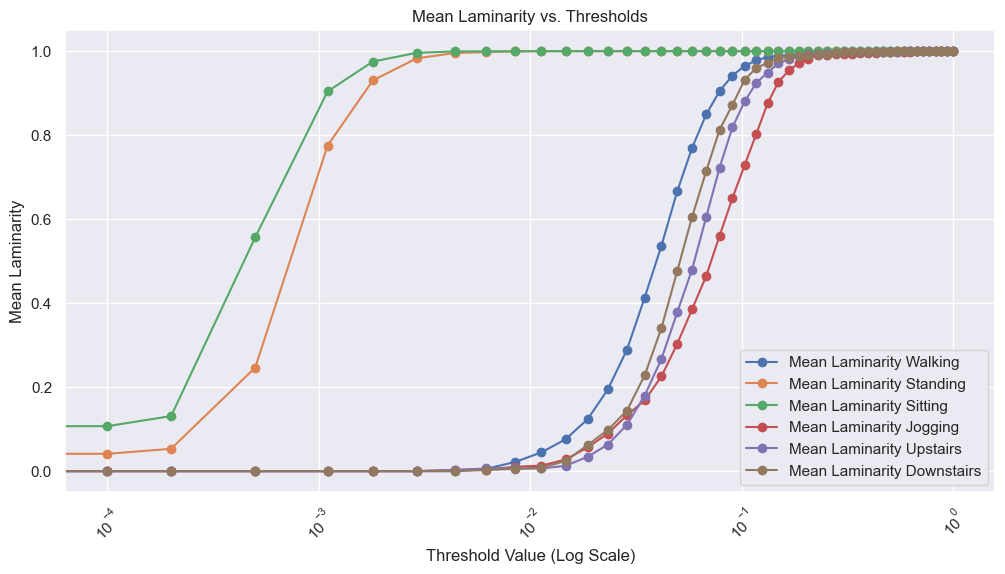

In [ ]:
# plot_laminarities(results)

### Plots Generation

In [50]:
# data_x = {"Standing": standing_data[x_axis].to_numpy(), "Walking": walking_data[x_axis].to_numpy(), "Sitting": sitting_data[x_axis].to_numpy(), "Jogging": jogging_data[x_axis].to_numpy()}
# data_y = {"Standing": standing_data[y_axis].to_numpy(), "Walking": walking_data[y_axis].to_numpy(), "Sitting": sitting_data[y_axis].to_numpy(), "Jogging": jogging_data[y_axis].to_numpy()}
# data_z = {"Standing": standing_data[z_axis].to_numpy(), "Walking": walking_data[z_axis].to_numpy(), "Sitting": sitting_data[z_axis].to_numpy(), "Jogging": jogging_data[z_axis].to_numpy()}
# data_vectors = {"Standing": standing_vectors, "Walking": walking_vectors, "Sitting": sitting_vectors, "Jogging": jogging_vectors}

# # RELATIVE_PATH = "../../results/recurrence_plots/WISDM/"
# RELATIVE_PATH = "C:/Users/tulio/Downloads/Plots/WISDM/"
# dataset_name = "WISDM"

# for i in range(len(threshold_list)):
#     plot_recurrence_by_activity(data_x, dataset_name, "X", threshold_list[i], step=40, first=200, filename=f"{RELATIVE_PATH}X/recurrence_wisdm_x_{i}-{str(threshold_list[i])}")
#     plot_recurrence_by_activity(data_y, dataset_name, "Y", threshold_list[i], step=40, first=200, filename=f"{RELATIVE_PATH}Y/recurrence_wisdm_y_{i}-{str(threshold_list[i])}")
#     plot_recurrence_by_activity(data_z, dataset_name, "Z", threshold_list[i], step=40, first=200, filename=f"{RELATIVE_PATH}Z/recurrence_wisdm_z_{i}-{str(threshold_list[i])}")
#     plot_recurrence_by_activity(data_vectors, dataset_name, "Vector", threshold_list[i], step=40, first=200, filename=f"{RELATIVE_PATH}Vector/recurrence_wisdm_vector_{i}-{str(threshold_list[i])}")
    

## PAMAP2 Dataset

### Dataset Preparation

In [160]:
# Function to normalize columns
def normalize_group(group):
    group[['hand_acc_16g_x', 'hand_acc_16g_y', 'hand_acc_16g_z']] = (group[['hand_acc_16g_x', 'hand_acc_16g_y', 'hand_acc_16g_z']] - group[['hand_acc_16g_x', 'hand_acc_16g_y', 'hand_acc_16g_z']].mean()) / group[['hand_acc_16g_x', 'hand_acc_16g_y', 'hand_acc_16g_z']].std()
    return group

pamap2 = pd.read_csv('../../datasets/pamap_balanced.csv')
pamap2 = pamap2.groupby('subject_id').apply(normalize_group)
pamap2 = pamap2.rename(columns={
    'hand_acc_16g_x': 'accX',
    'hand_acc_16g_y': 'accY',
    'hand_acc_16g_z': 'accZ'
})
pamap2 = pamap2.reset_index(drop=True)
pamap2

C:\Users\tulio\AppData\Local\Temp\ipykernel_21356\3292868794.py:7: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  pamap2 = pamap2.groupby('subject_id').apply(normalize_group)


,timestamp,activity_id,accX,accY,accZ,hand_acc_6g_x,hand_acc_6g_y,hand_acc_6g_z,hand_gyro_x,hand_gyro_y,hand_gyro_z,hand_mag_x,hand_mag_y,hand_mag_z,subject_id
0,309.53,2,1.173981,0.391292,0.007209,2.424750,9.12390,3.02166,0.037944,0.024816,-0.016013,15.0033,-67.00450,-1.055520,1
1,309.54,2,1.205812,0.395961,-0.151766,2.394240,9.13917,2.96125,0.040065,0.011347,0.009483,14.5708,-66.98840,-0.356026,1
2,309.55,2,1.189279,0.390786,-0.120353,2.378790,9.21468,2.84029,0.017566,-0.017100,-0.006770,14.6740,-67.31640,-0.707928,1
3,309.56,2,1.183728,0.374697,-0.104401,2.377660,9.13912,2.78006,-0.047912,0.007181,0.005693,14.7736,-67.42350,-1.288870,1
4,309.57,2,1.213794,0.391098,0.040929,2.361820,9.04862,2.78027,-0.046287,-0.000137,0.012163,15.1053,-66.56780,-1.630630,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
926023,3630.07,5,1.268499,0.884639,2.541252,0.374732,2.89221,9.30422,-0.017195,0.006944,0.007758,17.7034,-4.55562,-41.179600,8
926024,3630.08,5,1.250323,0.870380,2.488375,0.526067,2.89119,9.37958,-0.032333,-0.044224,0.011758,17.9510,-4.56875,-41.048800,8
926025,3630.09,5,1.291976,0.870418,2.581465,0.630675,2.81489,9.34943,-0.004483,-0.001148,0.039415,17.9572,-4.94146,-41.177700,8
926026,3630.10,5,1.280116,0.875141,2.554826,0.720712,2.70858,9.40998,-0.022839,0.045628,0.049042,17.7079,-4.80414,-41.309300,8


In [161]:
pamap2[['x_maf', 'y_maf', 'z_maf']] = pamap2.groupby('subject_id')[['accX', 'accY', 'accZ']].rolling(window=100).mean().reset_index(drop=True)
pamap2[['x_ema', 'y_ema', 'z_ema']] = pamap2.groupby('subject_id')[['accX', 'accY', 'accZ']].ewm(span=150, adjust=False).mean().reset_index(drop=True)

In [162]:
walking_data = pamap2[(pamap2['activity_id'] == 4) & (pamap2['subject_id'] == 5)]
walking_vectors = walking_data[[x_axis, y_axis, z_axis]].to_numpy()

standing_data = pamap2[(pamap2['activity_id'] == 3) & (pamap2['subject_id'] == 5)]
standing_vectors = standing_data[[x_axis, y_axis, z_axis]].to_numpy()

sitting_data = pamap2[(pamap2['activity_id'] == 2) & (pamap2['subject_id'] == 5)]
sitting_vectors = sitting_data[[x_axis, y_axis, z_axis]].to_numpy()

jogging_data = pamap2[(pamap2['activity_id'] == 5) & (pamap2['subject_id'] == 5)]
jogging_vectors = jogging_data[[x_axis, y_axis, z_axis]].to_numpy()

end = start + 200
threshold_axis = 0.001
threshold_vector = 0.06

print(len(walking_vectors)), print(len(standing_vectors)), print(len(sitting_vectors)), print(len(jogging_vectors))

30909
22125
26826
24586


(None, None, None, None)

### Time-series plot

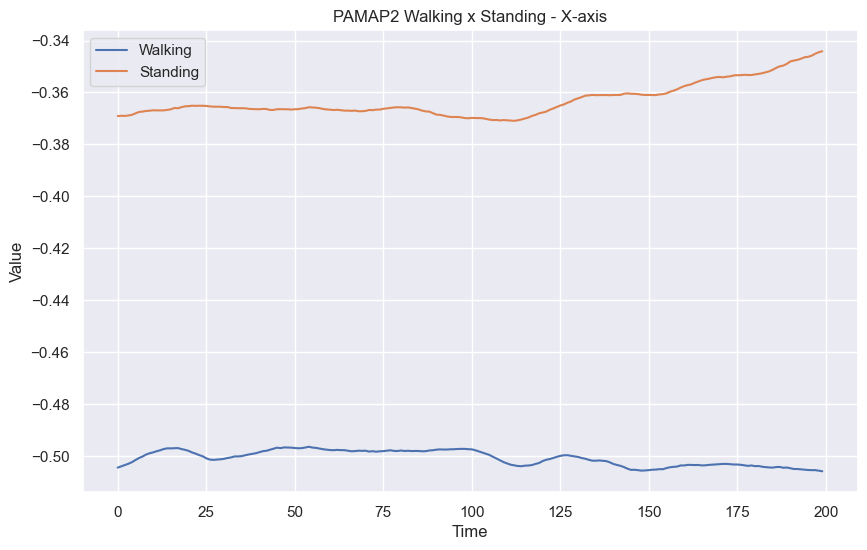

In [78]:
plot_two_time_series(walking_data[x_axis].iloc[start:end].reset_index(drop=True), "Walking", standing_data[x_axis].iloc[start:end].reset_index(drop=True), "Standing", 'PAMAP2 Walking x Standing - X-axis')

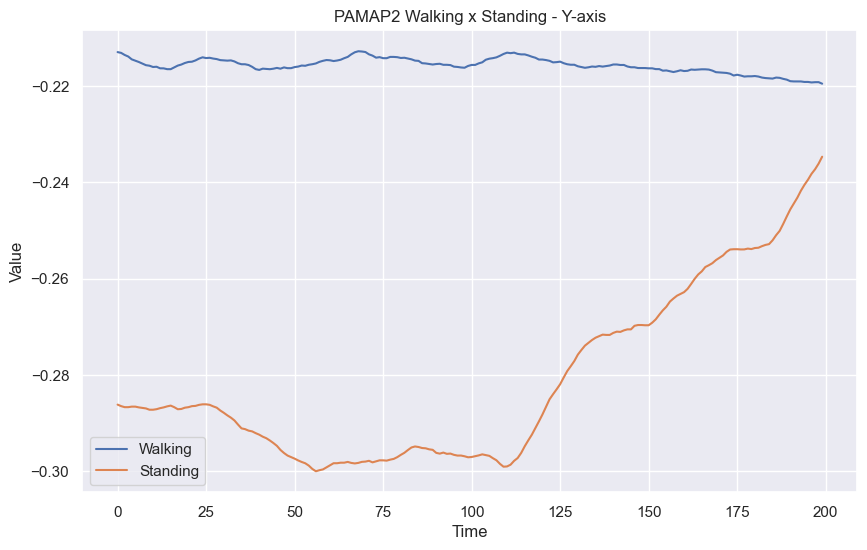

In [79]:
plot_two_time_series(walking_data[y_axis].iloc[start:end].reset_index(drop=True), "Walking", standing_data[y_axis].iloc[start:end].reset_index(drop=True), "Standing", 'PAMAP2 Walking x Standing - Y-axis')

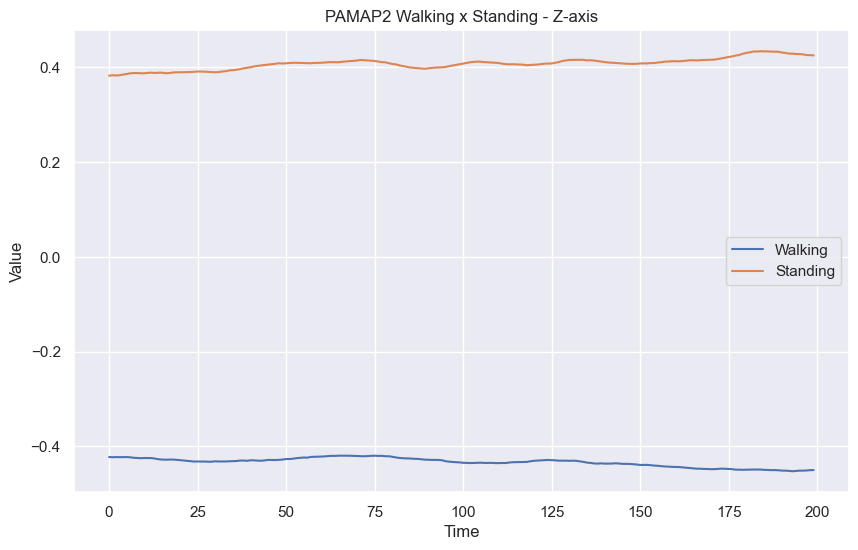

In [80]:
plot_two_time_series(walking_data[z_axis].iloc[start:end].reset_index(drop=True), "Walking", standing_data[z_axis].iloc[start:end].reset_index(drop=True), "Standing", 'PAMAP2 Walking x Standing - Z-axis')

### Recurrence Plots - Axis

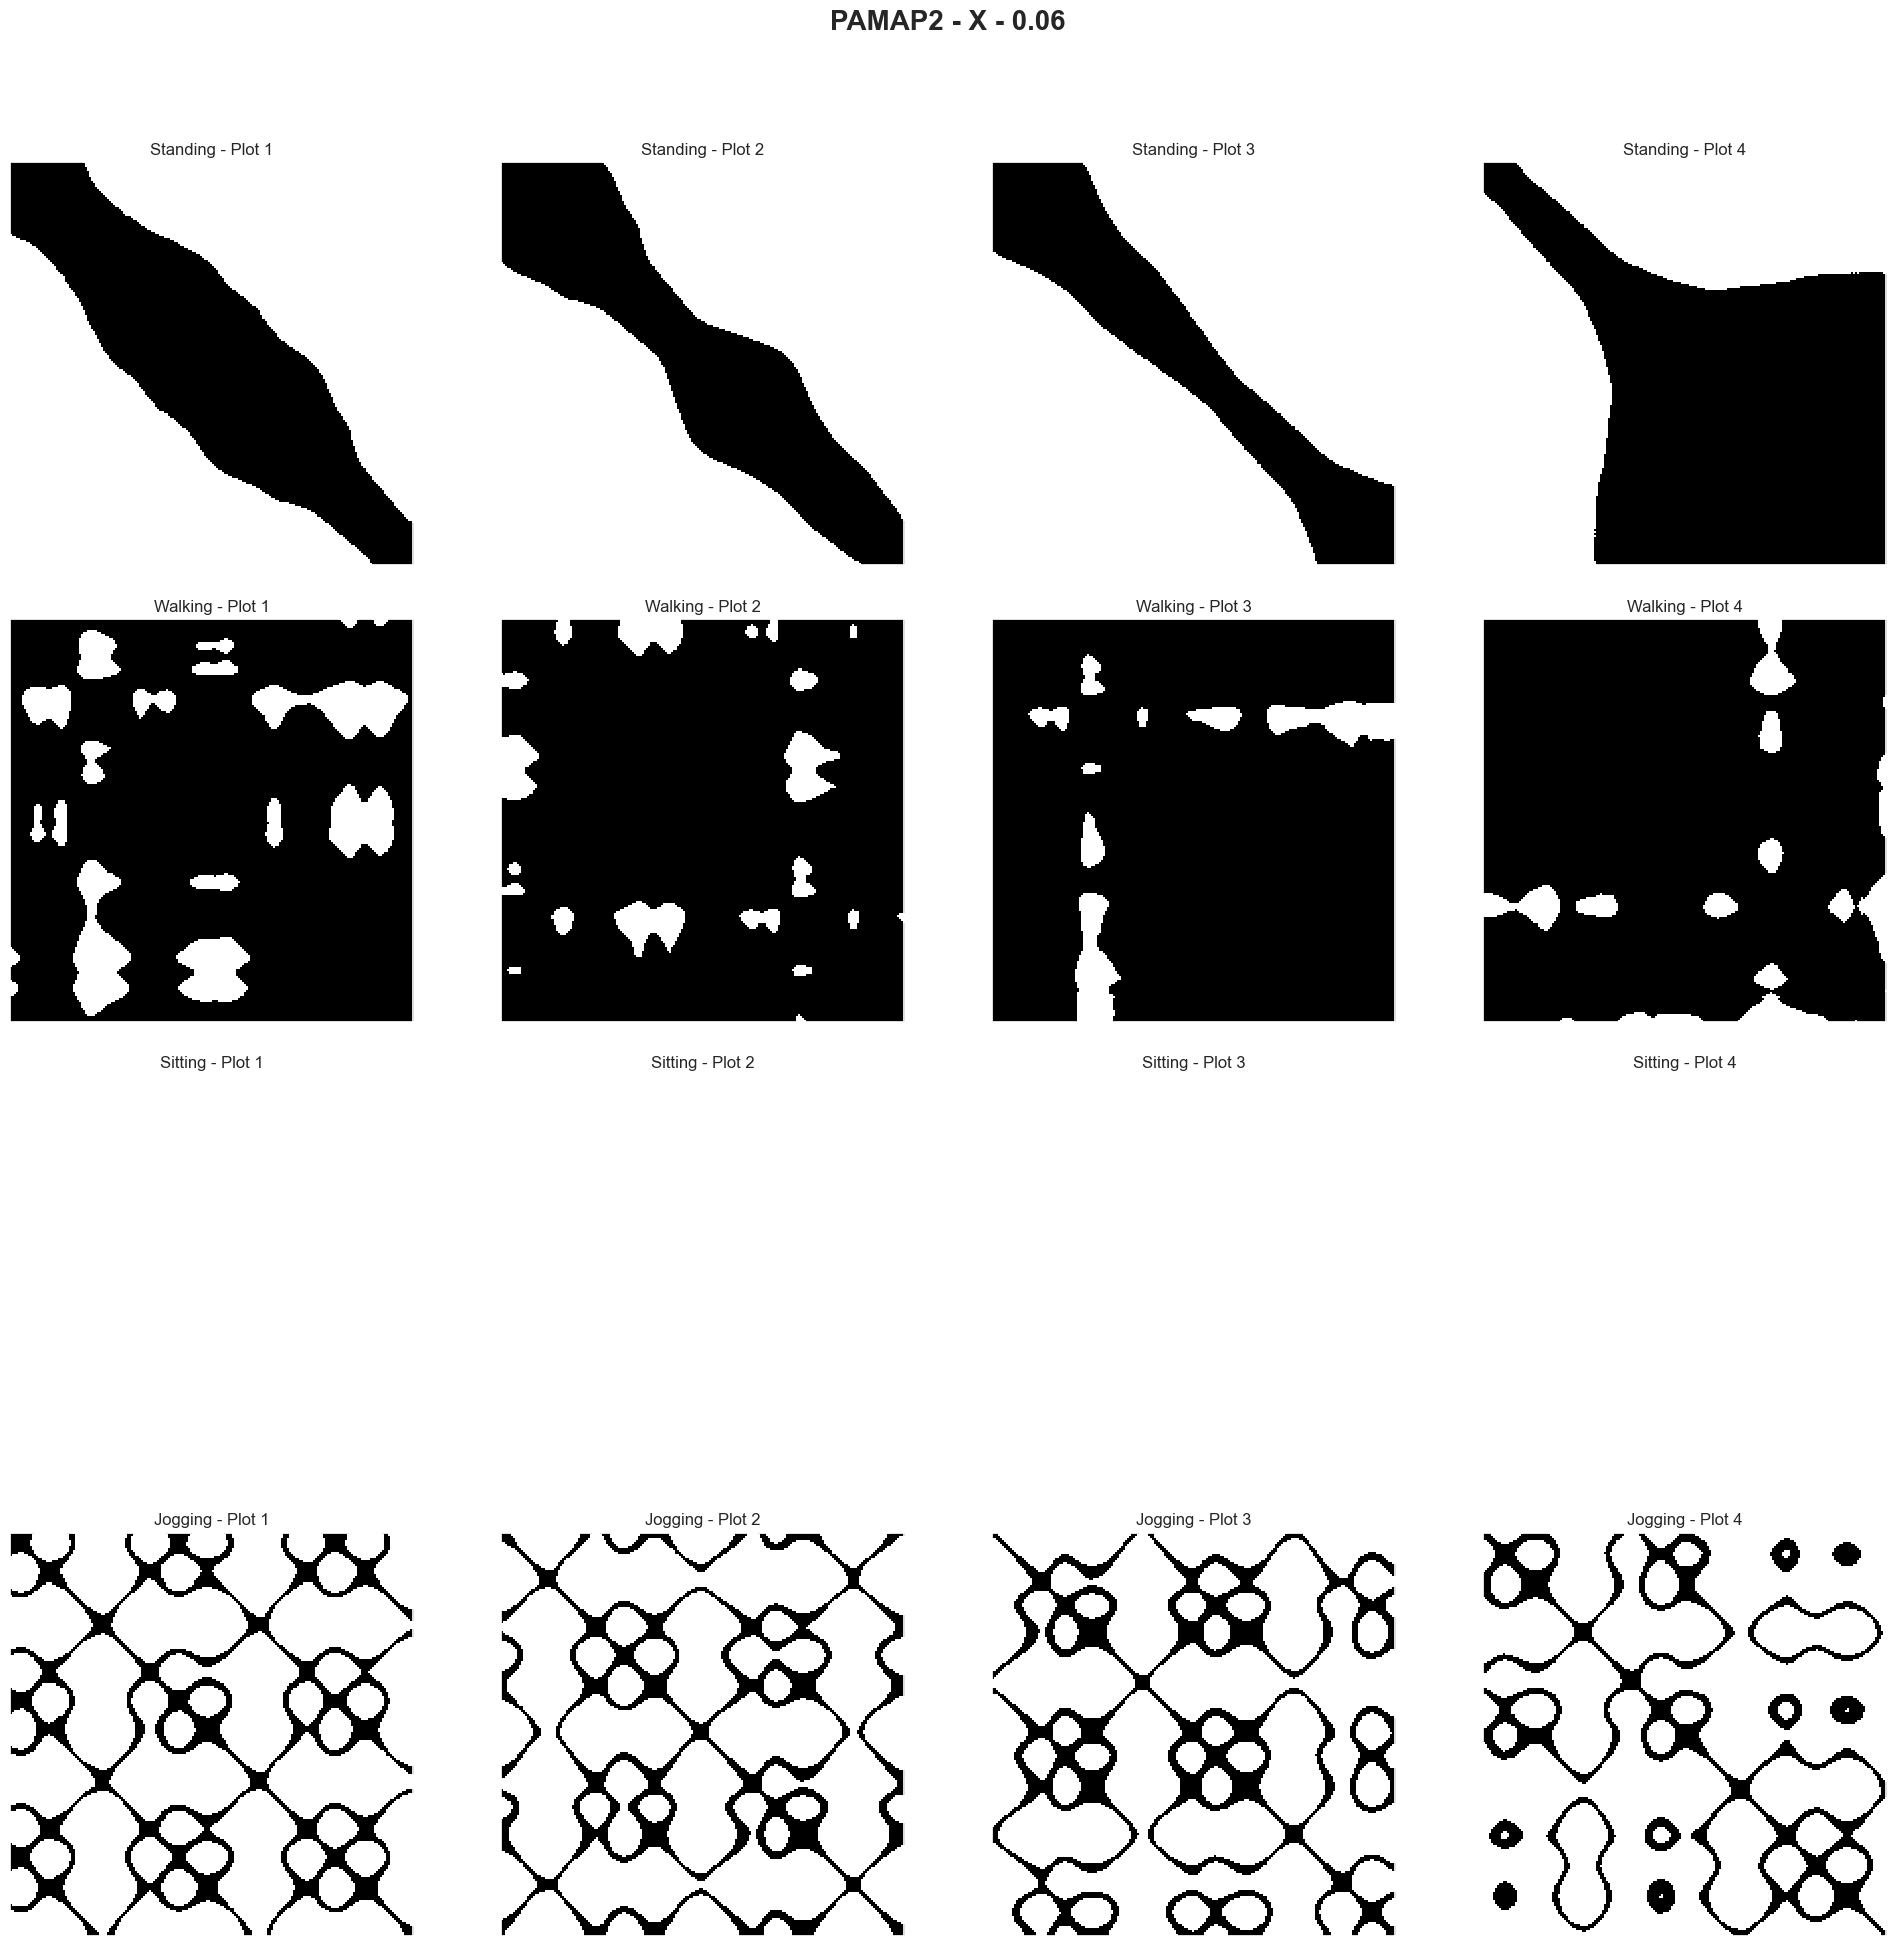

In [57]:
data = {"Standing": standing_data[x_axis].to_numpy(), "Walking": walking_data[x_axis].to_numpy(), "Sitting": sitting_data[x_axis].to_numpy(), "Jogging": jogging_data[x_axis].to_numpy()}

plot_recurrence_by_activity(data, "PAMAP2", "X",threshold_vector, step=200, first=3000)

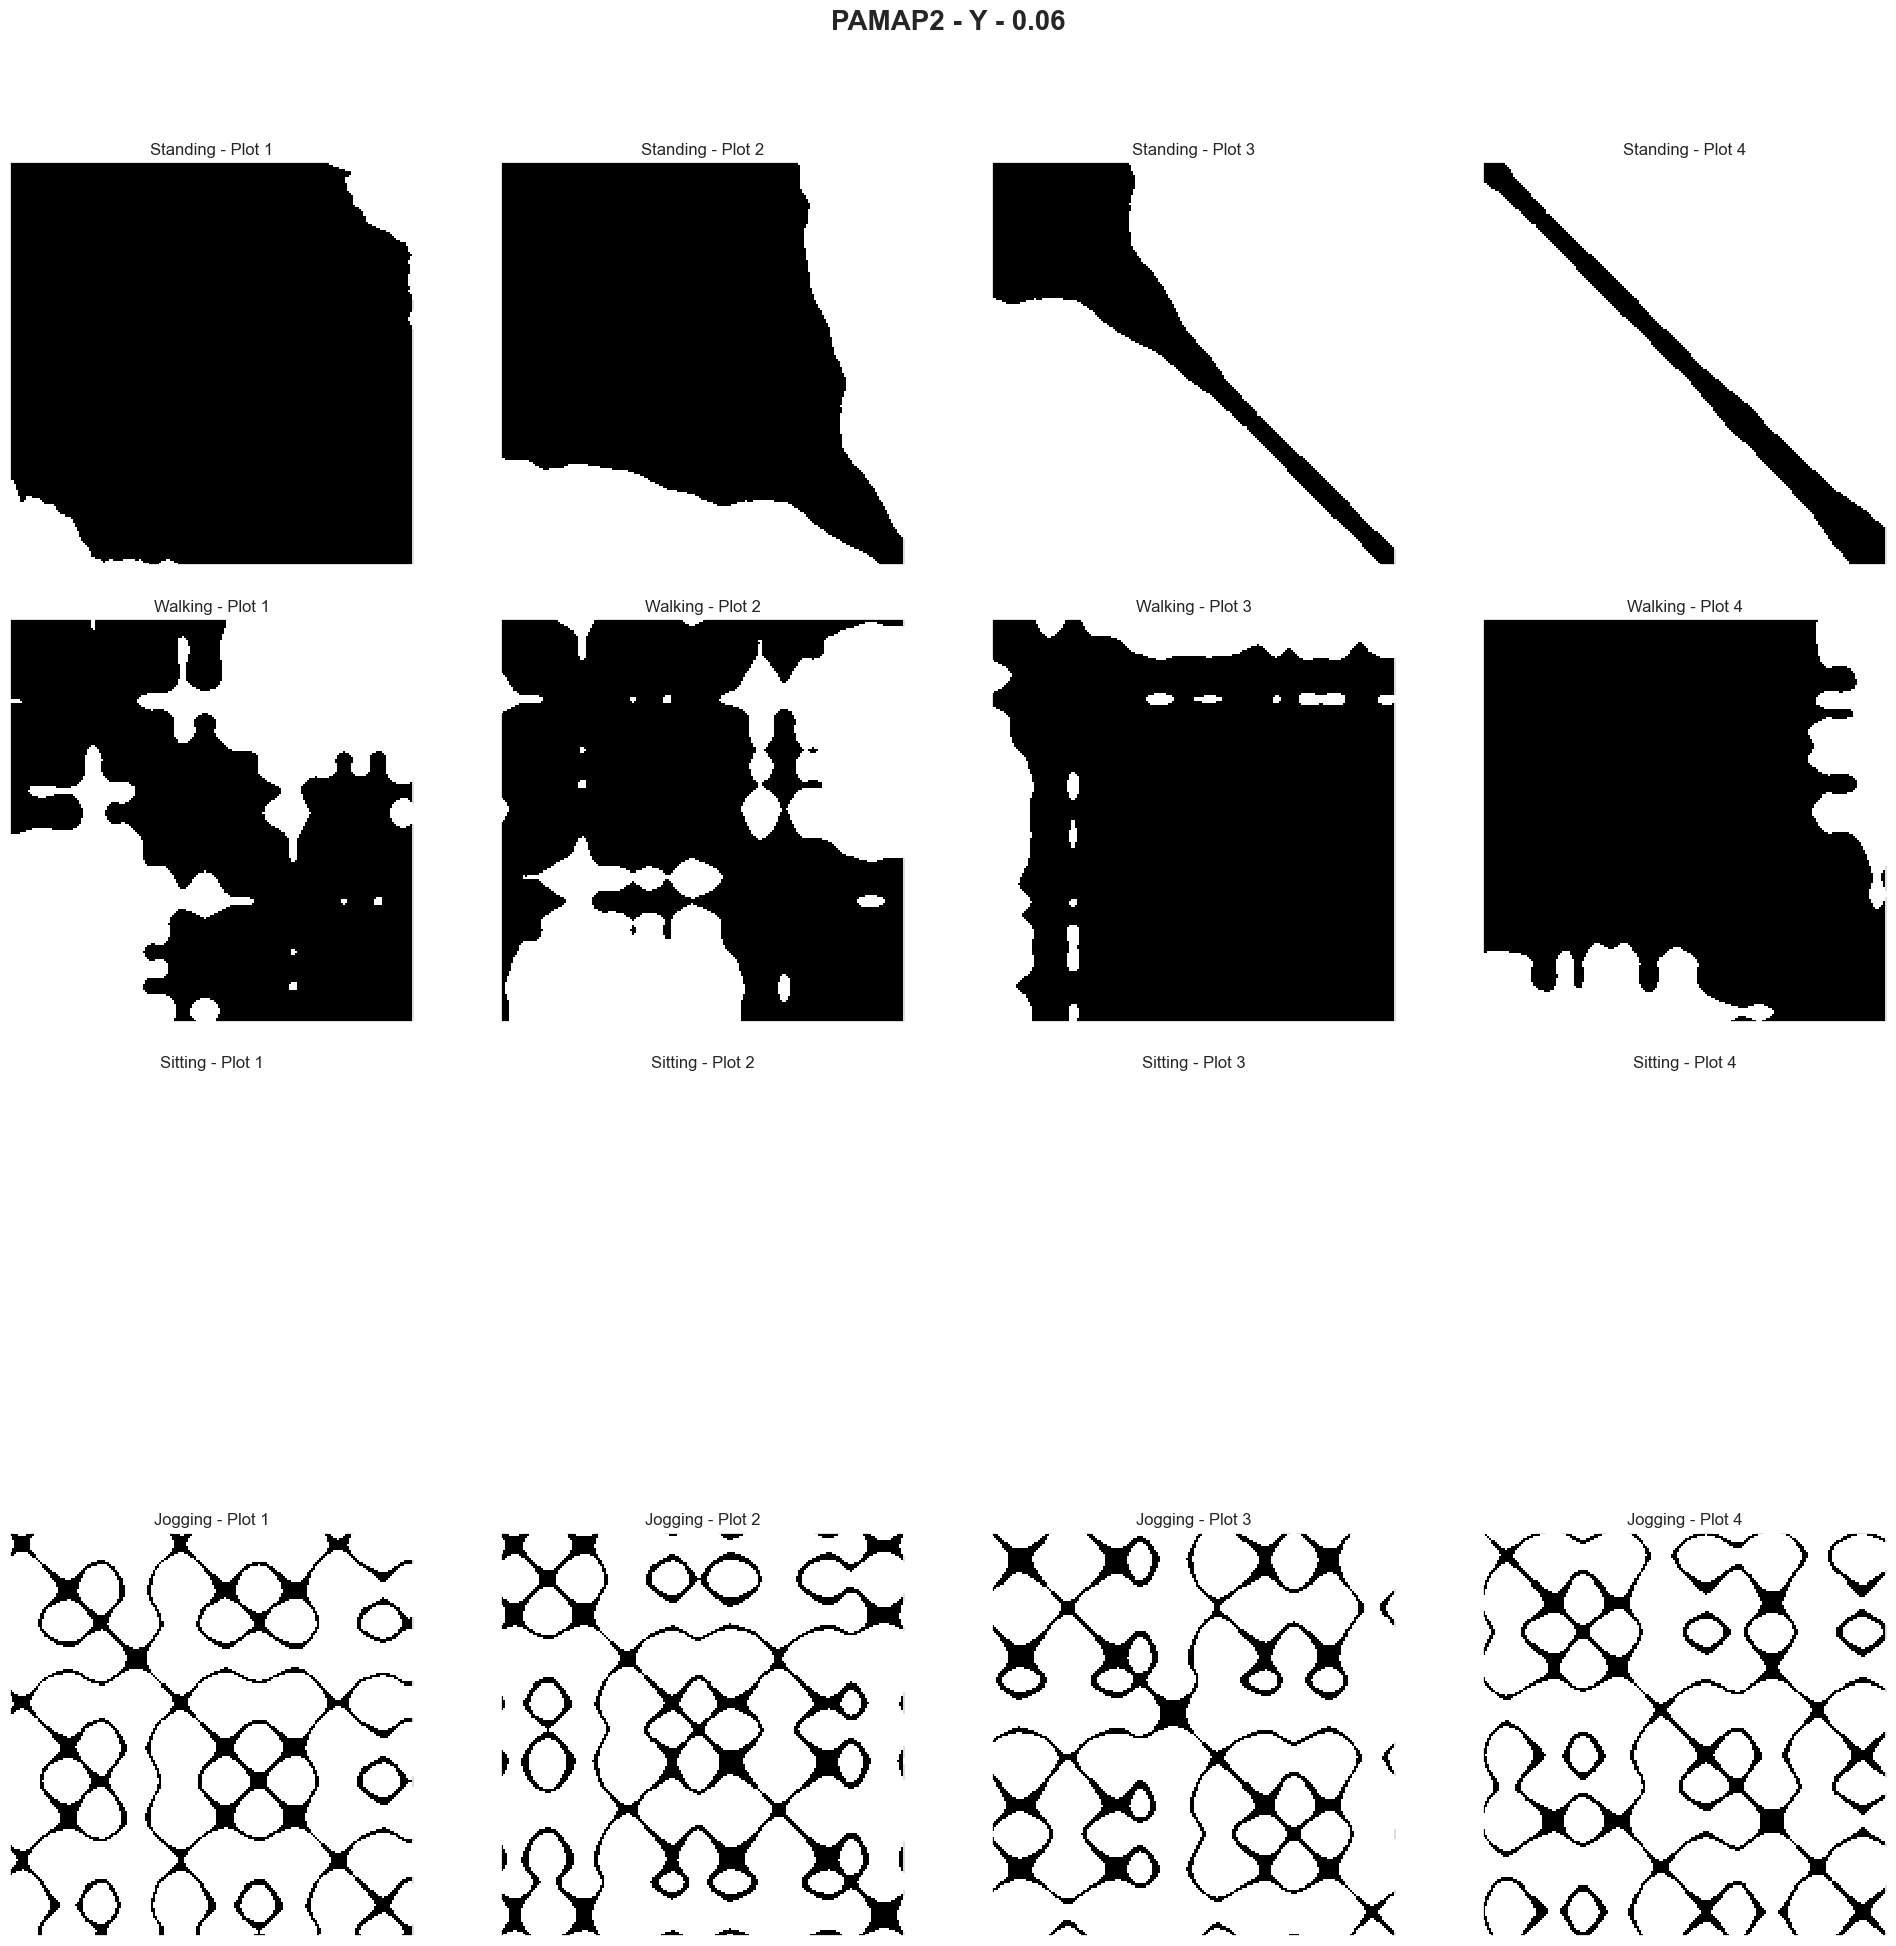

In [58]:
data = {"Standing": standing_data[y_axis].to_numpy(), "Walking": walking_data[y_axis].to_numpy(), "Sitting": sitting_data[y_axis].to_numpy(), "Jogging": jogging_data[y_axis].to_numpy()}

plot_recurrence_by_activity(data, "PAMAP2", "Y",threshold_vector, step=200, first=3000)

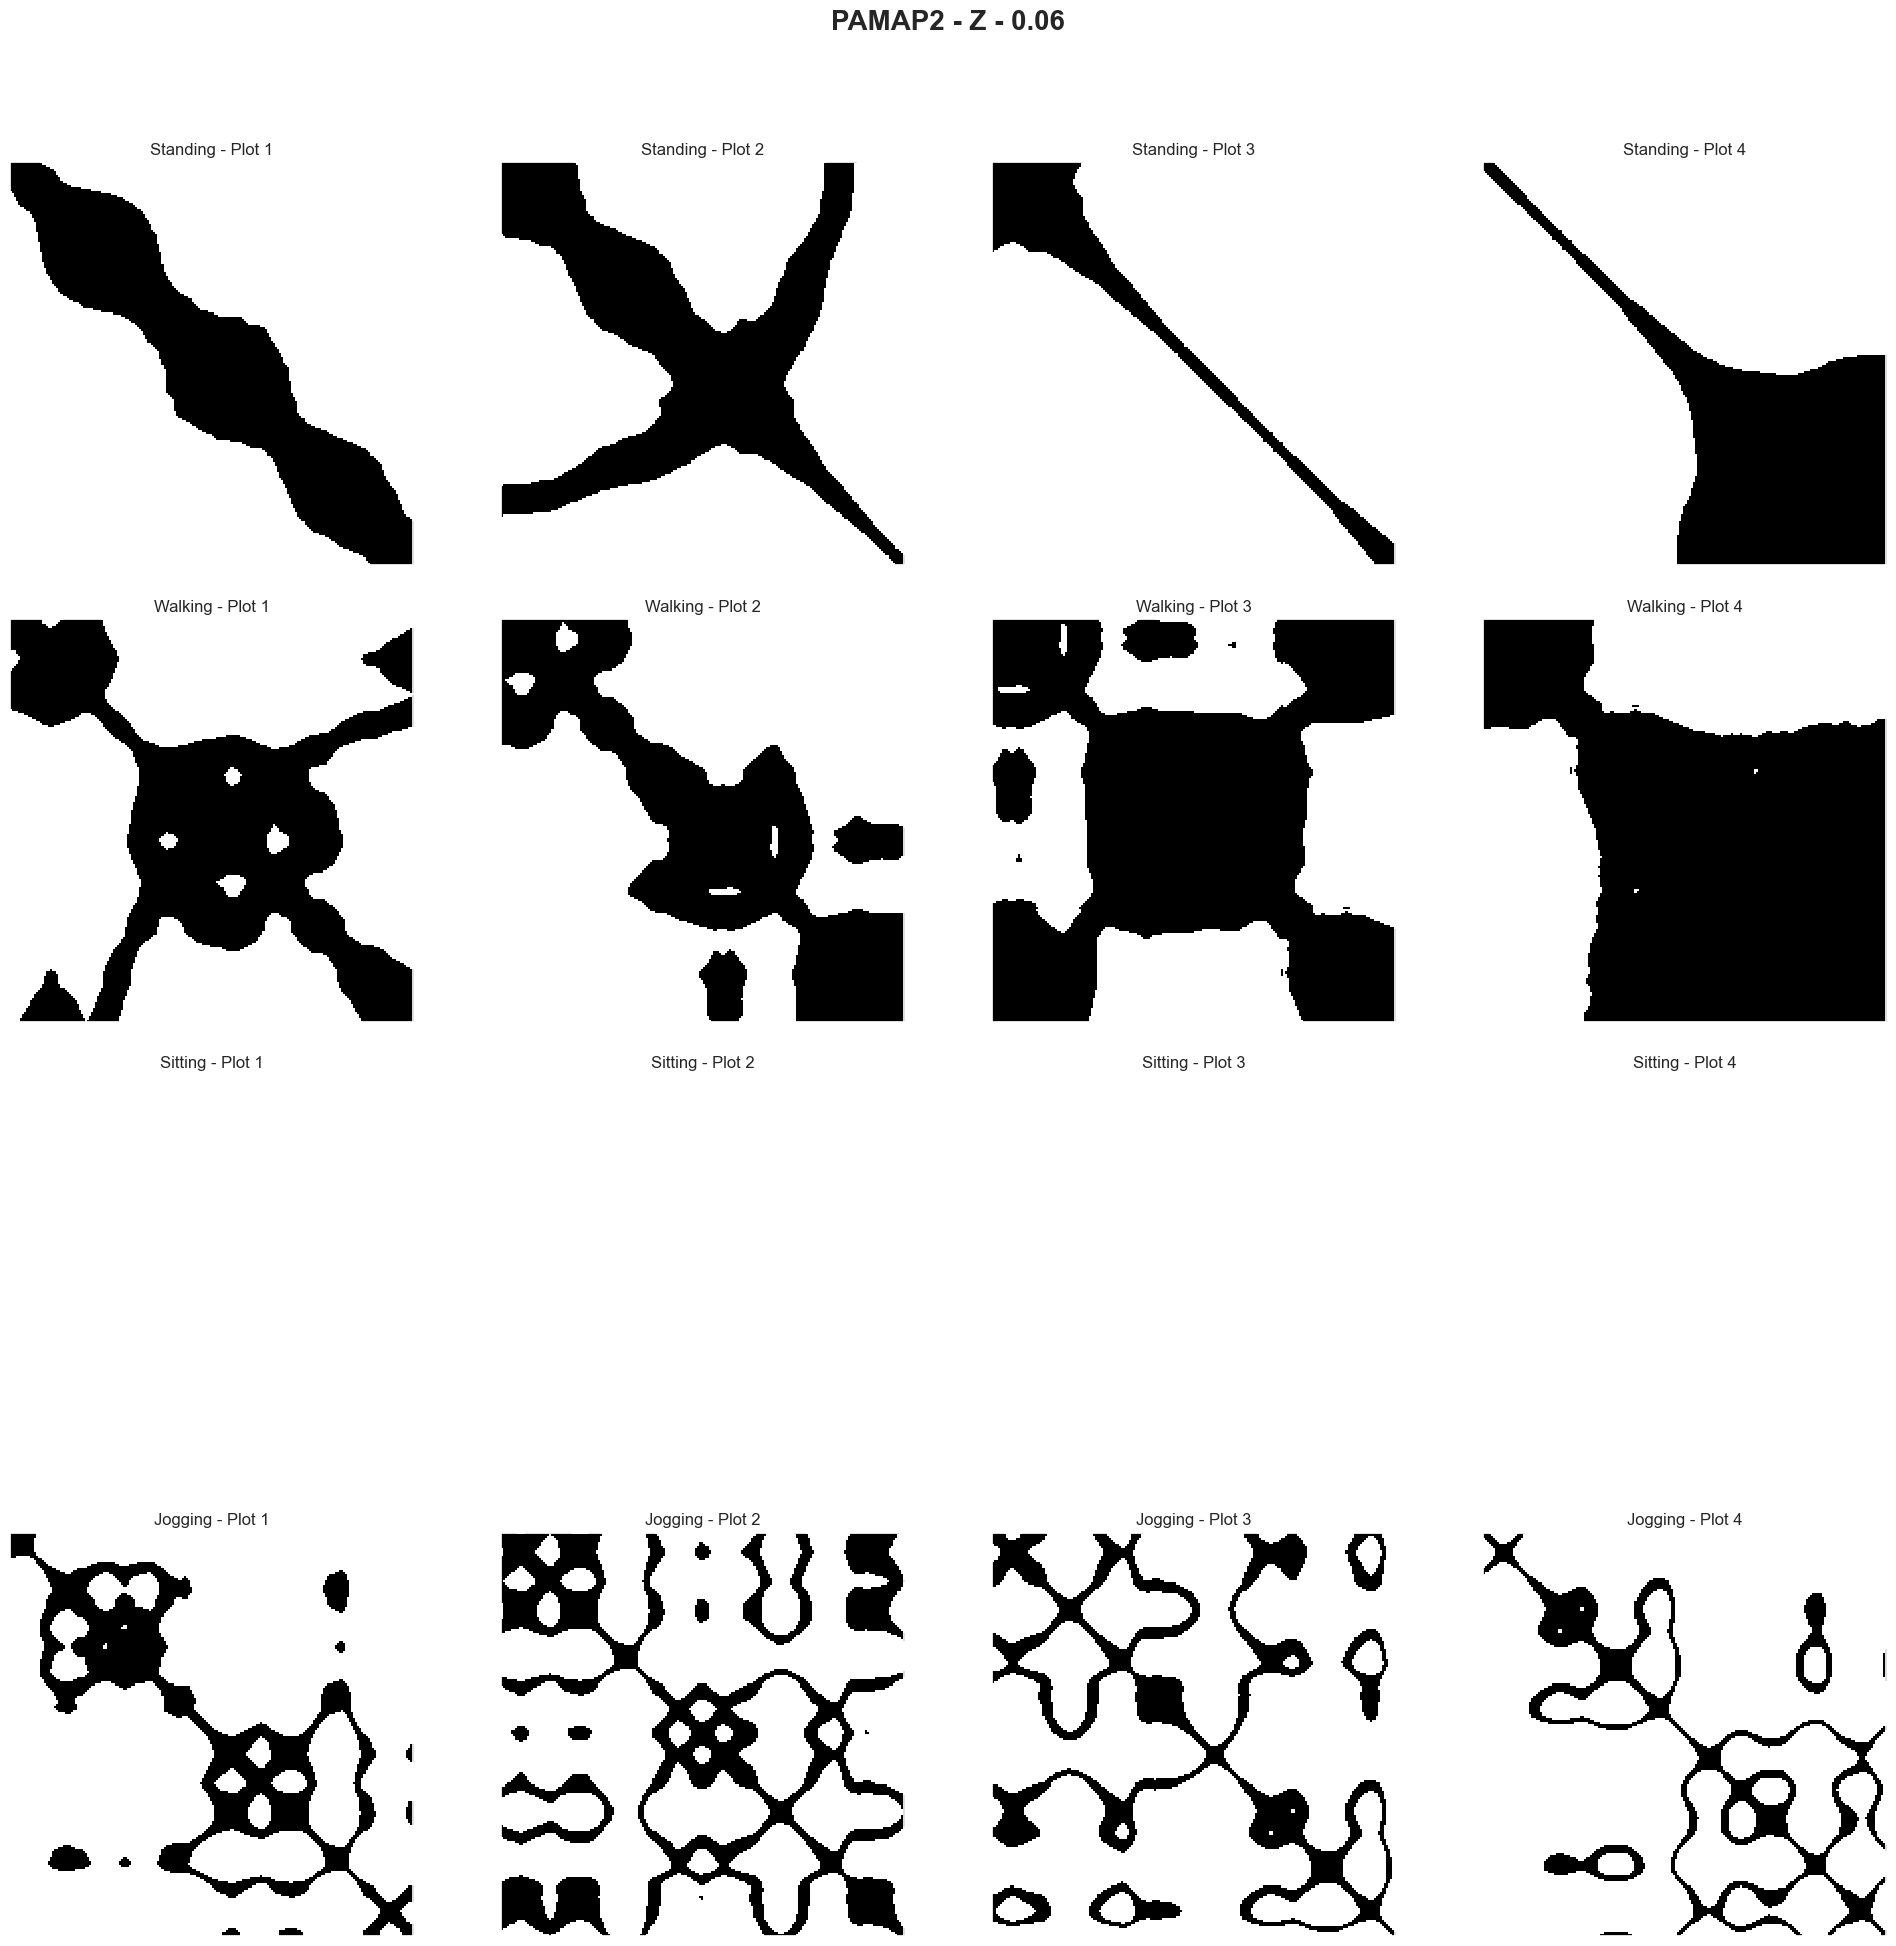

In [59]:
data = {"Standing": standing_data[z_axis].to_numpy(), "Walking": walking_data[z_axis].to_numpy(), "Sitting": sitting_data[z_axis].to_numpy(), "Jogging": jogging_data[z_axis].to_numpy()}

plot_recurrence_by_activity(data, "PAMAP2", "Z",threshold_vector, step=200, first=3000)

### Recurrence Plots- Vector

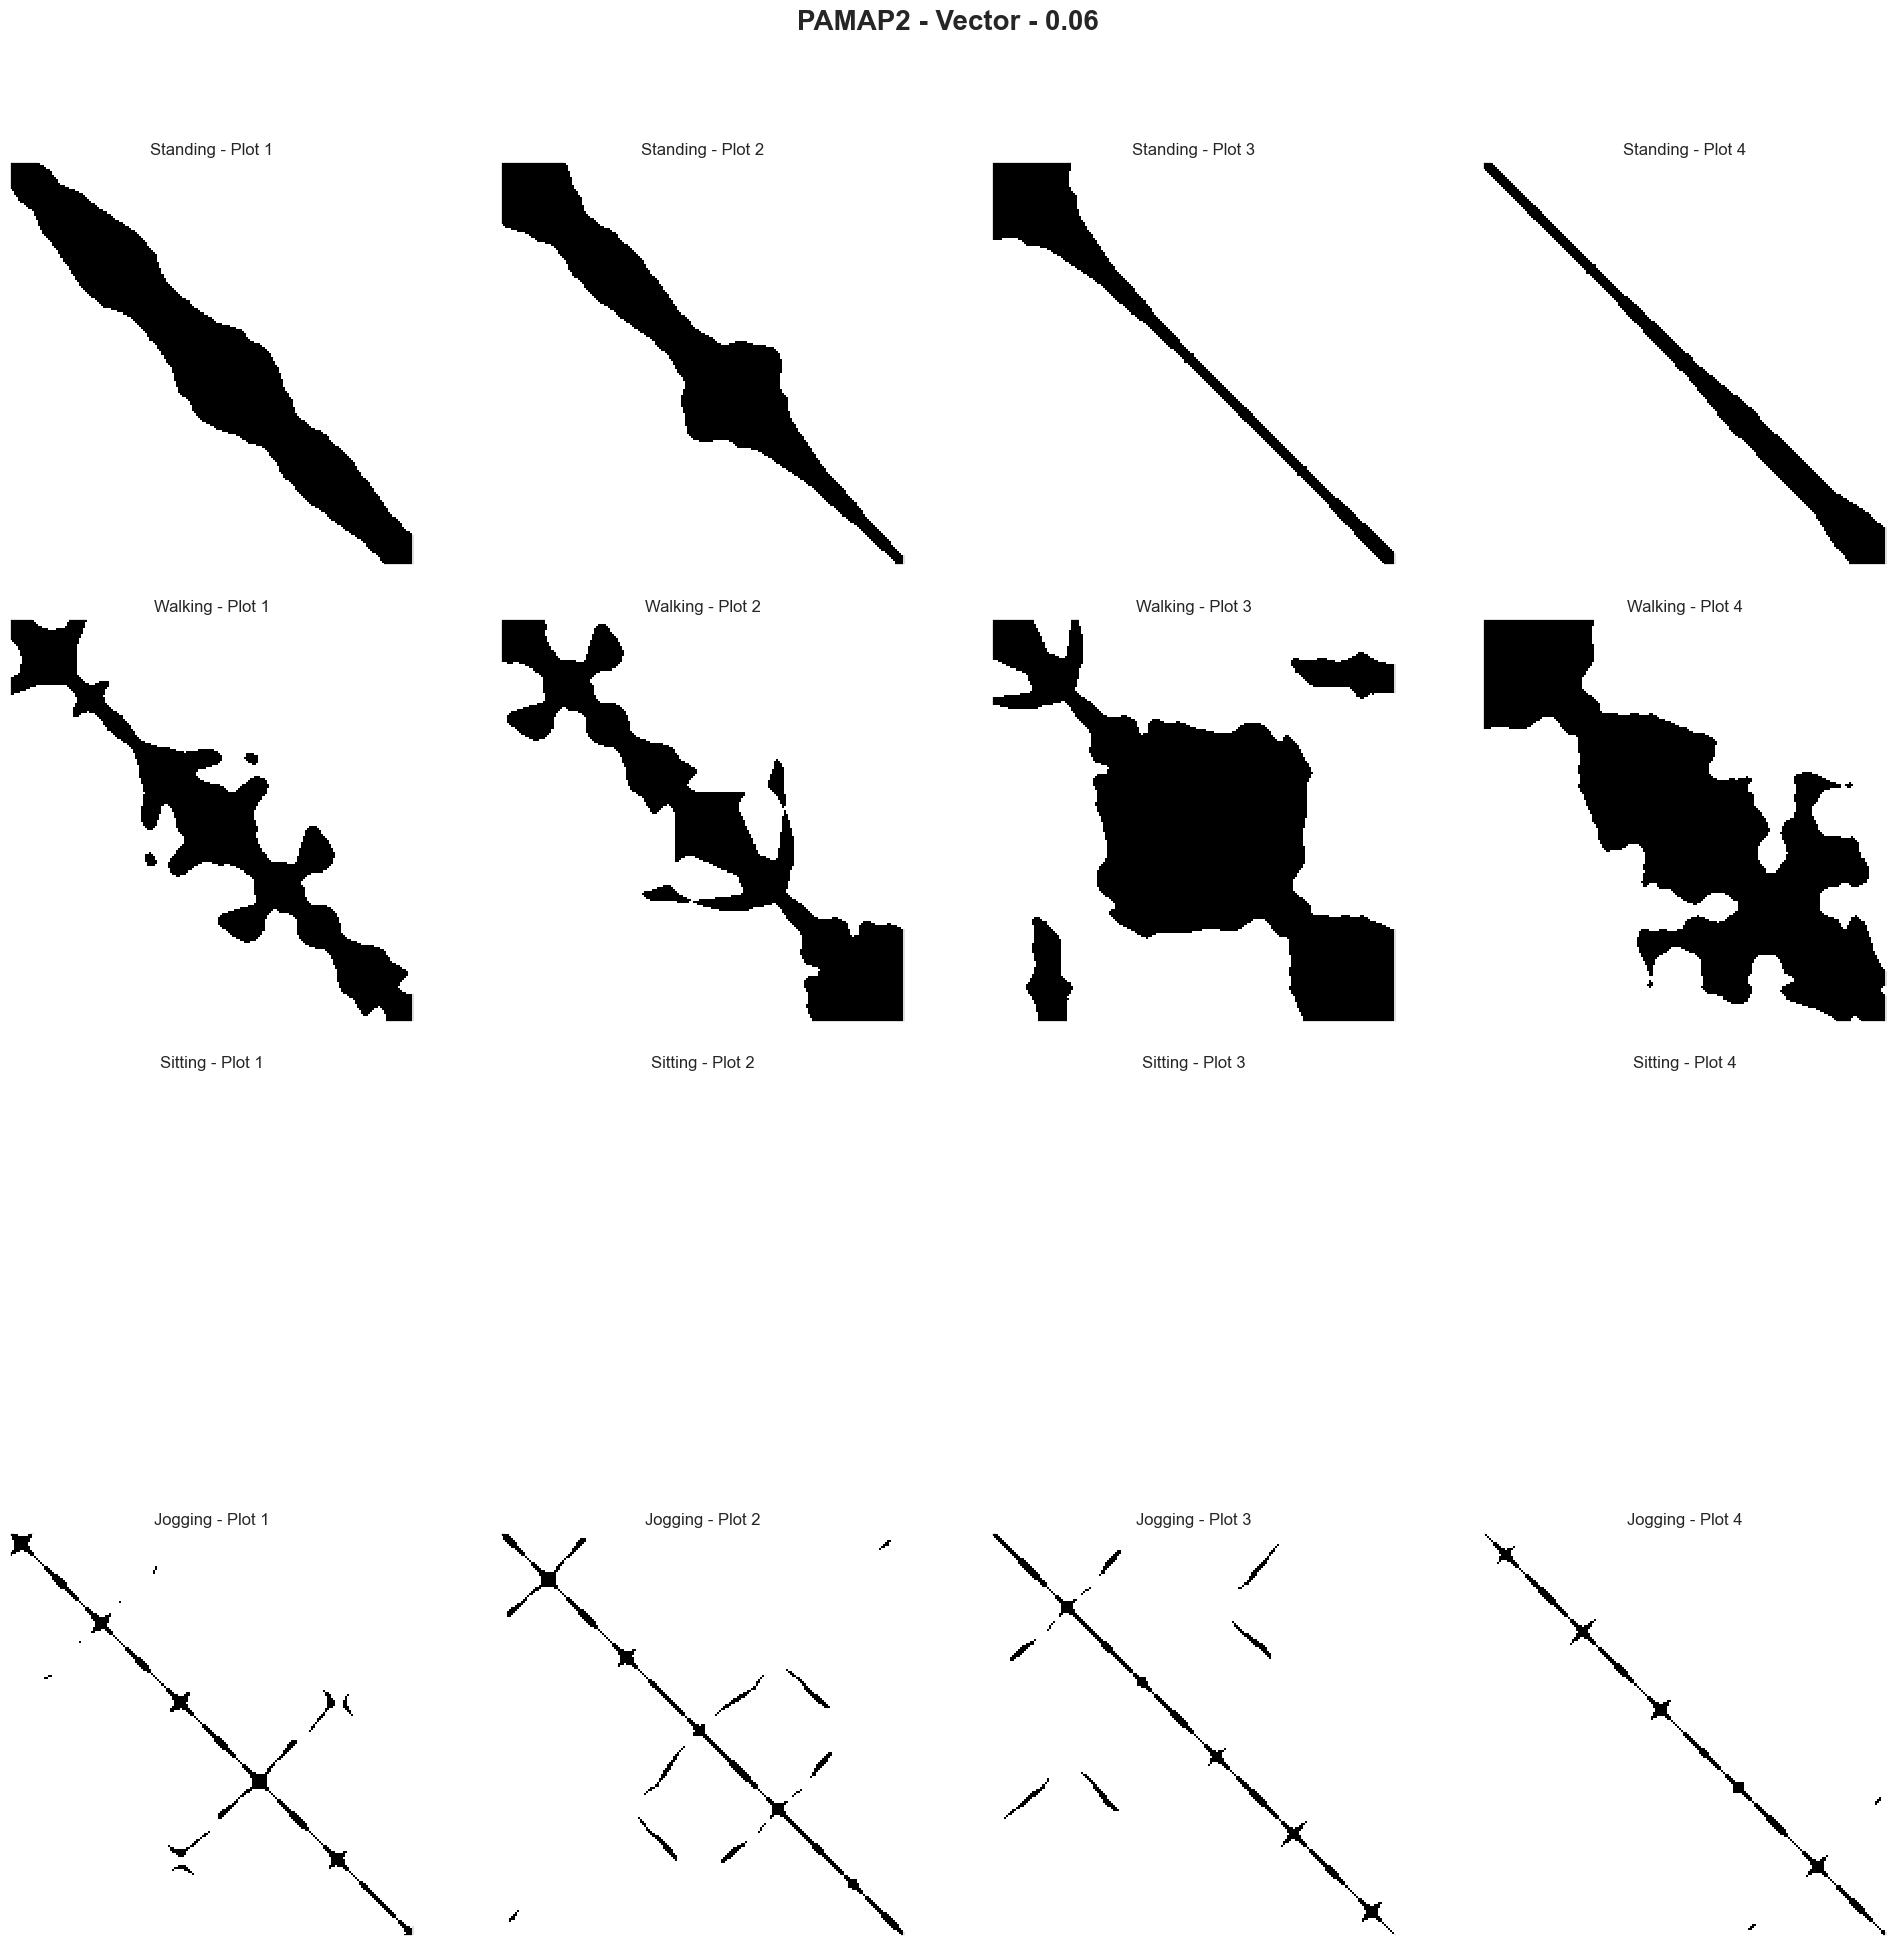

In [81]:
data = {"Standing": standing_vectors, "Walking": walking_vectors, "Sitting": sitting_vectors, "Jogging": jogging_vectors}

plot_recurrence_by_activity(data, "PAMAP2", "Vector", threshold_vector, step=200, first=3000)

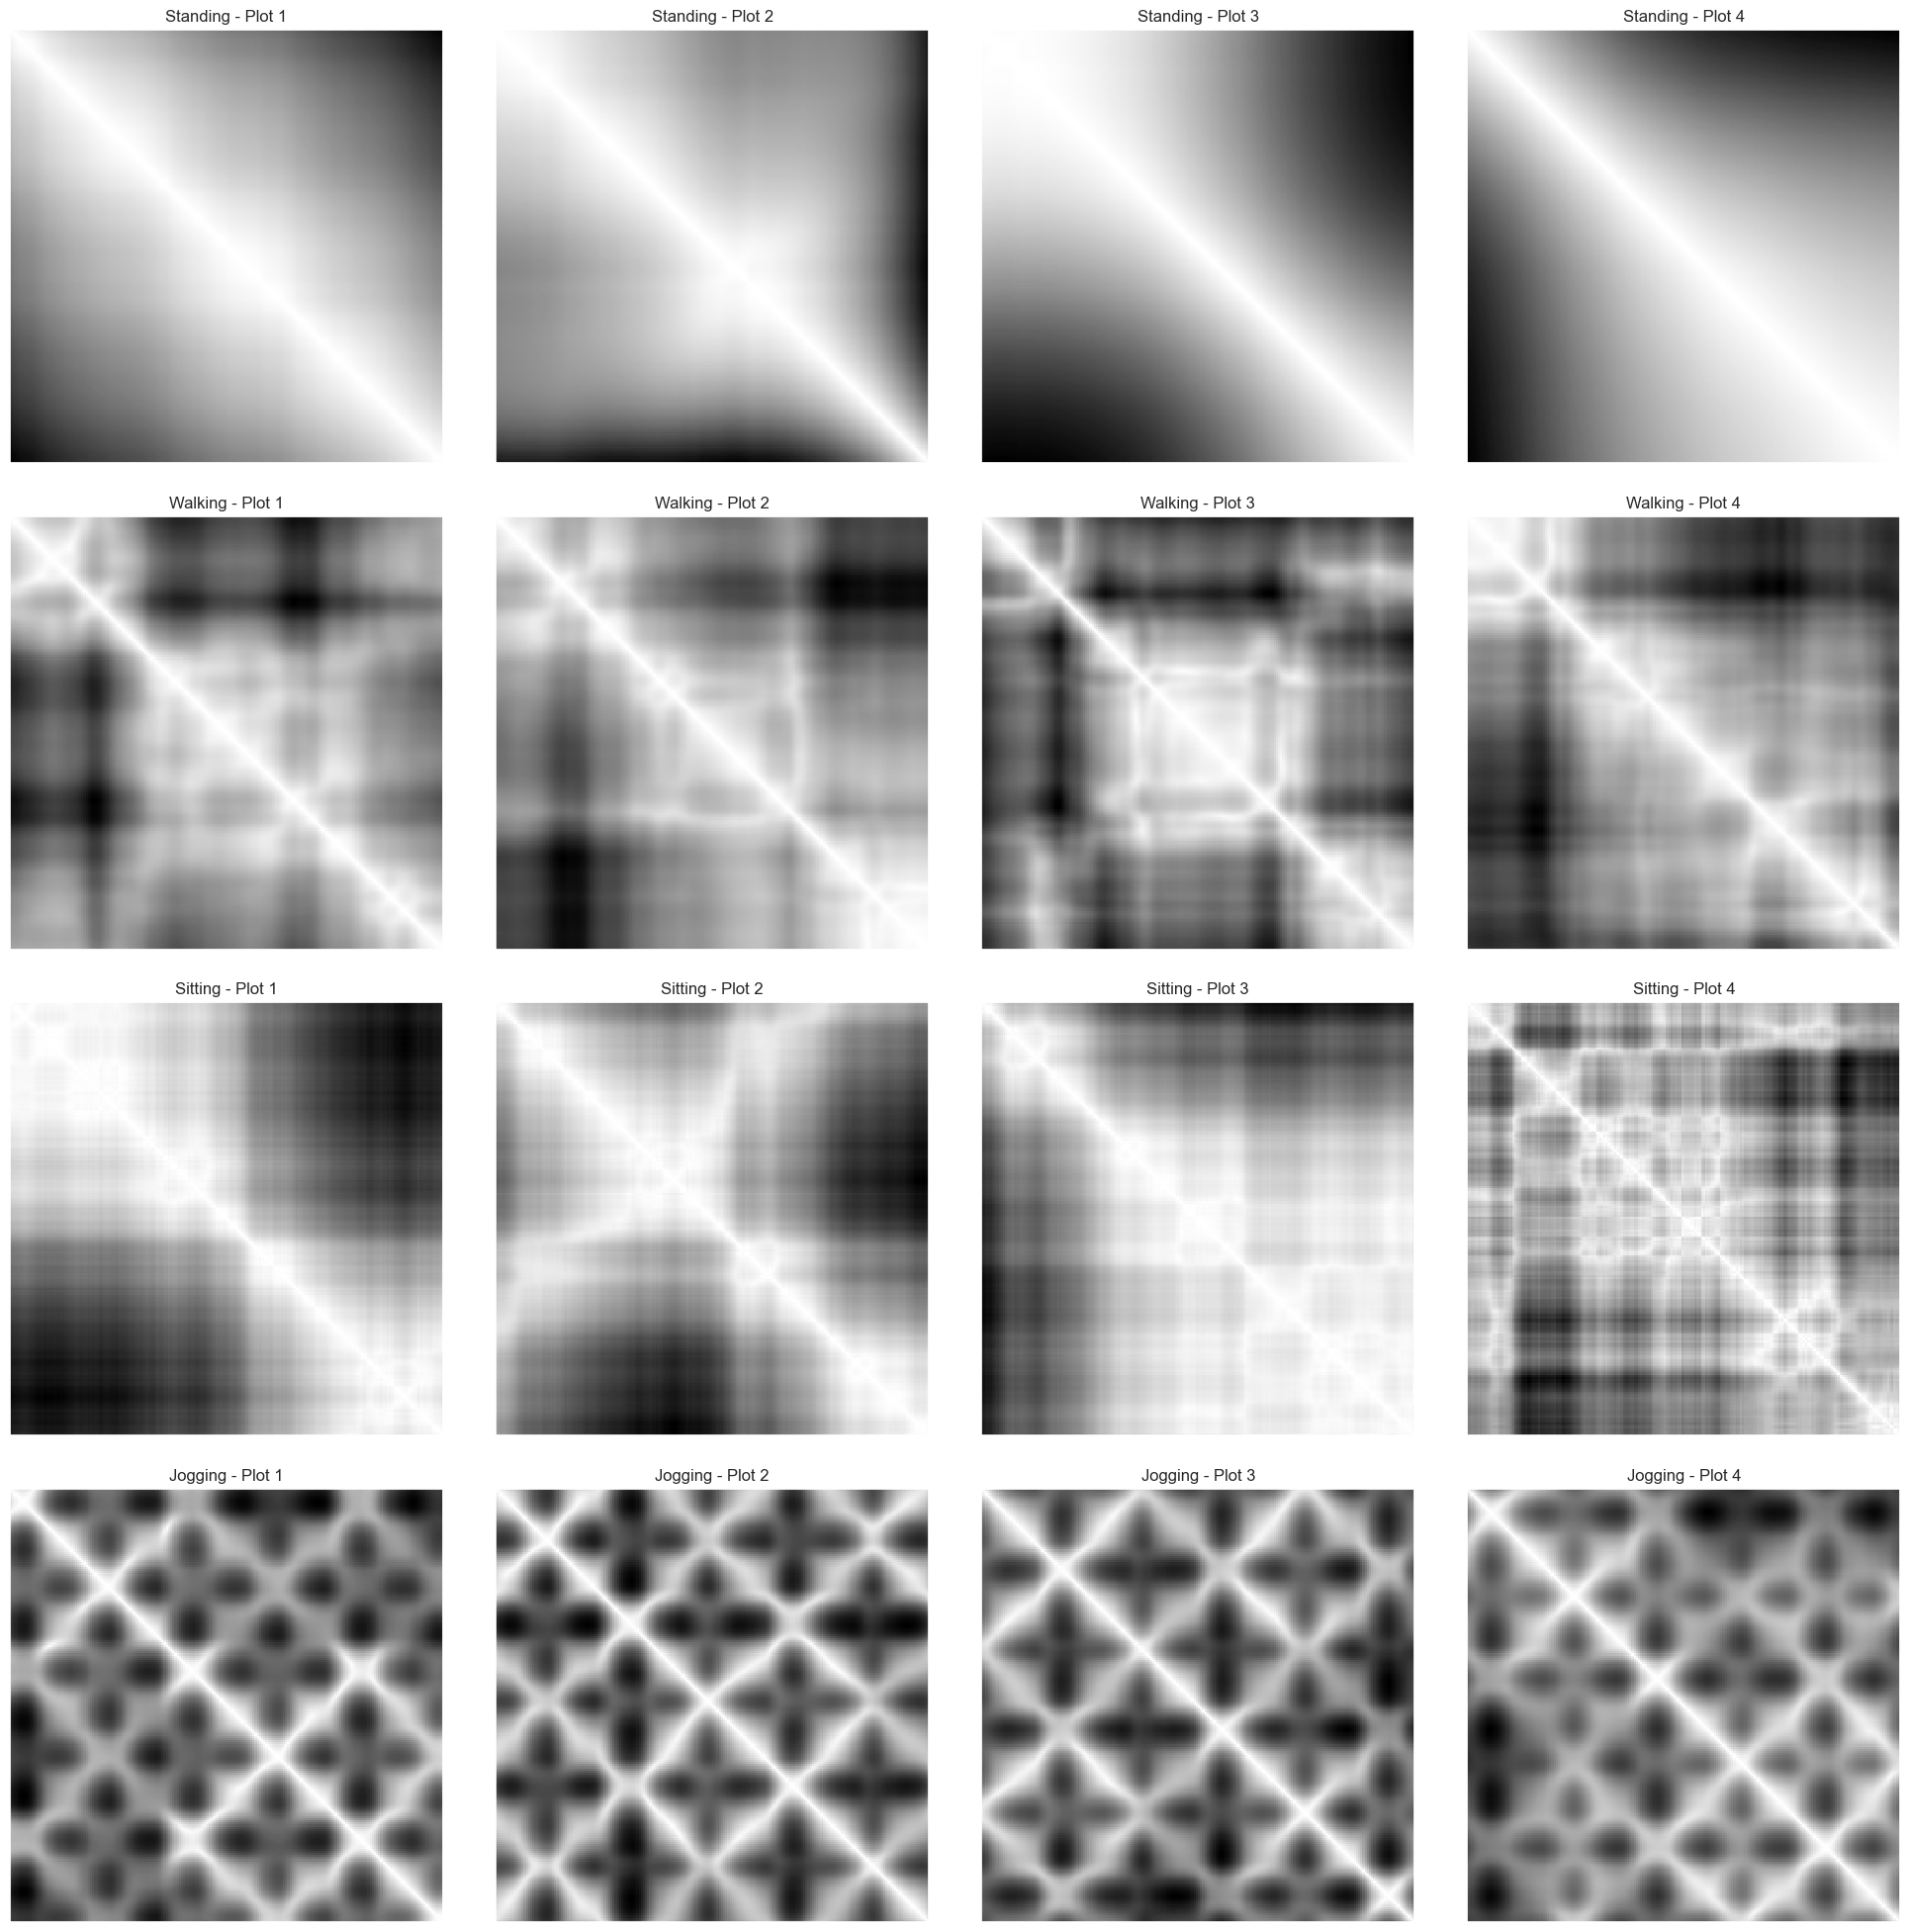

In [82]:
data = {"Standing": standing_vectors, "Walking": walking_vectors, "Sitting": sitting_vectors, "Jogging": jogging_vectors}

plot_recurrence_by_activity_grayscale(data, bins=256, step=200, first=3000)

### Distance Analysis

In [163]:
walking_distances = calculate_distances_in_batches(walking_vectors)
jogging_distances = calculate_distances_in_batches(jogging_vectors)
sitting_distances = calculate_distances_in_batches(sitting_vectors)
standing_distances = calculate_distances_in_batches(standing_vectors)

distances = np.concatenate((walking_distances, jogging_distances, sitting_distances, standing_distances))
len(distances)

6264658

In [164]:
distances = distances[~np.isnan(distances)]
len(distances)

6264658

In [165]:
# Calculate Z-scores
z_scores = np.abs(stats.zscore(distances))

# Define threshold for identifying outliers (commonly 3)
threshold = 3

# Filter out the outliers
filtered_distances = distances[z_scores < threshold]

len(filtered_distances), max(filtered_distances), min(filtered_distances)

(6102828, 6.104926407047724, 0.0)

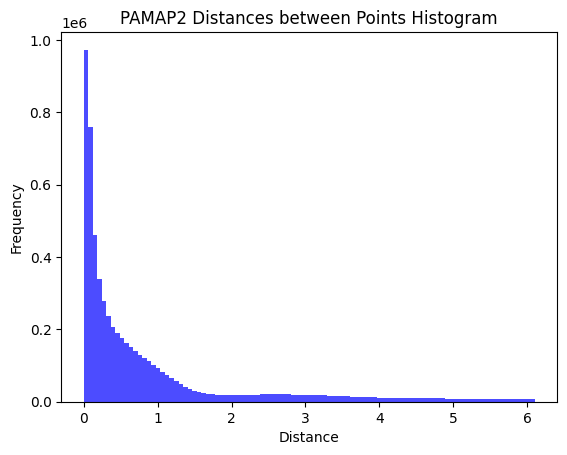

In [166]:
plt.hist(filtered_distances, bins=100, color='blue', alpha=0.7)

# Set y-axis to log scale

# Add title and labels
plt.title('PAMAP2 Distances between Points Histogram')
plt.xlabel('Distance')
plt.ylabel('Frequency')

# Show the plot
plt.show()

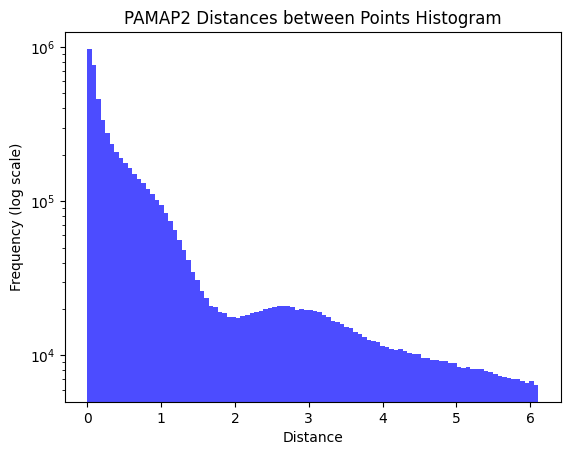

In [167]:
plt.hist(filtered_distances, bins=100, color='blue', alpha=0.7)

# Set y-axis to log scale
plt.yscale('log')

# Add title and labels
plt.title('PAMAP2 Distances between Points Histogram')
plt.xlabel('Distance')
plt.ylabel('Frequency (log scale)')

# Show the plot
plt.show()

In [168]:
NUMBER_OF_THRESHOLDS = 50
MIN_THRESHOLD = 0.00001
MAX_THRESHOLD = 1
t = np.linspace(MIN_THRESHOLD, 1, NUMBER_OF_THRESHOLDS)

threshold_list_linear = t * MAX_THRESHOLD
threshold_list_linear = threshold_list_linear.round(4)
threshold_list_linear

threshold_list = (t ** 3) * MAX_THRESHOLD
threshold_list = threshold_list.round(4)
threshold_list

array([0.000e+00, 0.000e+00, 1.000e-04, 2.000e-04, 5.000e-04, 1.100e-03,
       1.800e-03, 2.900e-03, 4.400e-03, 6.200e-03, 8.500e-03, 1.130e-02,
       1.470e-02, 1.870e-02, 2.330e-02, 2.870e-02, 3.480e-02, 4.180e-02,
       4.960e-02, 5.830e-02, 6.800e-02, 7.870e-02, 9.050e-02, 1.034e-01,
       1.175e-01, 1.328e-01, 1.494e-01, 1.673e-01, 1.866e-01, 2.073e-01,
       2.295e-01, 2.532e-01, 2.785e-01, 3.055e-01, 3.341e-01, 3.644e-01,
       3.966e-01, 4.305e-01, 4.664e-01, 5.042e-01, 5.440e-01, 5.858e-01,
       6.297e-01, 6.758e-01, 7.241e-01, 7.746e-01, 8.273e-01, 8.825e-01,
       9.400e-01, 1.000e+00])

### Haralick

In [171]:
dict_list_haralick_walking = find_haralick_values(recurrence_plot_vector_grayscale, walking_vectors, window_size=256, step=256, start=400)
dict_list_haralick_standing = find_haralick_values(recurrence_plot_vector_grayscale, standing_vectors, window_size=256, step=256, start=400)
dict_list_haralick_sitting = find_haralick_values(recurrence_plot_vector_grayscale, sitting_vectors, window_size=256, step=256, start=400)
dict_list_haralick_jogging = find_haralick_values(recurrence_plot_vector_grayscale, jogging_vectors, window_size=256, step=256, start=400)
dict_list_haralick_upstairs = find_haralick_values(recurrence_plot_vector_grayscale, upstairs_vectors, window_size=256, step=256, start=400)
dict_list_haralick_downstairs = find_haralick_values(recurrence_plot_vector_grayscale, downstairs_vectors, window_size=256, step=256, start=400)

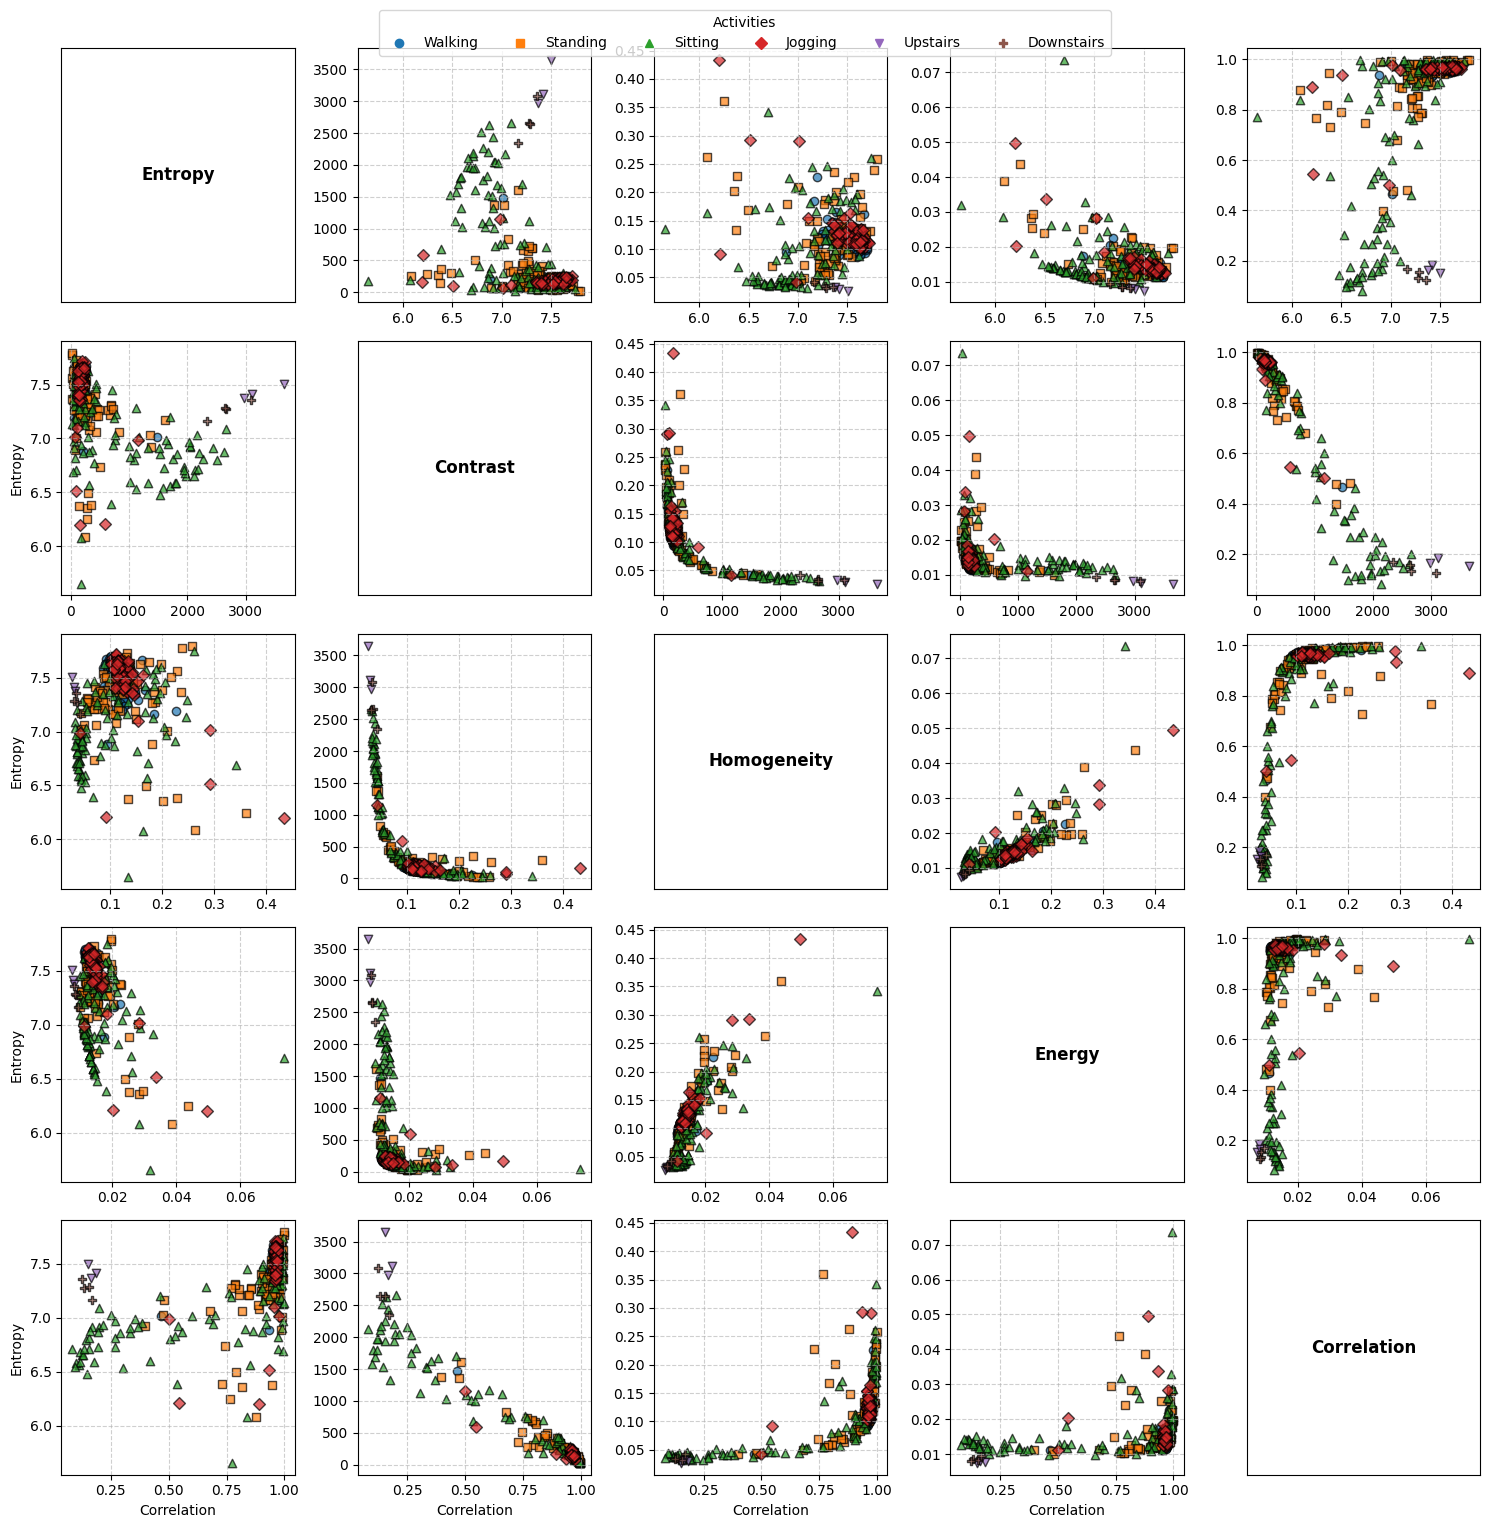

In [172]:
# Combine metrics and activity labels
metrics_dicts = [
    dict_list_haralick_walking,
    dict_list_haralick_standing,
    dict_list_haralick_sitting,
    dict_list_haralick_jogging,
    dict_list_haralick_upstairs,
    dict_list_haralick_downstairs
]
metric_names = [
    'entropy', 
    'contrast', 
    # 'dissimilarity', 
    'homogeneity', 
    'energy', 
    'correlation', 
    # 'ASM'
    ]
activity_labels = ["Walking", "Standing", "Sitting", "Jogging", "Upstairs", "Downstairs"]

# Plot the metric matrix
plot_metric_matrix(metrics_dicts, activity_labels, metric_names)

### Entropy and Threshold Calculation

In [101]:
best_walking, dict_scores_walking = find_best_threshold_weighted(recurrence_plot_vector, threshold_list, walking_vectors, window_size=200, step=200, start=400)
print(f"Walking: {best_walking} | Score: {dict_scores_walking[best_walking]}")
best_standing, dict_scores_standing = find_best_threshold_weighted(recurrence_plot_vector, threshold_list, standing_vectors, window_size=200, step=200, start=400)
print(f"Standing: {best_standing} | Score: {dict_scores_standing[best_standing]}")
best_sitting, dict_scores_sitting = find_best_threshold_weighted(recurrence_plot_vector, threshold_list, sitting_vectors, window_size=200, step=200, start=400)
print(f"Sitting: {best_sitting} | Score: {dict_scores_sitting[best_sitting]}")
best_jogging, dict_scores_jogging = find_best_threshold_weighted(recurrence_plot_vector, threshold_list, jogging_vectors, window_size=200, step=200, start=400)
print(f"Jogging:{best_jogging} | Score: {dict_scores_jogging[best_jogging]}")

Walking: 0.6758 | Score: 1.1618697603108945
Standing: 0.2295 | Score: 1.0030307527071394
Sitting: 0.068 | Score: 0.8893326068593914
Jogging:1.0 | Score: 0.8914274021086795


In [102]:
best_walking, dict_entropies_walking = find_best_threshold(recurrence_plot_vector, threshold_list, walking_vectors, window_size=200, step=200, start=400)
print(f"Walking: {best_walking} | Entropy: {dict_entropies_walking[best_walking]}")
best_standing, dict_entropies_standing = find_best_threshold(recurrence_plot_vector, threshold_list, standing_vectors, window_size=200, step=200, start=400)
print(f"Standing: {best_standing} | Entropy: {dict_entropies_standing[best_standing]}")
best_sitting, dict_entropies_sitting = find_best_threshold(recurrence_plot_vector, threshold_list, sitting_vectors, window_size=200, step=200, start=400)
print(f"Sitting: {best_sitting} | Entropy: {dict_entropies_sitting[best_sitting]}")
best_jogging, dict_entropies_jogging = find_best_threshold(recurrence_plot_vector, threshold_list, jogging_vectors, window_size=200, step=200, start=400)
print(f"Jogging:{best_jogging} | Entropy: {dict_entropies_jogging[best_jogging]}")

Walking: 0.6758 | Entropy: 0.9539218544074781
Standing: 0.2532 | Entropy: 0.6963734924936569
Sitting: 0.0583 | Entropy: 0.5931717484332764
Jogging:1.0 | Entropy: 0.4681426592321146


In [69]:
# determinants_walking = find_determinants(recurrence_matrix_vector, walking_vectors, window_size=200, step=200, start=400)
# print(f"Mean Determinant Walking: {np.mean(determinants_walking)}")
# determinants_standing = find_determinants(recurrence_matrix_vector, standing_vectors, window_size=200, step=200, start=400)
# print(f"Mean Determinant Standing: {np.mean(determinants_standing)}")
# determinants_sitting = find_determinants(recurrence_matrix_vector, sitting_vectors, window_size=200, step=200, start=400)
# print(f"Mean Determinant Sitting: {np.mean(determinants_sitting)}")
# determinants_jogging = find_determinants(recurrence_matrix_vector, jogging_vectors, window_size=200, step=200, start=400)
# print(f"Mean Determinant Jogging: {np.mean(determinants_jogging)}")

Mean Determinant Walking: -3.524847e-318
Mean Determinant Standing: -1.6464569926654316e-295
Mean Determinant Sitting: -2.4156599178945733e-283
Mean Determinant Jogging: -2.4477718224137418e-183


In [ ]:
results = {}
for i_threshold in threshold_list:    
    # Initialize a sub-dictionary for each threshold
    results[i_threshold] = {
        'Mean Laminarity Walking': None,
        'Mean Laminarity Standing': None,
        'Mean Laminarity Sitting': None,
        'Mean Laminarity Jogging': None,
    }
    
    laminarities_walking = find_laminarities(recurrence_plot_vector, i_threshold, walking_vectors, window_size=200, step=200, start=400, min_line_length=3)
    mean_laminarity_walking = np.mean(laminarities_walking)
    results[i_threshold]['Mean Laminarity Walking'] = mean_laminarity_walking

    laminarities_standing = find_laminarities(recurrence_plot_vector, i_threshold, standing_vectors, window_size=200, step=200, start=400, min_line_length=3)
    mean_laminarity_standing = np.mean(laminarities_standing)
    results[i_threshold]['Mean Laminarity Standing'] = mean_laminarity_standing

    laminarities_sitting = find_laminarities(recurrence_plot_vector, i_threshold, sitting_vectors, window_size=200, step=200, start=400, min_line_length=3)
    mean_laminarity_sitting = np.mean(laminarities_sitting)
    results[i_threshold]['Mean Laminarity Sitting'] = mean_laminarity_sitting

    laminarities_jogging = find_laminarities(recurrence_plot_vector, i_threshold, jogging_vectors, window_size=200, step=200, start=400, min_line_length=3)
    mean_laminarity_jogging = np.mean(laminarities_jogging)
    results[i_threshold]['Mean Laminarity Jogging'] = mean_laminarity_jogging

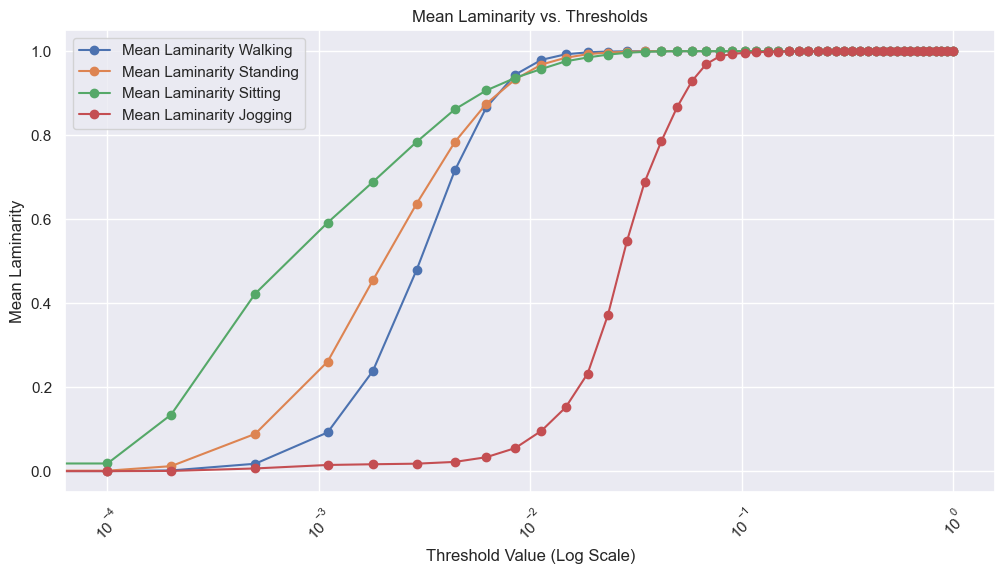

In [131]:
plot_laminarities(results)

### Plots Generation

In [70]:
# data_x = {"Standing": standing_data[x_axis].to_numpy(), "Walking": walking_data[x_axis].to_numpy(), "Sitting": sitting_data[x_axis].to_numpy(), "Jogging": jogging_data[x_axis].to_numpy()}
# data_y = {"Standing": standing_data[y_axis].to_numpy(), "Walking": walking_data[y_axis].to_numpy(), "Sitting": sitting_data[y_axis].to_numpy(), "Jogging": jogging_data[y_axis].to_numpy()}
# data_z = {"Standing": standing_data[z_axis].to_numpy(), "Walking": walking_data[z_axis].to_numpy(), "Sitting": sitting_data[z_axis].to_numpy(), "Jogging": jogging_data[z_axis].to_numpy()}
# data_vectors = {"Standing": standing_vectors, "Walking": walking_vectors, "Sitting": sitting_vectors, "Jogging": jogging_vectors}

# # RELATIVE_PATH = "../../results/recurrence_plots/PAMAP2/"
# RELATIVE_PATH = "C:/Users/tulio/Downloads/Plots/PAMAP2/"
# dataset_name = "PAMAP"

# for i in range(len(threshold_list)):
#     plot_recurrence_by_activity(data_x, dataset_name, "X", threshold_list[i], step=200, first=3000, filename=f"{RELATIVE_PATH}X/recurrence_pamap_x_{i}-{str(threshold_list[i])}")
#     plot_recurrence_by_activity(data_y, dataset_name, "Y", threshold_list[i], step=200, first=3000, filename=f"{RELATIVE_PATH}Y/recurrence_pamap_y_{i}-{str(threshold_list[i])}")
#     plot_recurrence_by_activity(data_z, dataset_name, "Z", threshold_list[i], step=200, first=3000, filename=f"{RELATIVE_PATH}Z/recurrence_pamap_z_{i}-{str(threshold_list[i])}")
#     plot_recurrence_by_activity(data_vectors, dataset_name, "Vector", threshold_list[i], step=200, first=3000, filename=f"{RELATIVE_PATH}Vector/recurrence_pamap_vector_{i}-{str(threshold_list[i])}")
    

In [71]:
# # Define the number of plots to generate
# num_plots = min(100, len(sitting_vectors) // 200)

# # Define the threshold value
# threshold_value = 0.0905

# # Loop through the number of plots and generate each plot
# for i in range(1, num_plots):
#     start_index = i * 200
#     end_index = start_index + 200
#     window_vectors = sitting_vectors[start_index:end_index]
    
#     # Calculate the recurrence matrix for the window
#     rec_matrix = recurrence_plot_vector(window_vectors, threshold_value)
    
#     # Plot and save the recurrence matrix
#     plot_recurrence_matrix_vector(rec_matrix, f"Sitting Recurrence Plot {i}", filename=f"../../results/recurrence_plots/WISDM_Sitting_examples/sitting_recurrence_plot_{i}")

## Opportunity 

### Dataset Preparation

In [132]:
# Function to normalize columns
def normalize_group(group):
    group[['accX', 'accY', 'accZ']] = (group[['accX', 'accY', 'accZ']] - group[['accX', 'accY', 'accZ']].mean()) / group[['accX', 'accY', 'accZ']].std()
    return group

opportunity = pd.read_csv('../../datasets/opportunity_preprocessed.csv')
opportunity = opportunity.dropna()
opportunity = opportunity.groupby('user_id').apply(normalize_group)
pamap2 = pamap2.rename(columns={
    'accX': 'accX',
    'accY': 'accY',
    'accZ': 'accZ'
})
opportunity = opportunity.reset_index(drop=True)
opportunity

C:\Users\tulio\AppData\Local\Temp\ipykernel_4584\2026013340.py:8: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  opportunity = opportunity.groupby('user_id').apply(normalize_group)


,timestamp,accX,accY,accZ,gyroX,gyroY,gyroZ,magneticX,magneticY,magneticZ,activity,user_id
0,0,-0.568511,0.505695,0.480930,-145.0,47.0,48.0,389.0,202.0,593.0,0,1
1,33,-0.611531,0.509278,0.447956,-318.0,-6.0,23.0,390.0,196.0,597.0,0,1
2,67,-0.584155,0.509278,0.388601,-426.0,13.0,49.0,392.0,192.0,598.0,0,1
3,100,-0.523537,0.437617,0.385304,-348.0,46.0,54.0,390.0,187.0,601.0,0,1
4,133,-0.484428,0.362373,0.421576,-329.0,76.0,100.0,389.0,179.0,605.0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...
854319,1008123,-0.837009,0.444280,-0.103575,222.0,858.0,-67.0,145.0,721.0,-92.0,0,5
854320,1008157,-0.805397,0.645619,0.100670,467.0,710.0,-110.0,142.0,720.0,-101.0,0,5
854321,1008190,-0.708804,0.648919,0.193509,436.0,392.0,-185.0,139.0,721.0,-111.0,0,5
854322,1008223,-0.733391,0.738036,0.119238,145.0,149.0,-121.0,136.0,720.0,-120.0,0,5


In [133]:
opportunity[['x_maf', 'y_maf', 'z_maf']] = opportunity.groupby('user_id')[['accX', 'accY', 'accZ']].rolling(window=30).mean().reset_index(drop=True)
opportunity[['x_ema', 'y_ema', 'z_ema']] = opportunity.groupby('user_id')[['accX', 'accY', 'accZ']].ewm(span=45, adjust=False).mean().reset_index(drop=True)

In [134]:
opportunity['activity'].value_counts()

activity
1    343119
2    197222
0    152420
4    136557
5     25006
Name: count, dtype: int64

In [135]:
walking_data = opportunity[(opportunity['activity'] == 2) & (opportunity['user_id'] == 1)]
walking_vectors = walking_data[[x_axis, y_axis, z_axis]].to_numpy()

standing_data = opportunity[(opportunity['activity'] == 1) & (opportunity['user_id'] == 1)]
standing_vectors = standing_data[[x_axis, y_axis, z_axis]].to_numpy()

sitting_data = opportunity[(opportunity['activity'] == 4) & (opportunity['user_id'] == 1)]
sitting_vectors = sitting_data[[x_axis, y_axis, z_axis]].to_numpy()

end = start + 60

threshold_axis = 0.008
threshold_vector = 0.05

print(len(walking_data)), print(len(standing_data))

53695
87257


(None, None)

### Time-series plot

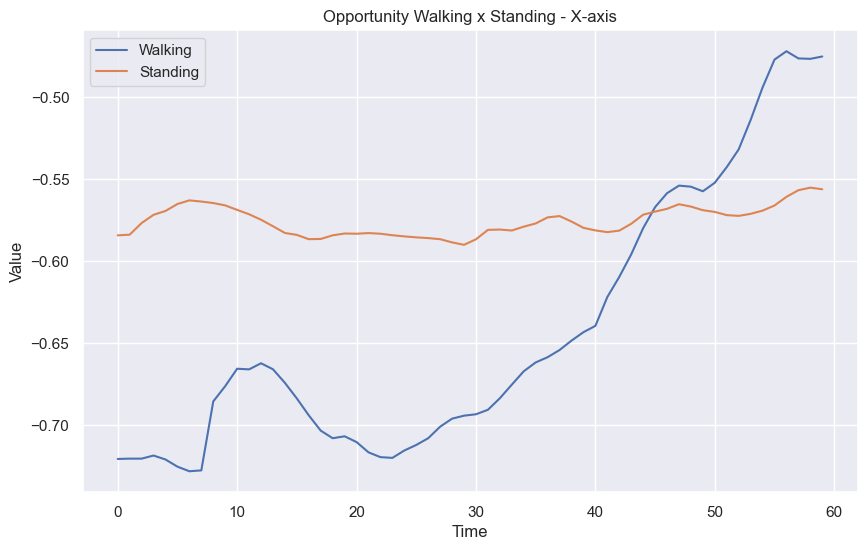

In [76]:
plot_two_time_series(walking_data[x_axis].iloc[start:end].reset_index(drop=True), "Walking", standing_data[x_axis].iloc[start:end].reset_index(drop=True), "Standing", 'Opportunity Walking x Standing - X-axis')

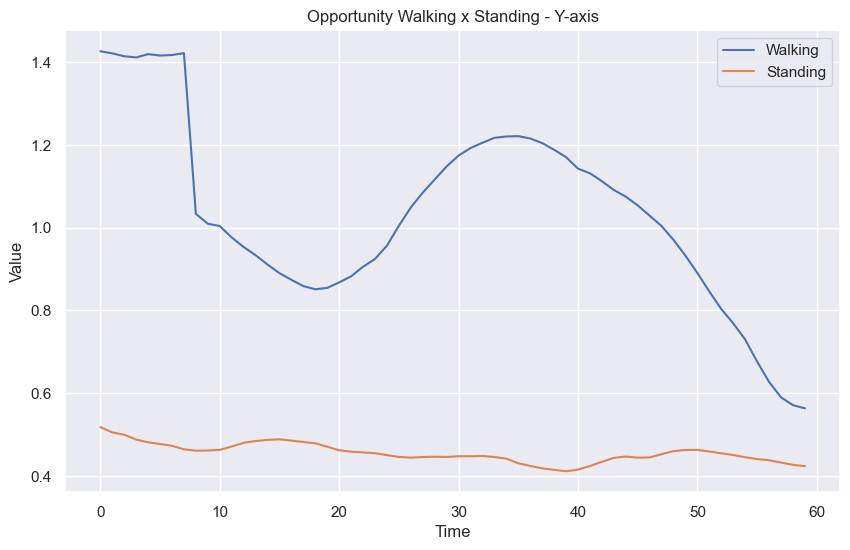

In [77]:
plot_two_time_series(walking_data[y_axis].iloc[start:end].reset_index(drop=True), "Walking", standing_data[y_axis].iloc[start:end].reset_index(drop=True), "Standing", 'Opportunity Walking x Standing - Y-axis')

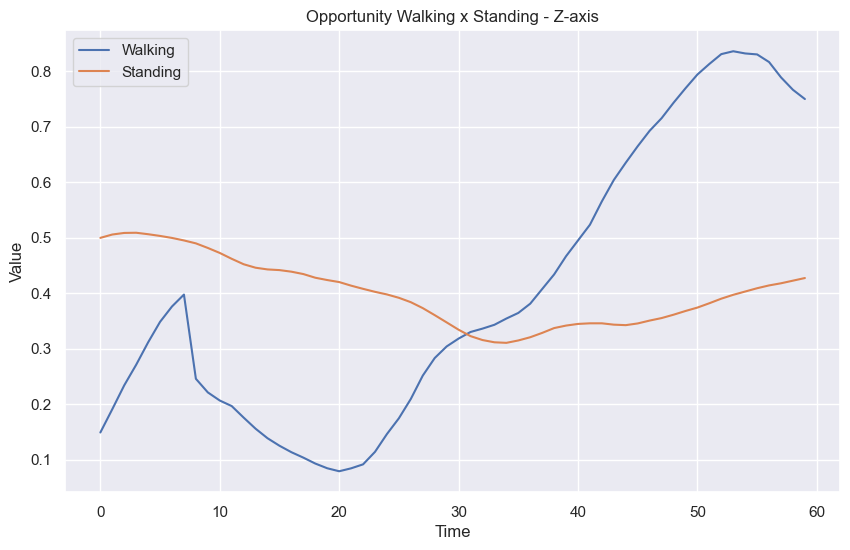

In [78]:
plot_two_time_series(walking_data[z_axis].iloc[start:end].reset_index(drop=True), "Walking", standing_data[z_axis].iloc[start:end].reset_index(drop=True), "Standing", 'Opportunity Walking x Standing - Z-axis')

### Recurrence Plots - Axis

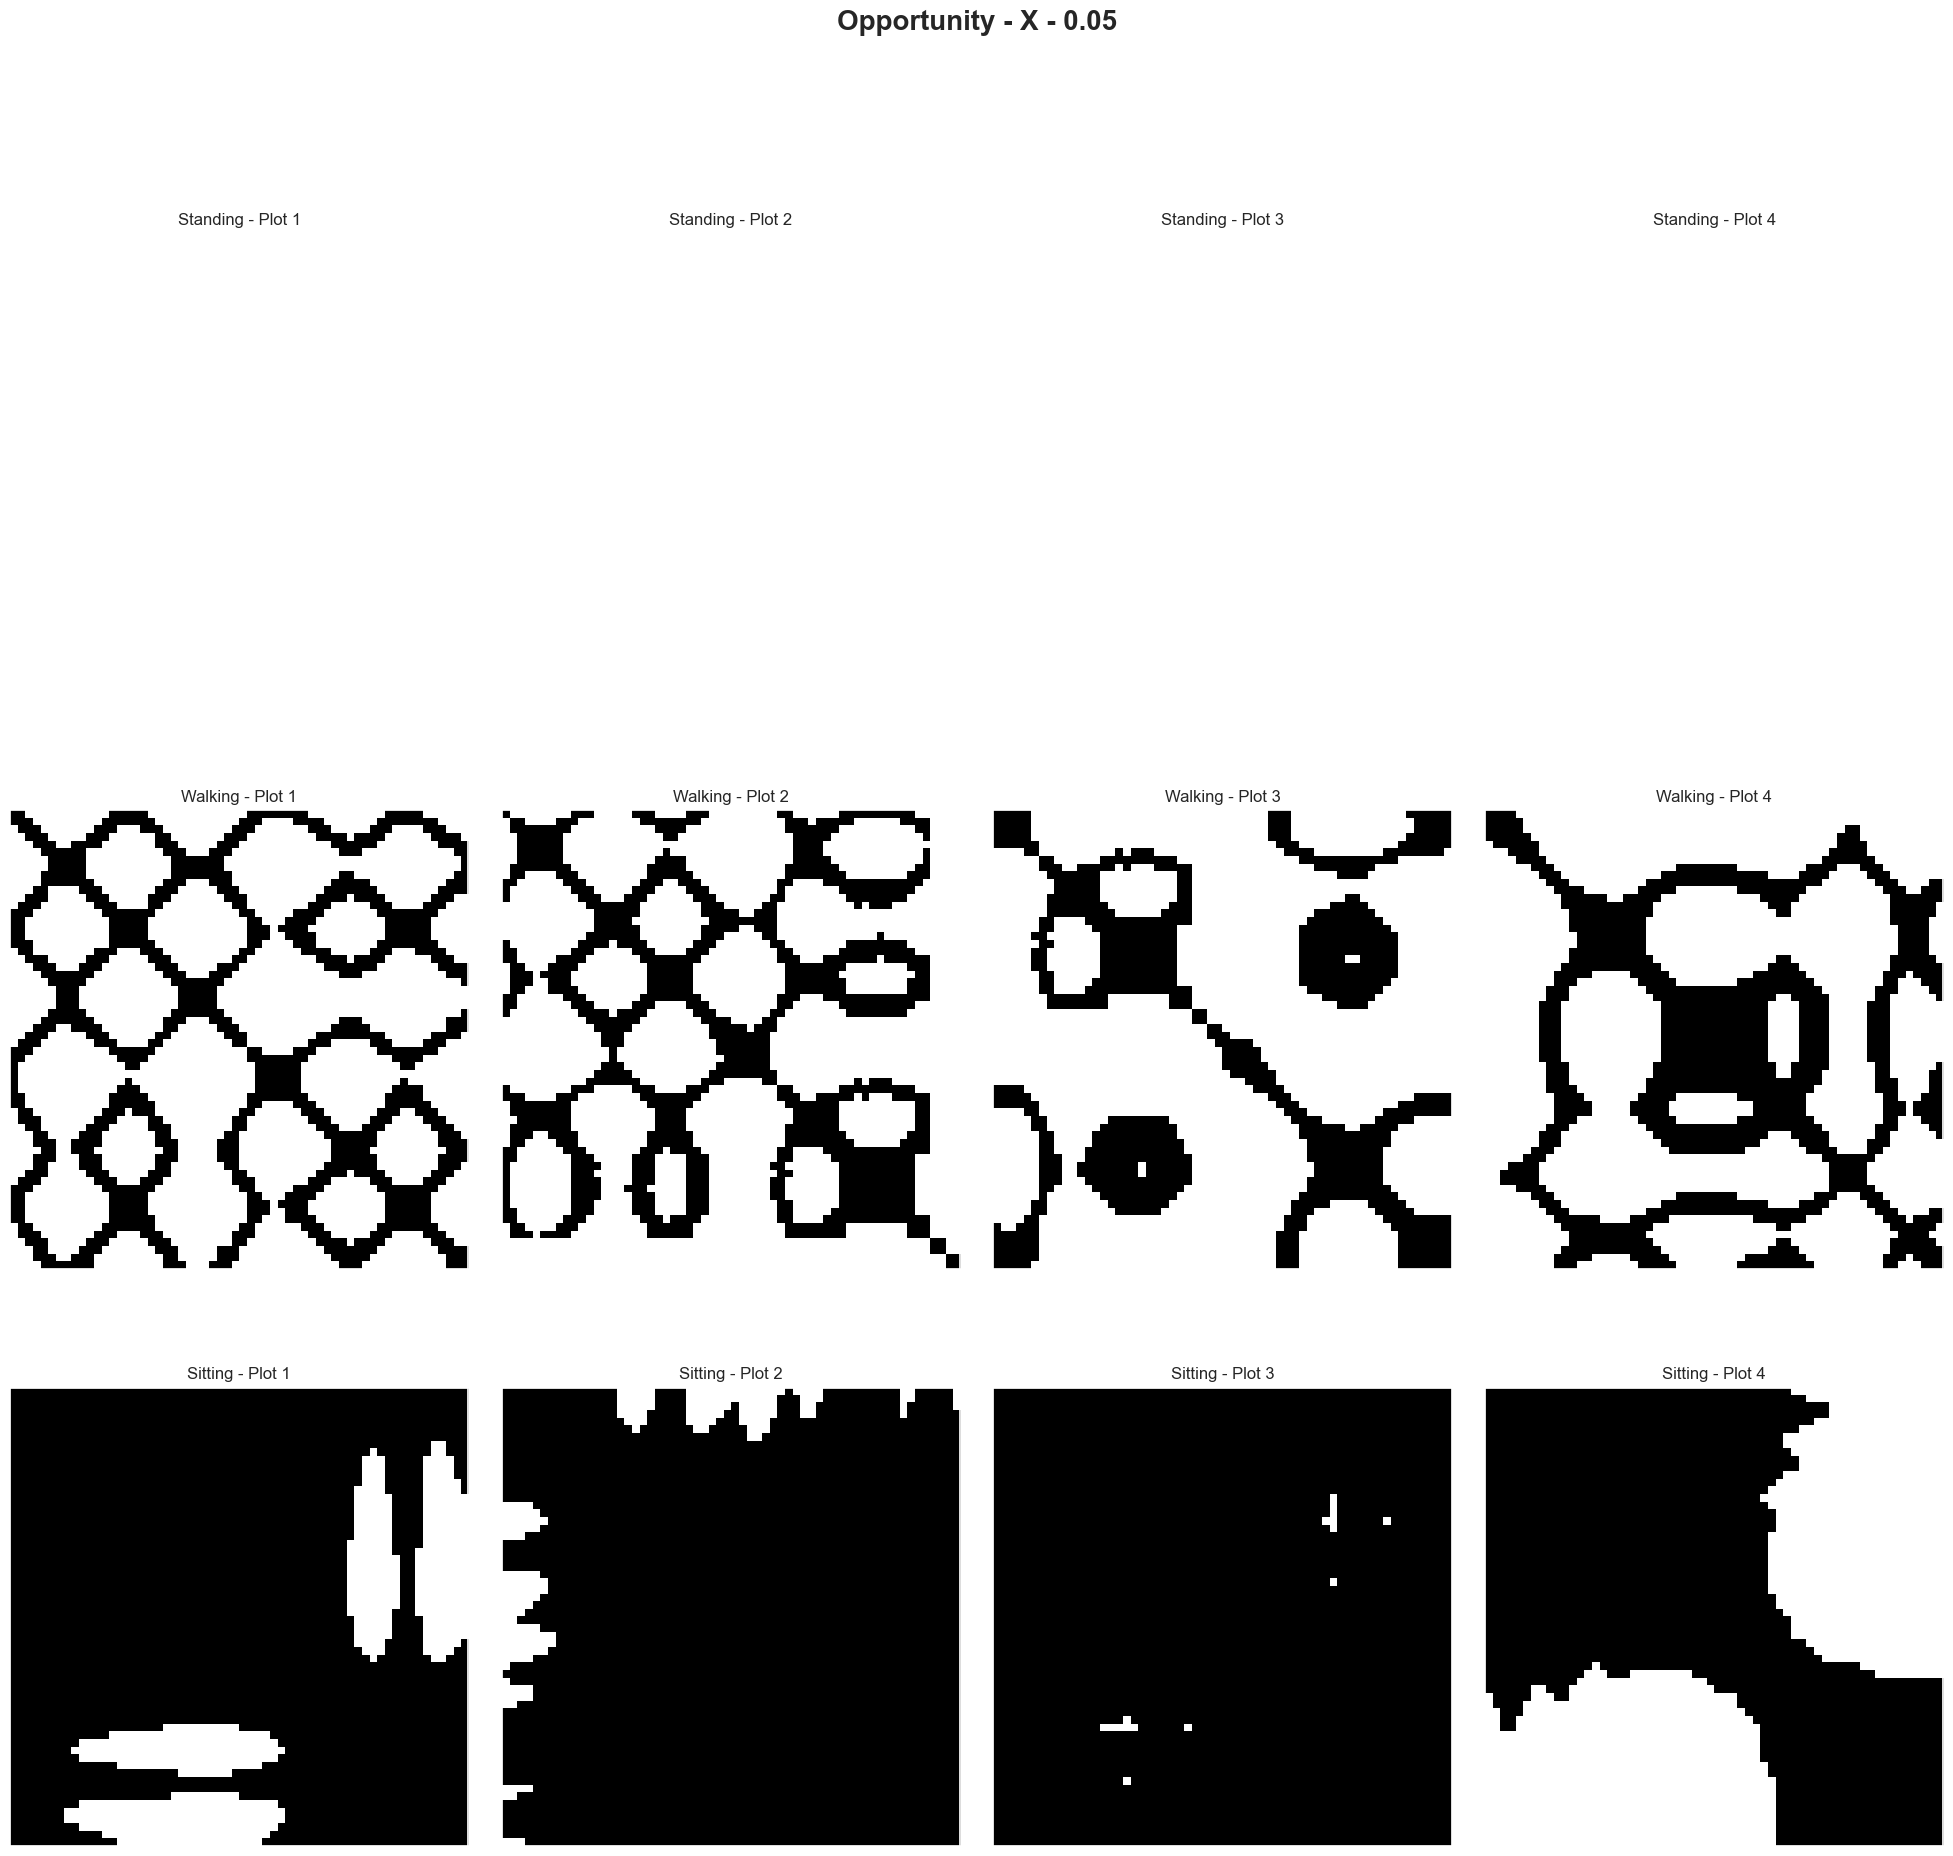

In [79]:
data = {"Standing": standing_data[x_axis].to_numpy(), "Walking": walking_data[x_axis].to_numpy(), "Sitting": sitting_data[x_axis].to_numpy()}

plot_recurrence_by_activity(data, "Opportunity", "X",threshold_vector, step=60, first=560)

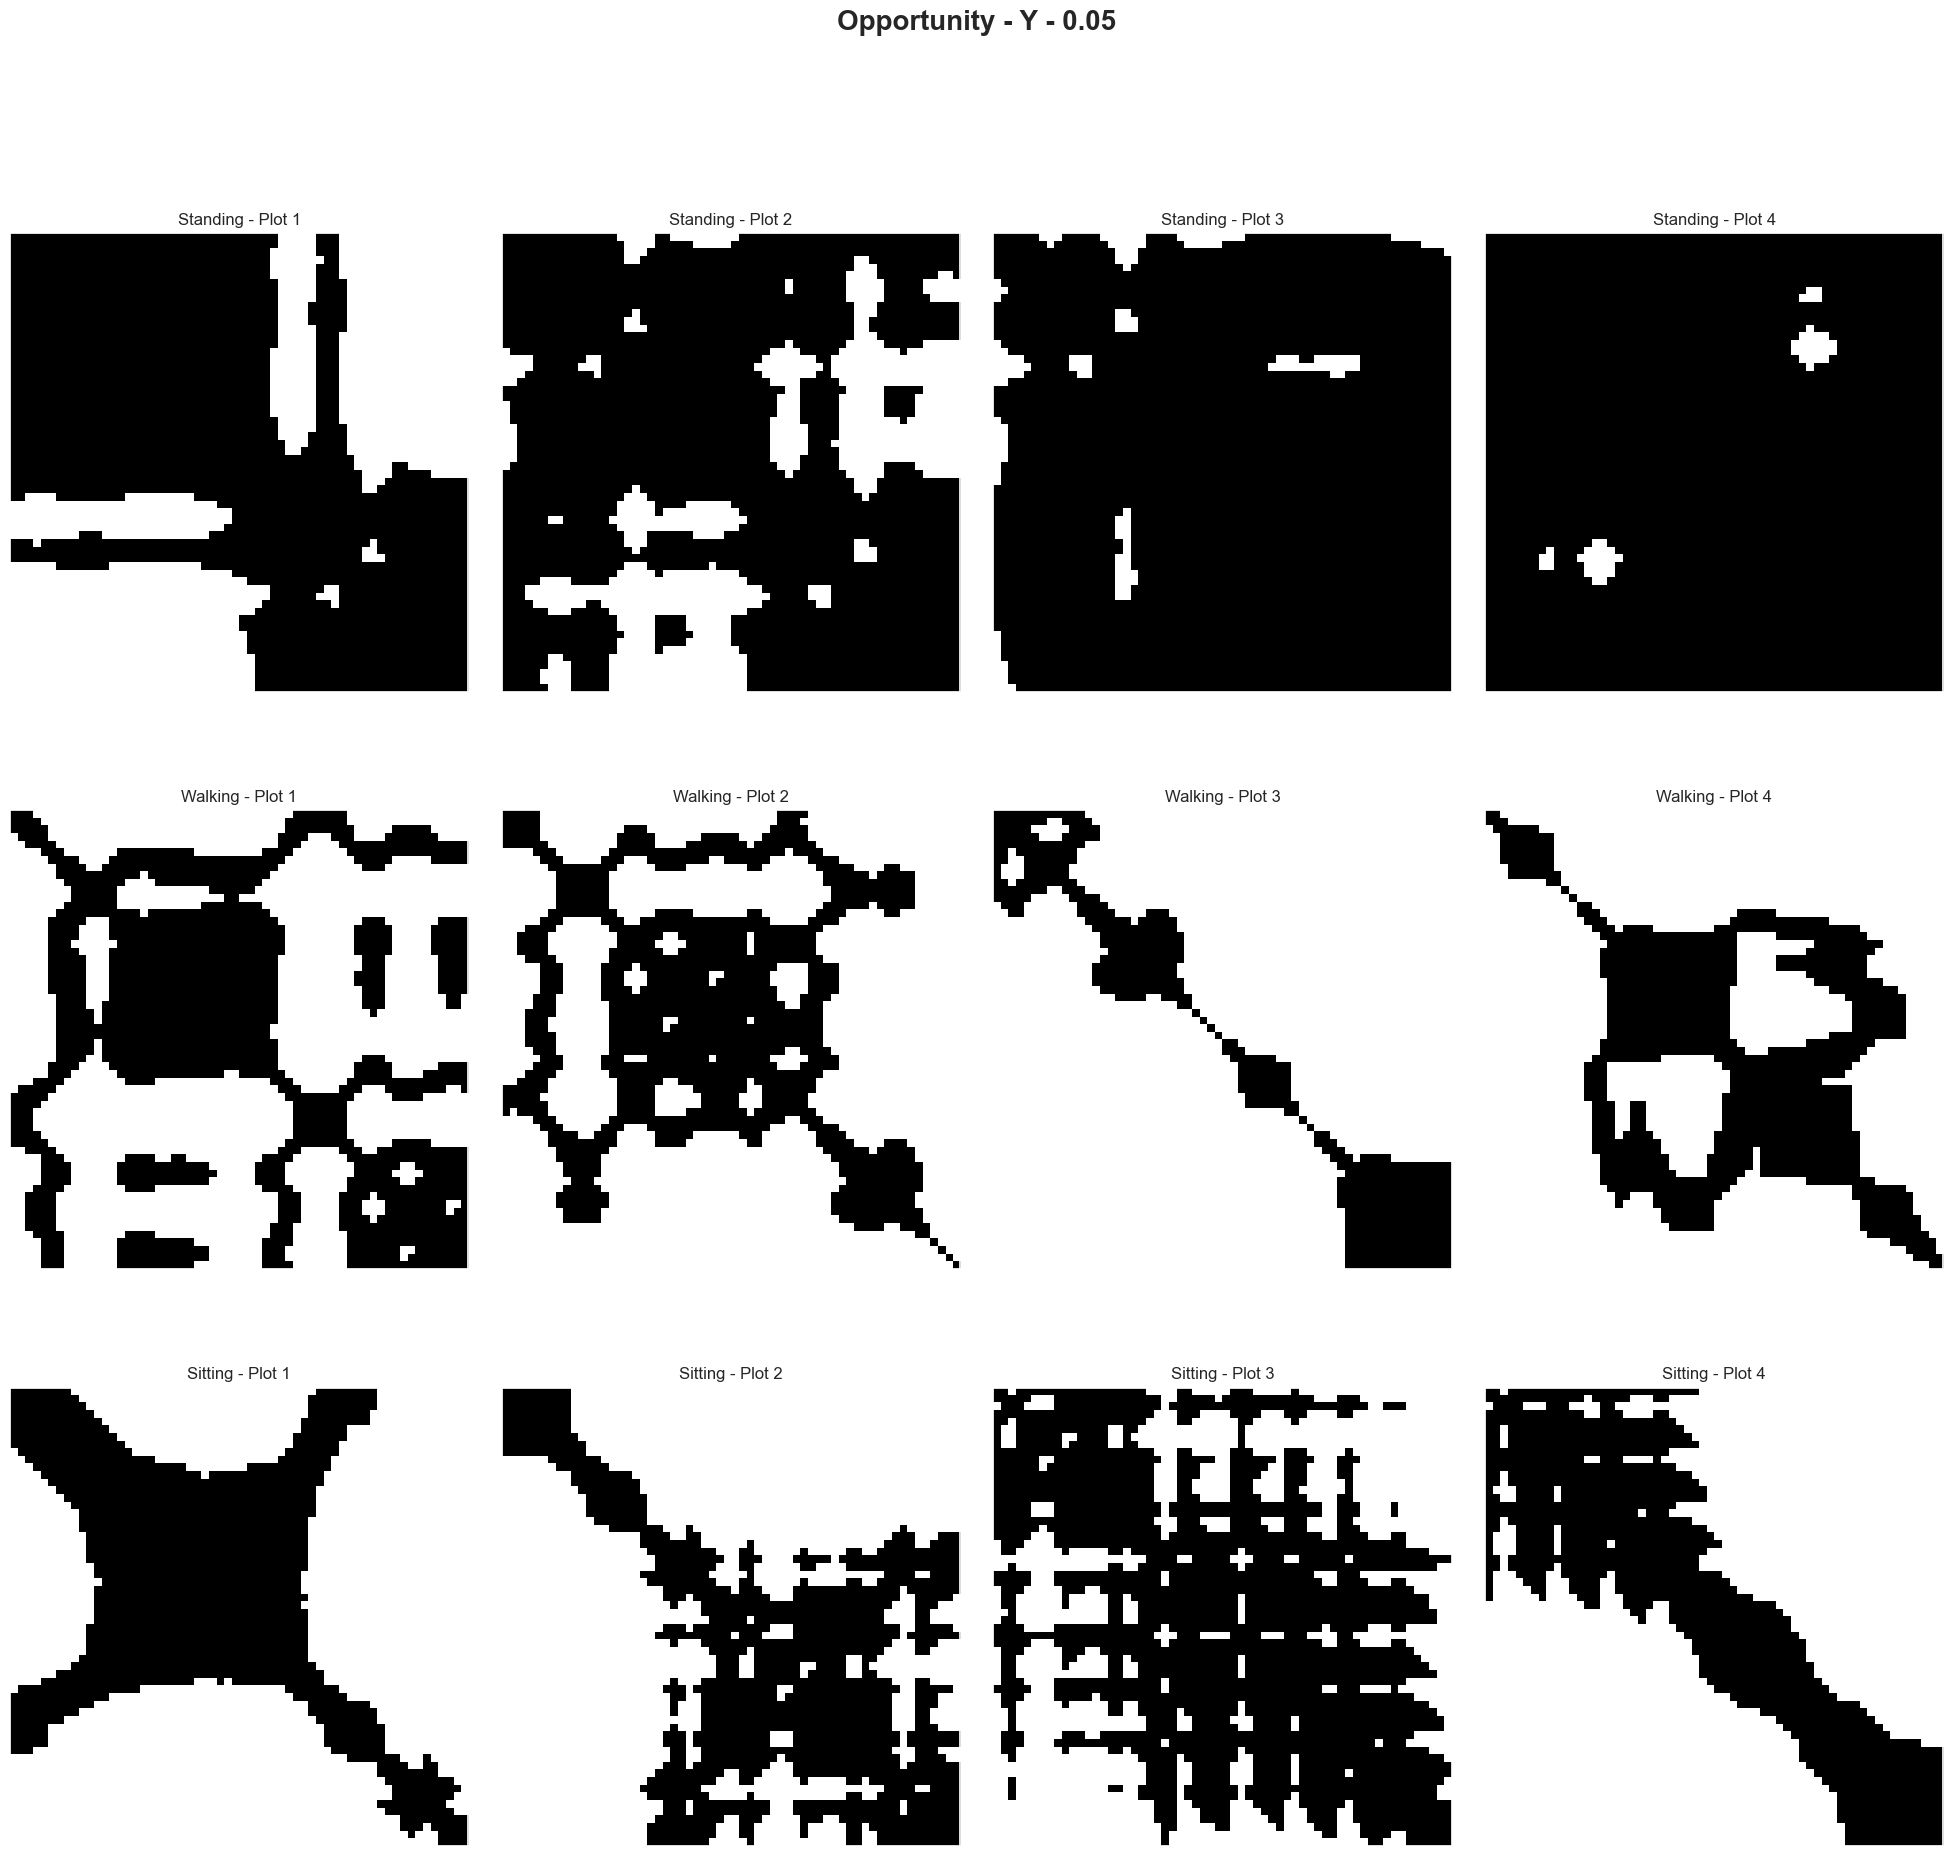

In [80]:
data = {"Standing": standing_data[y_axis].to_numpy(), "Walking": walking_data[y_axis].to_numpy(), "Sitting": sitting_data[y_axis].to_numpy()}

plot_recurrence_by_activity(data, "Opportunity", "Y",threshold_vector, step=60, first=560)

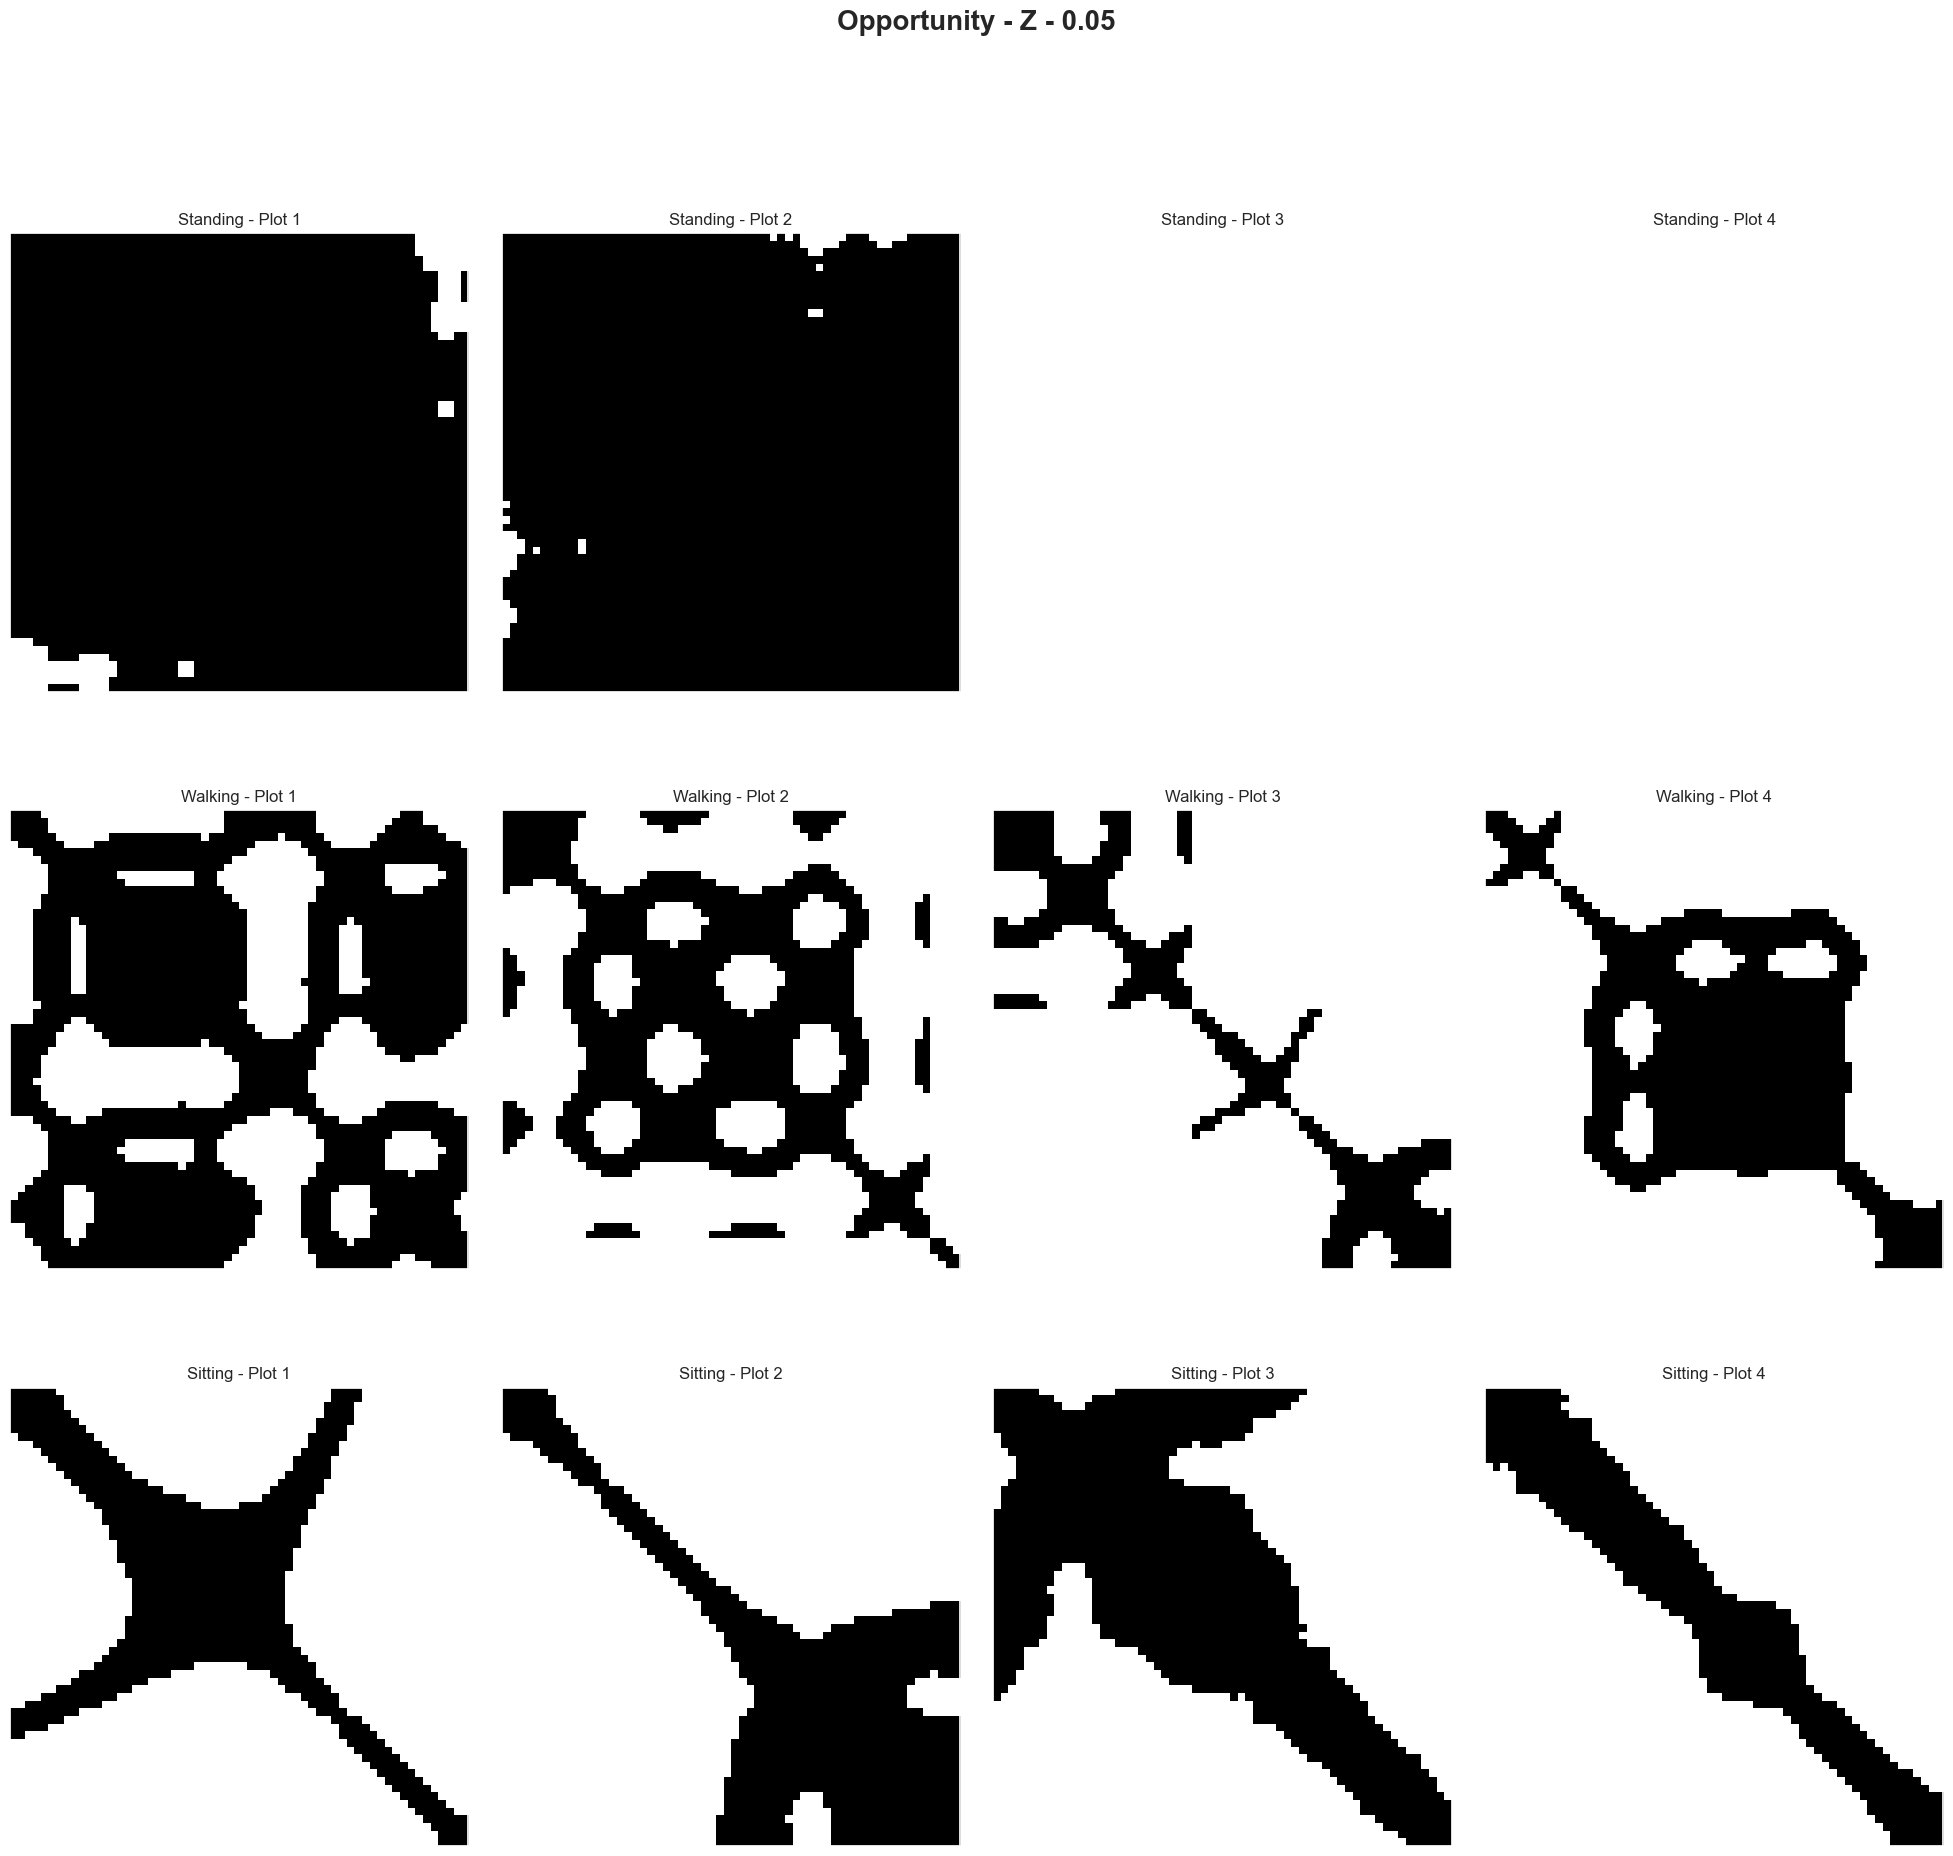

In [81]:
data = {"Standing": standing_data[z_axis].to_numpy(), "Walking": walking_data[z_axis].to_numpy(), "Sitting": sitting_data[z_axis].to_numpy()}

plot_recurrence_by_activity(data, "Opportunity", "Z",threshold_vector, step=60, first=560)

### Recurrence Plots - Vector

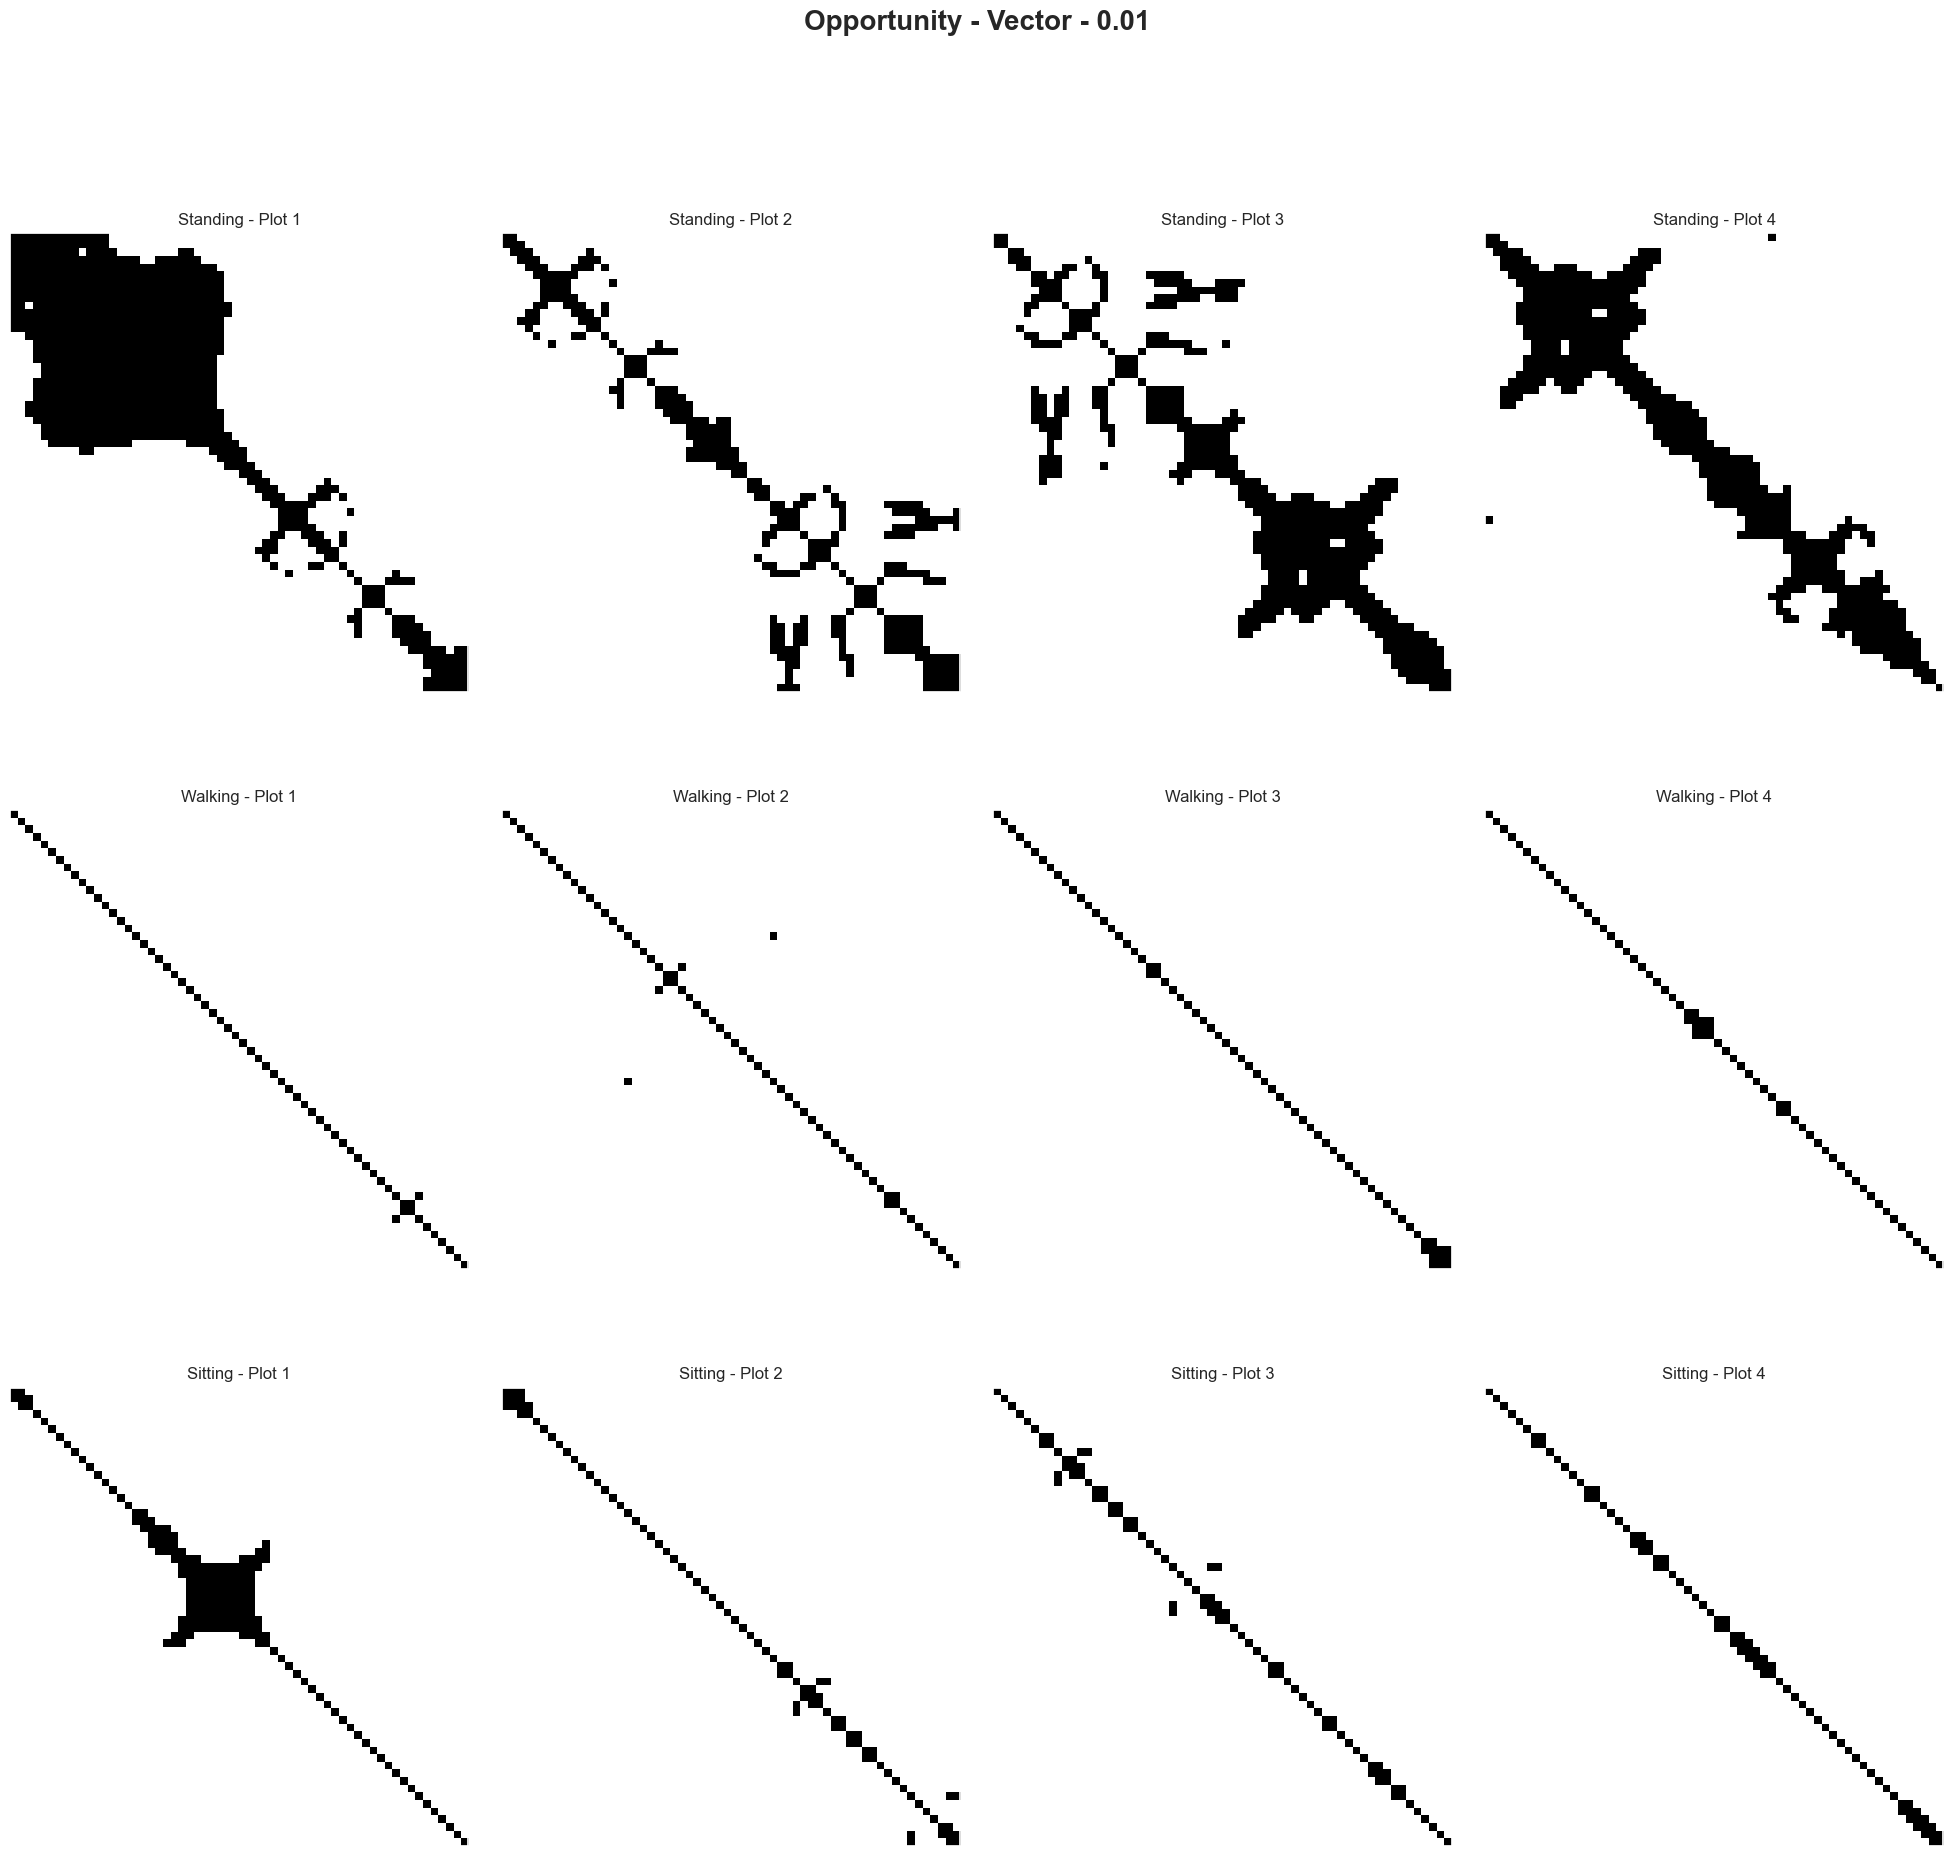

In [82]:
data = {"Standing": standing_vectors, "Walking": walking_vectors, "Sitting": sitting_vectors}

plot_recurrence_by_activity(data,"Opportunity", "Vector",  0.01, step=60, first=560)

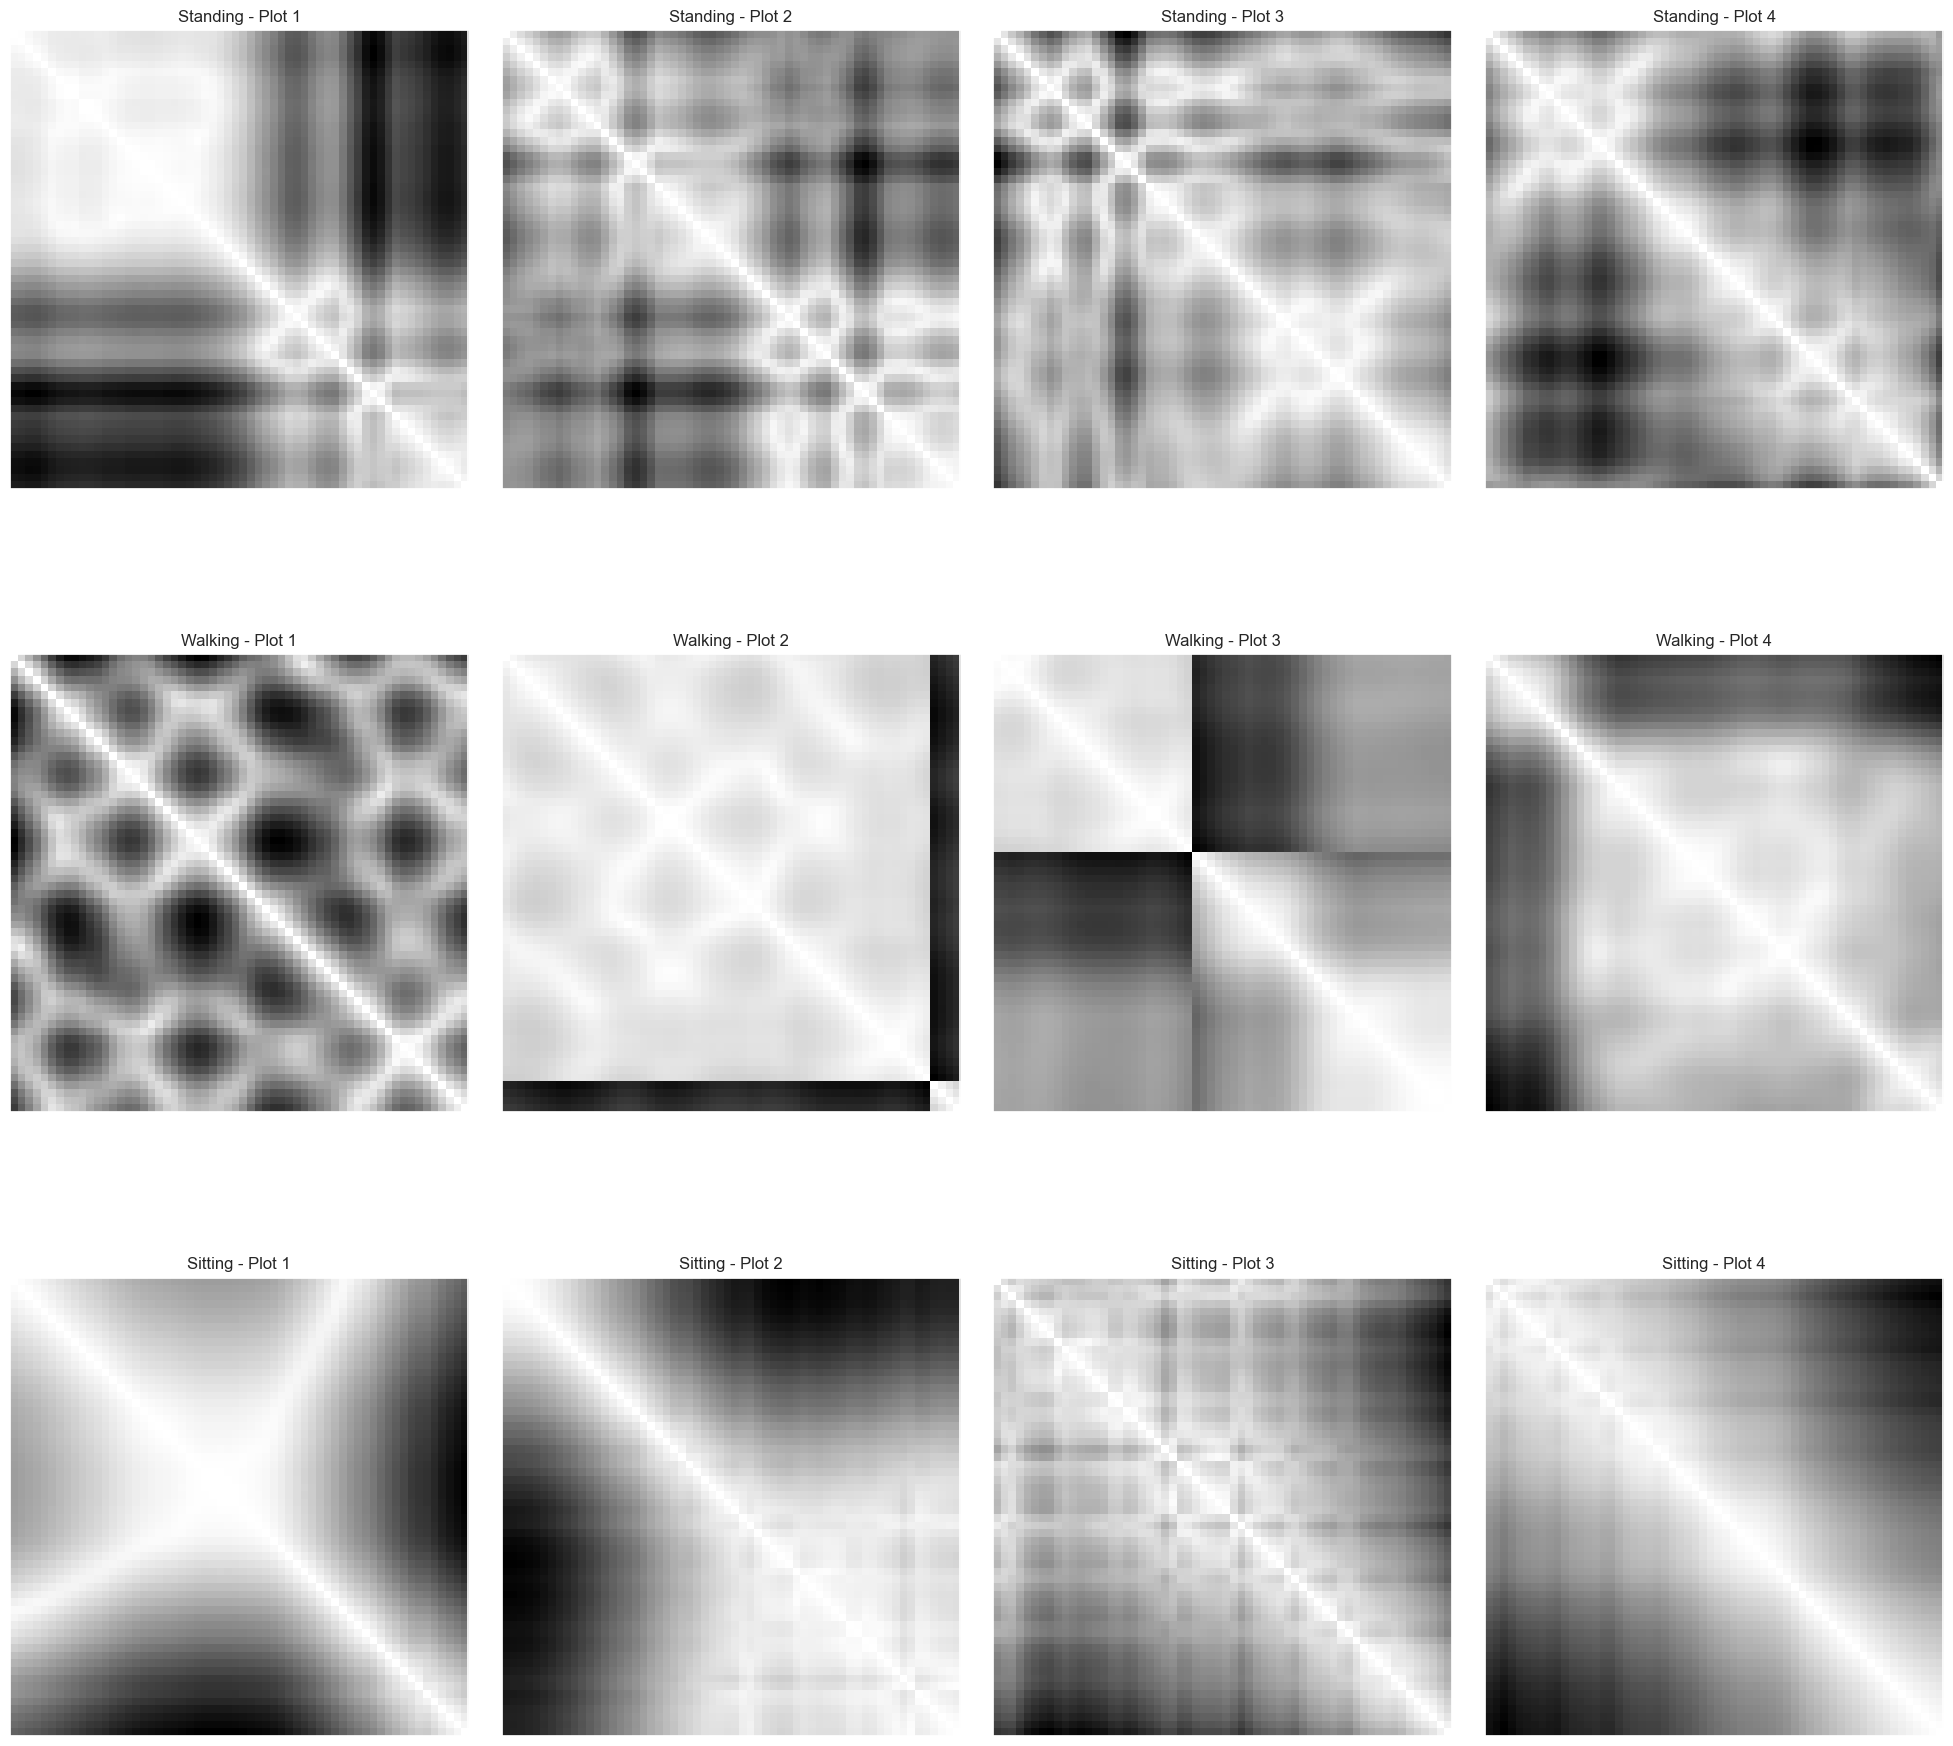

In [83]:
data = {"Standing": standing_vectors, "Walking": walking_vectors, "Sitting": sitting_vectors}

plot_recurrence_by_activity_grayscale(data, bins=256, step=60, first=560)

### Distance Analysis

In [136]:
walking_distances = calculate_distances_in_batches(walking_vectors)
sitting_distances = calculate_distances_in_batches(sitting_vectors)
standing_distances = calculate_distances_in_batches(standing_vectors)

distances = np.concatenate((walking_distances, sitting_distances, standing_distances))
len(distances)

10476803

In [137]:
distances = distances[~np.isnan(distances)]
len(distances)

10476803

In [138]:
# Calculate Z-scores
z_scores = np.abs(stats.zscore(distances))

# Define threshold for identifying outliers (commonly 3)
threshold = 3

# Filter out the outliers
filtered_distances = distances[z_scores < threshold]

len(filtered_distances), max(filtered_distances), min(filtered_distances)

(10201939, 2.0125998033356085, 0.0)

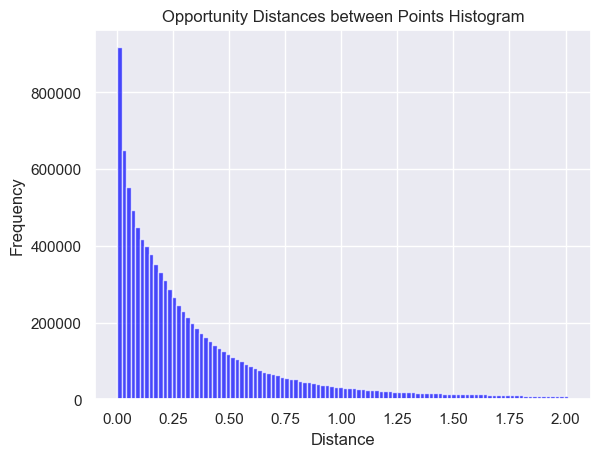

In [139]:
plt.hist(filtered_distances, bins=100, color='blue', alpha=0.7)

# Set y-axis to log scale

# Add title and labels
plt.title('Opportunity Distances between Points Histogram')
plt.xlabel('Distance')
plt.ylabel('Frequency')

# Show the plot
plt.show()

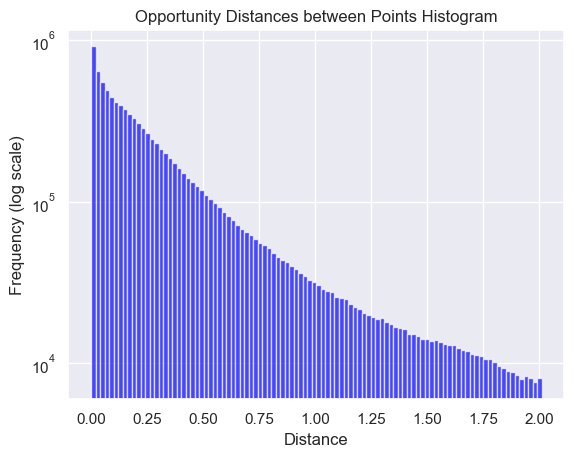

In [140]:
plt.hist(filtered_distances, bins=100, color='blue', alpha=0.7)

# Set y-axis to log scale
plt.yscale('log')

# Add title and labels
plt.title('Opportunity Distances between Points Histogram')
plt.xlabel('Distance')
plt.ylabel('Frequency (log scale)')

# Show the plot
plt.show()

In [141]:
NUMBER_OF_THRESHOLDS = 50
MIN_THRESHOLD = 0.00001
MAX_THRESHOLD = 1.5
t = np.linspace(MIN_THRESHOLD, 1, NUMBER_OF_THRESHOLDS)

threshold_list_linear = t * MAX_THRESHOLD
threshold_list_linear = threshold_list_linear.round(4)
threshold_list_linear

threshold_list = (t ** 3) * MAX_THRESHOLD
threshold_list = threshold_list.round(4)
threshold_list

array([0.0000e+00, 0.0000e+00, 1.0000e-04, 3.0000e-04, 8.0000e-04,
       1.6000e-03, 2.8000e-03, 4.4000e-03, 6.5000e-03, 9.3000e-03,
       1.2800e-02, 1.7000e-02, 2.2000e-02, 2.8000e-02, 3.5000e-02,
       4.3000e-02, 5.2200e-02, 6.2600e-02, 7.4400e-02, 8.7500e-02,
       1.0200e-01, 1.1810e-01, 1.3580e-01, 1.5510e-01, 1.7630e-01,
       1.9920e-01, 2.2410e-01, 2.5100e-01, 2.7990e-01, 3.1100e-01,
       3.4430e-01, 3.7980e-01, 4.1780e-01, 4.5820e-01, 5.0110e-01,
       5.4670e-01, 5.9490e-01, 6.4580e-01, 6.9960e-01, 7.5630e-01,
       8.1600e-01, 8.7870e-01, 9.4460e-01, 1.0137e+00, 1.0861e+00,
       1.1618e+00, 1.2410e+00, 1.3237e+00, 1.4100e+00, 1.5000e+00])

### Entropy and Threshold Calculation

In [49]:
# best_walking, dict_entropies_walking = find_best_threshold(recurrence_plot_vector, threshold_list, walking_vectors, window_size=60, step=60, start=100)
# print(f"Walking: {best_walking} | Entropy: {dict_entropies_walking[best_walking]}")
# best_standing, dict_entropies_standing = find_best_threshold(recurrence_plot_vector, threshold_list, standing_vectors, window_size=60, step=60, start=100)
# print(f"Standing: {best_standing} | Entropy: {dict_entropies_standing[best_standing]}")
# best_sitting, dict_entropies_sitting = find_best_threshold(recurrence_plot_vector, threshold_list, sitting_vectors, window_size=60, step=60, start=100)
# print(f"Sitting: {best_sitting} | Entropy: {dict_entropies_sitting[best_sitting]}")

Walking: 0.1866 | Entropy: 0.9368469118616104
Standing: 0.0044 | Entropy: 0.8616459362121602
Sitting: 0.0029 | Entropy: 0.9028656681189409


In [50]:
# determinants_walking = find_determinants(recurrence_matrix_vector, walking_vectors, window_size=60, step=60, start=100)
# print(f"Mean Determinant Walking: {np.mean(determinants_walking)}")
# determinants_standing = find_determinants(recurrence_matrix_vector, standing_vectors, window_size=60, step=60, start=100)
# print(f"Mean Determinant Standing: {np.mean(determinants_standing)}")
# determinants_sitting = find_determinants(recurrence_matrix_vector, sitting_vectors, window_size=60, step=60, start=100)
# print(f"Mean Determinant Sitting: {np.mean(determinants_sitting)}")

Mean Determinant Walking: -5.838284719142236e-58
Mean Determinant Standing: -9.767320437217097e-150
Mean Determinant Sitting: -2.7448745931832714e-159


In [ ]:
results = {}
for i_threshold in threshold_list:    
    # Initialize a sub-dictionary for each threshold
    results[i_threshold] = {
        'Mean Laminarity Walking': None,
        'Mean Laminarity Standing': None,
        'Mean Laminarity Sitting': None,
    }
    
    laminarities_walking = find_laminarities(recurrence_plot_vector, i_threshold, walking_vectors, window_size=60, step=60, start=100, min_line_length=3)
    mean_laminarity_walking = np.mean(laminarities_walking)
    results[i_threshold]['Mean Laminarity Walking'] = mean_laminarity_walking

    laminarities_standing = find_laminarities(recurrence_plot_vector, i_threshold, standing_vectors, window_size=60, step=60, start=100, min_line_length=3)
    mean_laminarity_standing = np.mean(laminarities_standing)
    results[i_threshold]['Mean Laminarity Standing'] = mean_laminarity_standing

    laminarities_sitting = find_laminarities(recurrence_plot_vector, i_threshold, sitting_vectors, window_size=60, step=60, start=100, min_line_length=3)
    mean_laminarity_sitting = np.mean(laminarities_sitting)
    results[i_threshold]['Mean Laminarity Sitting'] = mean_laminarity_sitting

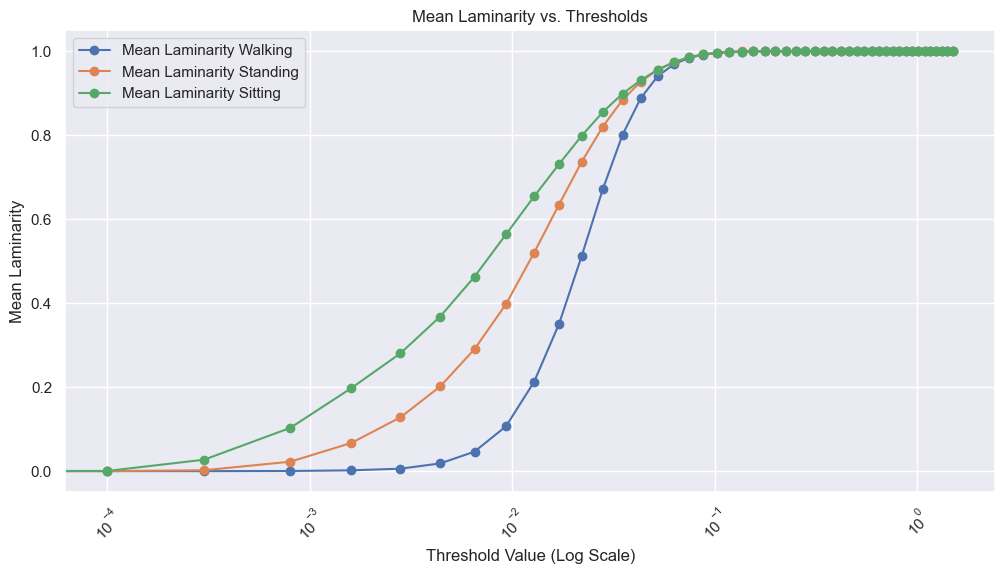

In [143]:
plot_laminarities(results)

### Plots Generation

In [92]:
# data_x = {"Standing": standing_data[x_axis].to_numpy(), "Walking": walking_data[x_axis].to_numpy(), "Sitting": sitting_data[x_axis].to_numpy()}
# data_y = {"Standing": standing_data[y_axis].to_numpy(), "Walking": walking_data[y_axis].to_numpy(), "Sitting": sitting_data[y_axis].to_numpy()}
# data_z = {"Standing": standing_data[z_axis].to_numpy(), "Walking": walking_data[z_axis].to_numpy(), "Sitting": sitting_data[z_axis].to_numpy()}
# data_vectors = {"Standing": standing_vectors, "Walking": walking_vectors, "Sitting": sitting_vectors, "Jogging": jogging_vectors}

# #RELATIVE_PATH = "../../results/recurrence_plots_wisdm/"
# RELATIVE_PATH = "C:/Users/tulio/Downloads/Plots/Opportunity/"
# dataset_name = "Opportunity"

# for i in range(len(threshold_list)):
#     plot_recurrence_by_activity(data_x, dataset_name, "X", threshold_list[i], step=40, first=200, filename=f"{RELATIVE_PATH}X/recurrence_wisdm_x_{i}-{str(threshold_list[i])}")
#     plot_recurrence_by_activity(data_y, dataset_name, "Y", threshold_list[i], step=40, first=200, filename=f"{RELATIVE_PATH}Y/recurrence_wisdm_y_{i}-{str(threshold_list[i])}")
#     plot_recurrence_by_activity(data_z, dataset_name, "Z", threshold_list[i], step=40, first=200, filename=f"{RELATIVE_PATH}Z/recurrence_wisdm_z_{i}-{str(threshold_list[i])}")
#     plot_recurrence_by_activity(data_vectors, dataset_name, "Vector", threshold_list[i], step=40, first=200, filename=f"{RELATIVE_PATH}Vector/recurrence_wisdm_vector_{i}-{str(threshold_list[i])}")
    

# Clemson

### Dataset Preparation

In [93]:
DATASET_NAME = 'CLEMSON'
RELATIVE_PATH = "C:/Users/tulio/Downloads/Plots/CLEMSON"
CLEMSON_HZ = 15
WINDOW_SIZE = 2
CLEMSON_START = int(WINDOW_SIZE * CLEMSON_HZ * 3)

In [94]:
# Function to normalize columns
def normalize_group(group):
    group[['acc_x', 'acc_y', 'acc_z']] = (group[['acc_x', 'acc_y', 'acc_z']] - group[['acc_x', 'acc_y', 'acc_z']].mean()) / group[['acc_x', 'acc_y', 'acc_z']].std()
    return group

clemson = pd.read_csv('../../datasets/combined_clemson_cafeteria_data.csv', sep=',')
clemson = clemson.groupby('user_id').apply(normalize_group)
clemson = clemson.reset_index(drop=True)
clemson

C:\Users\tulio\AppData\Local\Temp\ipykernel_12564\2720396042.py:7: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  clemson = clemson.groupby('user_id').apply(normalize_group)


,acc_x,acc_y,acc_z,gyr_x,gyr_y,gyr_z,grams,user_id,course,index,activity
0,-3.085053,0.320500,1.546433,65.232882,23.322505,46.738401,828.7,p005,c1,0,other
1,-1.352689,0.644117,1.694550,49.632882,-5.077495,23.938401,828.7,p005,c1,1,other
2,-2.061384,0.666283,1.550436,38.432882,-7.477495,17.938401,828.7,p005,c1,2,other
3,-1.875774,0.555455,1.550436,38.832882,-9.877495,18.738401,828.7,p005,c1,3,other
4,-1.650791,0.608652,1.538425,37.632882,-11.477495,19.138401,828.9,p005,c1,4,other
...,...,...,...,...,...,...,...,...,...,...,...
6367686,1.002466,1.319254,-0.738028,-5.460823,-30.588564,4.409891,826.2,p413,c1,17222,other
6367687,1.292543,1.319254,-0.794111,-5.060823,-19.388564,4.809891,826.3,p413,c1,17223,other
6367688,1.135212,1.482701,-0.797229,-12.660823,-12.988564,0.809891,826.3,p413,c1,17224,other
6367689,1.194212,1.610620,-0.903168,-10.260823,-14.188564,1.209891,826.3,p413,c1,17225,other


In [95]:
clemson[['x_maf', 'y_maf', 'z_maf']] = clemson.groupby('user_id')[['acc_x', 'acc_y', 'acc_z']].rolling(window=CLEMSON_HZ).mean().reset_index(drop=True)
clemson[['x_ema', 'y_ema', 'z_ema']] = clemson.groupby('user_id')[['acc_x', 'acc_y', 'acc_z']].ewm(span=1.5*CLEMSON_HZ, adjust=False).mean().reset_index(drop=True)

In [96]:
bite_data = clemson[(clemson['activity'] == 'bite') & (clemson['user_id'] == 'p006')]
bite_vectors = bite_data[[x_axis, y_axis, z_axis]].to_numpy()

rest_data = clemson[(clemson['activity'] == 'rest') & (clemson['user_id'] == 'p006')]
rest_vectors = rest_data[[x_axis, y_axis, z_axis]].to_numpy()

drink_data = clemson[(clemson['activity'] == 'drink') & (clemson['user_id'] == 'p006')]
drink_vectors = drink_data[[x_axis, y_axis, z_axis]].to_numpy()

other_data = clemson[(clemson['activity'] == 'other') & (clemson['user_id'] == 'p006')]
other_vectors = other_data[[x_axis, y_axis, z_axis]].to_numpy()

print(len(bite_vectors)), print(len(rest_vectors)), print(len(drink_vectors)), print(len(other_vectors))

2536
5710
1343
9571


(None, None, None, None)

### Distance Analysis

In [97]:
bite_distances = calculate_distances_in_batches(bite_vectors, batch_size=CLEMSON_HZ*WINDOW_SIZE)
rest_distances = calculate_distances_in_batches(rest_vectors, batch_size=CLEMSON_HZ*WINDOW_SIZE)
drink_distances = calculate_distances_in_batches(drink_vectors, batch_size=CLEMSON_HZ*WINDOW_SIZE)
other_distances = calculate_distances_in_batches(other_vectors, batch_size=CLEMSON_HZ*WINDOW_SIZE)

distances = np.concatenate((bite_distances, rest_distances, drink_distances, other_distances))
len(distances)

574186

In [98]:
# Calculate Z-scores
z_scores = np.abs(stats.zscore(distances))

# Define threshold for identifying outliers (commonly 3)
threshold = 3

# Filter out the outliers
filtered_distances = distances[z_scores < threshold]

len(filtered_distances), max(filtered_distances), min(filtered_distances)

ValueError: max() arg is an empty sequence

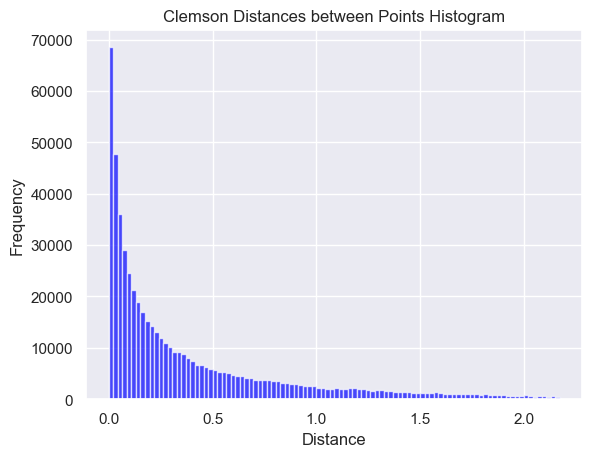

In [607]:
plt.hist(filtered_distances, bins=100, color='blue', alpha=0.7)

# Set y-axis to log scale

# Add title and labels
plt.title('Clemson Distances between Points Histogram')
plt.xlabel('Distance')
plt.ylabel('Frequency')

# Show the plot
plt.show()

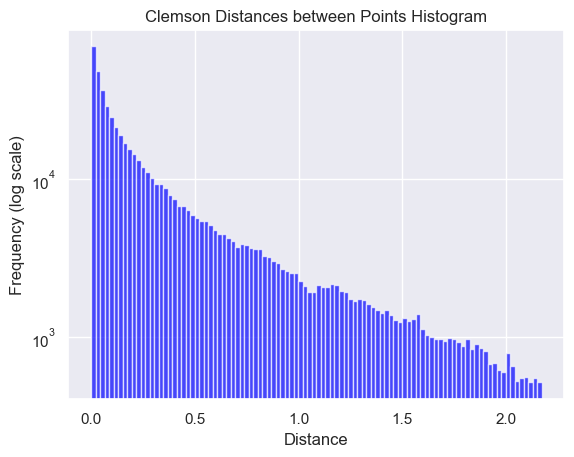

In [608]:
plt.hist(filtered_distances, bins=100, color='blue', alpha=0.7)

# Set y-axis to log scale
plt.yscale('log')

# Add title and labels
plt.title('Clemson Distances between Points Histogram')
plt.xlabel('Distance')
plt.ylabel('Frequency (log scale)')

# Show the plot
plt.show()